In [ ]:
!pip install monai nibabel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 23.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Update ROOT_DIR to: /content/drive/MyDrive/path/to/Custom_Dataset

Mounted at /content/drive


In [ ]:
import os
#ok

# === USER CONFIGURATION ===
# Path to the zip file inside your Google Drive
# Example: If your file is in a folder called 'Thesis', it might be:
# "/content/drive/MyDrive/Thesis/Custom_Dataset.zip"
DRIVE_ZIP_PATH = "/content/drive/MyDrive/ADNI.zip"

# Where you want to extract it in Colab (Local Disk)
EXTRACT_PATH = "/content/ADNI"
# ==========================

# 2. Check if file exists
if not os.path.exists(DRIVE_ZIP_PATH):
    print(f"ERROR: File not found at {DRIVE_ZIP_PATH}")
    print("Please check the path. Note: spaces in folder names need exact matching.")
else:
    print(f"Found zip file at: {DRIVE_ZIP_PATH}")

    # 3. Copy to local disk (Optimizes speed)
    print("Copying zip to local Colab disk (this speeds up unzipping)...")
    !cp "{DRIVE_ZIP_PATH}" /content/temp_dataset.zip

    # 4. Unzip
    print(f"Unzipping to {EXTRACT_PATH}...")
    # -q = quiet (don't print every filename), -d = destination folder
    !unzip -q /content/temp_dataset.zip -d "{EXTRACT_PATH}"

    # 5. Cleanup (Remove the zip to save space)
    !rm /content/temp_dataset.zip

    print("\nSUCCESS! Dataset ready.")

    # 6. Verify structure
    print("Folder structure:")
    !ls -R "{EXTRACT_PATH}" | head -n 20

Found zip file at: /content/drive/MyDrive/ADNI.zip
Copying zip to local Colab disk (this speeds up unzipping)...
^C
Unzipping to /content/ADNI...
[/content/temp_dataset.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/temp_dataset.zip or
        /content/temp_dataset.zip.zip, and cannot find /content/temp_dataset.zip.ZIP, period.

SUCCESS! Dataset ready.
Folder structure:
ls: cannot access '/content/ADNI': No such file or directory


In [ ]:
import os
import zipfile
from google.colab import drive


# === CONFIG ===
DRIVE_ZIP_PATH = "/content/drive/MyDrive/ADNI.zip"  # Your zip in Drive
DRIVE_EXTRACT_PATH = "/content/ADNI_dataset"  # Extract here in Drive

# 1. Check if zip exists
if not os.path.exists(DRIVE_ZIP_PATH):
    print(f"❌ ERROR: {DRIVE_ZIP_PATH} not found!")
    print("Check path. Example: '/content/drive/MyDrive/Thesis/ADNI.zip'")
else:
    print(f"✅ Found: {DRIVE_ZIP_PATH}")

    # 2. Extract DIRECTLY to Drive (no local copy!)
    print("Extracting directly to Google Drive...")

    with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DRIVE_EXTRACT_PATH)

    print(f"✅ Extracted to: {DRIVE_EXTRACT_PATH}")


✅ Found: /content/drive/MyDrive/ADNI.zip
Extracting directly to Google Drive...


KeyboardInterrupt: 

In [ ]:
import os
import shutil

# Define paths
SOURCE_DIR = "/content/drive/MyDrive/ADNI_dataset_classification/ADNI"
LOCAL_DIR = "/content/ADNI"

print(f"⏳ Copying data from Drive to Local Disk ({LOCAL_DIR})... This may take 5-10 mins.")

# Create local directory
if not os.path.exists(LOCAL_DIR):
    os.makedirs(LOCAL_DIR)

    # Copy the folder
    # We use system command 'cp' because it's faster than python shutil for drive
    !cp -r "{SOURCE_DIR}"/* "{LOCAL_DIR}"

    print("✅ Copy Complete! Data is now on fast local disk.")
else:
    print("✅ Data already exists locally. Skipping copy.")

⏳ Copying data from Drive to Local Disk (/content/ADNI)... This may take 5-10 mins.
✅ Copy Complete! Data is now on fast local disk.


In [ ]:
import os
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Resized, ToTensord
)

# === CONFIGURATION === ok
IMG_SIZE = (96, 96, 96)
MAX_SEQ_LENGTH = 6
BATCH_SIZE = 4

class LongitudinalADNI(Dataset):
    def __init__(self, csv_file, root_dir, split='Train', transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.split = split

        # Load CSV and filter by split
        df = pd.read_csv(csv_file)
        self.df = df[df['Split'] == split].copy()

        # Diagnosis Mapping
        self.label_map = {'CN': 0, 'MCI': 1, 'AD': 2}

        # Visit Order Mapping
        self.visit_order = {
            'nc': 0, 'sc': 0, 'bl': 0,
            'm06': 6, 'm12': 12, 'm18': 18,
            'm24': 24, 'm36': 36, 'm48': 48,
            'm60': 60, 'm72': 72
        }

        # === OPTIMIZATION: Pre-group Data ===
        # Group by SubjectID once so we don't search the DF in the loop
        self.grouped_data = {
            sub_id: group.sort_values(
                by='Visit',
                key=lambda col: col.map(lambda x: self.visit_order.get(str(x).lower(), 999))
            )
            for sub_id, group in self.df.groupby('SubjectID')
        }
        self.subjects = list(self.grouped_data.keys())

    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):
        sub_id = self.subjects[idx]

        # FAST retrieval from pre-grouped dict
        sub_data = self.grouped_data[sub_id]

        images = []

        # 1. LOAD IMAGES (Deterministic)
        for _, row in sub_data.iterrows():
            img_path = os.path.join(self.root_dir, row['FilePath'])

            if not os.path.exists(img_path):
                continue

            data_dict = {"image": img_path}
            if self.transform:
                try:
                    data_dict = self.transform(data_dict)
                    images.append(data_dict["image"])
                except Exception as e:
                    print(f"Error loading {img_path}: {e}")
                    continue

            if len(images) >= MAX_SEQ_LENGTH:
                break

        # Handle empty
        if len(images) == 0:
            return (torch.zeros((MAX_SEQ_LENGTH, 1, *IMG_SIZE)),
                    torch.tensor(0).long(),
                    torch.tensor(0).long(),
                    torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool))

        # 2. SEQUENCE PADDING
        actual_length = len(images)
        seq_tensor = torch.stack(images) # (Time, C, D, H, W)

        # === FIX: Consistent Augmentation (Your Logic) ===
        if self.split == 'Train':
            # 50% chance to rotate
            if torch.rand(1).item() < 0.5:
                k = torch.randint(1, 4, (1,)).item()
                # Rotate Dims:
                # [3, 4] rotates H/W (Standard "Picture Spin")
                # [2, 4] rotates D/W (Your choice - valid 3D aug)
                seq_tensor = torch.rot90(seq_tensor, k, dims=[3, 4])

        # Pad if needed
        if actual_length < MAX_SEQ_LENGTH:
            pad_size = MAX_SEQ_LENGTH - actual_length
            padding = torch.zeros((pad_size, *seq_tensor.shape[1:]))
            seq_tensor = torch.cat([seq_tensor, padding], dim=0)

        # === CRITICAL RE-ADDITION: Attention Mask ===
        attention_mask = torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool)
        attention_mask[:actual_length] = True

        # 3. LABEL
        last_label_str = sub_data.iloc[actual_length-1]['Diagnosis']
        label = self.label_map.get(last_label_str, 1)

        return (
            seq_tensor,                          # Input
            torch.tensor(label).long(),          # Label
            torch.tensor(actual_length).long(),  # Length
            attention_mask                       # Mask (CRITICAL)
        )

# === TRANSFORMS ===
train_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityd(keys=["image"]),
    Resized(keys=["image"], spatial_size=IMG_SIZE),
    ToTensord(keys=["image"])
])

val_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityd(keys=["image"]),
    Resized(keys=["image"], spatial_size=IMG_SIZE),
    ToTensord(keys=["image"])
])



<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


In [ ]:
import torch
import torch.nn as nn
import torch.nn.utils.rnn as rnn_utils
#ok
class CNN_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3, lstm_hidden=128, lstm_layers=1):
        super(CNN_LSTM_AD, self).__init__()

        # --- 1. SPATIAL FEATURE EXTRACTOR (3D CNN) ---
        # Lightweight 3D CNN (output: 128 features)
        self.cnn = nn.Sequential(
            nn.Conv3d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16),
            nn.ReLU(),
            nn.MaxPool3d(2), # 48x48x48

            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.MaxPool3d(2), # 24x24x24

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.MaxPool3d(2), # 12x12x12

            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1)) # Global Pool -> (Batch, 128, 1, 1, 1)
        )

        # --- 2. TEMPORAL AGGREGATOR (LSTM) ---
        self.lstm = nn.LSTM(input_size=128, hidden_size=lstm_hidden,
                            num_layers=lstm_layers, batch_first=True)

        # --- 3. CLASSIFIER ---
        self.fc = nn.Linear(lstm_hidden, num_classes)

    def forward(self, x, lengths):
        """
        x shape: (Batch, Max_Seq, 1, D, H, W)
        lengths: Tensor of actual sequence lengths (Batch)
        """
        batch_size, seq_len, C, D, H, W = x.size()

        # 1. CNN PASS
        # Merge Batch and Time: (B*T, C, D, H, W)
        c_in = x.view(batch_size * seq_len, C, D, H, W)

        # Extract features: (B*T, 128, 1, 1, 1)
        features = self.cnn(c_in)

        # Reshape back to Sequence: (Batch, Time, 128)
        features = features.view(batch_size, seq_len, -1)

        # 2. LSTM PASS (With Packing)
        # We must push lengths to CPU for packing
        lengths_cpu = lengths.cpu()

        # Pack the sequence: ignores padding tokens automatically
        packed_input = rnn_utils.pack_padded_sequence(
            features, lengths_cpu, batch_first=True, enforce_sorted=False
        )

        # LSTM processes only valid frames
        # packed_output contains hidden states for valid steps
        # hn contains the FINAL hidden state of the VALID sequence
        _, (hn, cn) = self.lstm(packed_input)

        # 3. CLASSIFY
        # hn shape: (num_layers, Batch, Hidden)
        # We take the last layer's hidden state
        final_feature = hn[-1]

        logits = self.fc(final_feature)

        return logits

In [ ]:
import os
import pandas as pd
import numpy as np

# === USER CONFIG ===
# 1. Path to your FLATTENED dataset (Where you ran the script)
# If on Colab, likely: "/content/Custom_Dataset"
# If local: "/Users/ratulhasan/Desktop/..."
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"
# 2. Path to the ADNI Metadata File
META_FILE = "/content/drive/MyDrive/ADNI1_Complete_3Yr_1.5T_10_02_2025.csv"
OUTPUT_CSV = "final_dataset_split.csv"

def generate_final_csv():
    print(f"Loading Metadata from {META_FILE}...")
    # Load CSV
    df_meta = pd.read_csv(META_FILE)
    df_meta.columns = [c.strip() for c in df_meta.columns]

    # === DIAGNOSIS COLUMN IS 'Group' ===
    DX_COL = 'Group'
    print(f"Using Diagnosis Column: '{DX_COL}'")

    # Build a lookup dictionary: (SubjectID, VisitCode) -> Diagnosis
    # We normalize everything to lowercase to avoid mismatches
    diag_map = {}
    for _, row in df_meta.iterrows():
        sid = str(row['Subject']).strip()
        visit = str(row['Visit']).strip().lower()
        dx = str(row[DX_COL]).strip()

        # Store in map
        diag_map[(sid, visit)] = dx

    print(f"Scanning flattened images in {ROOT_DIR}...")

    if not os.path.exists(ROOT_DIR):
        print(f"Error: ROOT_DIR {ROOT_DIR} does not exist.")
        return

    data_rows = []

    # Iterate over Subject Folders
    subjects = sorted([d for d in os.listdir(ROOT_DIR) if os.path.isdir(os.path.join(ROOT_DIR, d))])

    for sub_id in subjects:
        sub_path = os.path.join(ROOT_DIR, sub_id)

        # Get all .nii files in the subject folder
        files = [f for f in os.listdir(sub_path) if f.endswith('.nii') or f.endswith('.nii.gz')]

        for fname in files:
            # Filename is now "m06.nii" -> visit_code is "m06"
            visit_code = fname.split('.')[0].lower()

            # Lookup Diagnosis
            diagnosis = diag_map.get((sub_id, visit_code), "Unknown")

            # Fallback: ADNI often labels Baseline files as 'sc' (Screening)
            # If we have a 'bl.nii' but the CSV calls it 'sc', or vice versa.
            if diagnosis == "Unknown":
                if visit_code == "bl":
                    diagnosis = diag_map.get((sub_id, "sc"), "Unknown")
                elif visit_code == "sc":
                    diagnosis = diag_map.get((sub_id, "bl"), "Unknown")

            data_rows.append({
                'SubjectID': sub_id,
                'Visit': visit_code,
                'FilePath': os.path.join(sub_id, fname), # Path relative to ROOT
                'Diagnosis': diagnosis
            })

    # Create DataFrame
    df = pd.DataFrame(data_rows)
    print(f"Found {len(df)} images.")

    # Drop Unknowns
    unknowns = df[df['Diagnosis'] == 'Unknown']
    if len(unknowns) > 0:
        print(f"WARNING: Dropping {len(unknowns)} images where diagnosis couldn't be found.")
        df = df[df['Diagnosis'] != 'Unknown']

    if len(df) == 0:
        print("CRITICAL: Resulting DataFrame is empty. Check paths.")
        return

    # === SPLITTING (Subject-Level) ===
    # We split by SUBJECT to ensure no data leakage
    all_subs = df['SubjectID'].unique()
    np.random.shuffle(all_subs)

    n_total = len(all_subs)
    n_train = int(n_total * 0.70)
    n_val = int(n_total * 0.15)

    train_subs = set(all_subs[:n_train])
    val_subs = set(all_subs[n_train:n_train+n_val])
    test_subs = set(all_subs[n_train+n_val:])

    def get_split(sid):
        if sid in train_subs: return 'Train'
        if sid in val_subs: return 'Val'
        return 'Test'

    df['Split'] = df['SubjectID'].apply(get_split)

    # Save
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nSUCCESS! Saved {OUTPUT_CSV}")
    print("Diagnosis Counts:")
    print(df['Diagnosis'].value_counts())
    print("Split Counts (Images):")
    print(df['Split'].value_counts())

if __name__ == "__main__":
    generate_final_csv()

Loading Metadata from /content/drive/MyDrive/ADNI1_Complete_3Yr_1.5T_10_02_2025.csv...
Using Diagnosis Column: 'Group'
Scanning flattened images in /content/drive/MyDrive/ADNI_dataset/ADNI...
Found 3917 images.

SUCCESS! Saved final_dataset_split.csv
Diagnosis Counts:
Diagnosis
MCI    888
CN     675
AD     396
Name: count, dtype: int64
Split Counts (Images):
Split
Train    1371
Test      296
Val       292
Name: count, dtype: int64


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# === 1. SETUP === ok
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# CSV and Root Path
CSV_PATH = "/content/final_dataset_split.csv"
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"

# Create Datasets
# augment=True for training to prevent overfitting
train_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
val_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)

# Create Loaders
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# === 2. HANDLE CLASS IMBALANCE ===
# We calculate weights based on the training set labels
print("Computing Class Weights...")
all_train_labels = []
# Iterate once quickly to get labels (or just use the dataframe directly if available)
# Using dataframe is faster:
train_labels_raw = train_ds.df.drop_duplicates(subset=['SubjectID'])
# We need to look at the LAST diagnosis for every subject to match how the dataset works
train_targets = []
for sub_id in train_ds.subjects:
    sub_data = train_ds.grouped_data[sub_id]
    last_diag = sub_data.iloc[-1]['Diagnosis'] # Get last visit diagnosis
    label = train_ds.label_map.get(last_diag.strip().upper(), 1)
    train_targets.append(label)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_targets),
    y=train_targets
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)
print(f"Class Weights: {class_weights}")
# Likely something like: [0.8, 0.6, 2.5] (AD gets higher weight)

# === 3. INITIALIZE MODEL ===
model = CNN_LSTM_AD(num_classes=3).to(device)

# Use Weighted Loss
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5) # Added weight_decay for regularization

# === 4. TRAINING LOOP ===
EPOCHS = 20
best_val_acc = 0.0

print("\nStarting Training...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # FIX: Unpack 4 items (mask is the 4th)
    for i, (inputs, labels, lengths, mask) in enumerate(train_loader):
        # Move to GPU
        inputs = inputs.to(device, dtype=torch.float)
        labels = labels.to(device)
        # lengths stays on CPU for pack_padded_sequence usually,
        # but our model handles it.

        optimizer.zero_grad()

        # Forward
        outputs = model(inputs, lengths)
        loss = criterion(outputs, labels)

        # Backward
        loss.backward()
        optimizer.step()

        # Metrics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        if (i + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{EPOCHS}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

    train_acc = 100 * correct / total
    print(f"Epoch {epoch+1} Train Accuracy: {train_acc:.2f}% | Loss: {running_loss/len(train_loader):.4f}")

    # === VALIDATION ===
    model.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.no_grad():
        for inputs, labels, lengths, mask in val_loader:
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)

            outputs = model(inputs, lengths)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / len(val_loader)

    print(f"Epoch {epoch+1} Val Accuracy:   {val_acc:.2f}% | Val Loss: {avg_val_loss:.4f}")

    # === SAVE BEST MODEL ===
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model_cnn_lstm.pth")
        print(f"--> New Best Model Saved! ({best_val_acc:.2f}%)")

    print("-" * 30)

print(f"Training Complete. Best Validation Accuracy: {best_val_acc:.2f}%")

Using device: cuda
Computing Class Weights...
Class Weights: tensor([0.9468, 0.8091, 1.4127], device='cuda:0')

Starting Training...
Epoch [1/20], Step [10/67], Loss: 1.0662
Epoch [1/20], Step [20/67], Loss: 1.1246
Epoch [1/20], Step [30/67], Loss: 1.1191
Epoch [1/20], Step [40/67], Loss: 1.1525
Epoch [1/20], Step [50/67], Loss: 1.0861
Epoch [1/20], Step [60/67], Loss: 1.0962
Epoch 1 Train Accuracy: 37.08% | Loss: 1.0869
Epoch 1 Val Accuracy:   31.58% | Val Loss: 1.1108
--> New Best Model Saved! (31.58%)
------------------------------
Epoch [2/20], Step [10/67], Loss: 1.1458
Epoch [2/20], Step [20/67], Loss: 1.0986
Epoch [2/20], Step [30/67], Loss: 1.1517
Epoch [2/20], Step [40/67], Loss: 1.0698
Epoch [2/20], Step [50/67], Loss: 1.1289
Epoch [2/20], Step [60/67], Loss: 1.0000
Epoch 2 Train Accuracy: 41.20% | Loss: 1.0680
Epoch 2 Val Accuracy:   36.84% | Val Loss: 1.0695
--> New Best Model Saved! (36.84%)
------------------------------
Epoch [3/20], Step [10/67], Loss: 1.0246
Epoch [3/2

Evaluating on 58 test subjects...
Unique Labels in Test Set: [0 1 2]
Unique Predictions by Model: [0 1 2]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

          CN       0.95      1.00      0.98        20
         MCI       1.00      1.00      1.00        20
          AD       1.00      0.94      0.97        18

    accuracy                           0.98        58
   macro avg       0.98      0.98      0.98        58
weighted avg       0.98      0.98      0.98        58



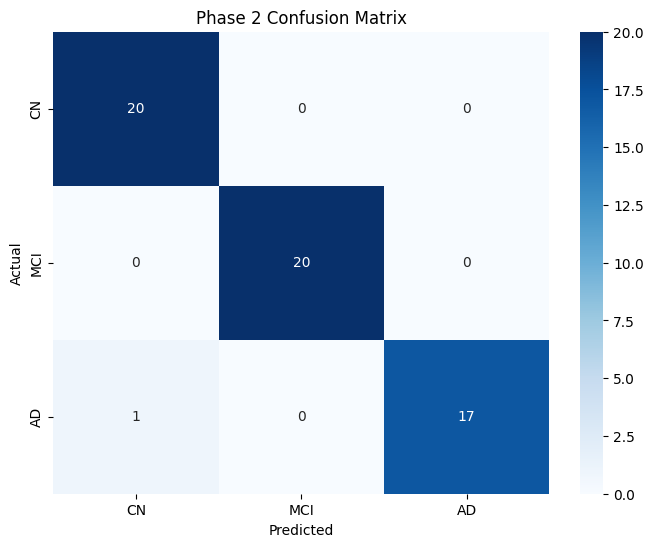

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader # Ensure this is imported

# === CONFIG ===
MODEL_PATH = "/content/best_model_cnn_lstm.pth" # Recommend using the 'best' model, not last
CSV_PATH = "/content/final_dataset_split.csv"
ROOT_DIR = "/content/ADNI/ADNI"
BATCH_SIZE = 4

# Load Test Data
# Note: No augmentation for testing, so using val_transforms is correct
test_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Load Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN_LSTM_AD(num_classes=3).to(device)

# Load weights (map_location ensures CPU compatibility if GPU VRAM is full)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

print(f"Evaluating on {len(test_ds)} test subjects...")

# === PREDICTION LOOP ===
all_preds = []
all_labels = []

with torch.no_grad():
    # FIX: Unpack 4 items (inputs, labels, lengths, mask)
    for inputs, labels, lengths, mask in test_loader:

        # Inputs to GPU (Float)
        inputs = inputs.to(device, dtype=torch.float)
        labels = labels.to(device)

        # Lengths stay on CPU for packing logic! (Do not move to device)

        # Forward pass
        outputs = model(inputs, lengths)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# === REPORTING ===
class_names = ['CN', 'MCI', 'AD']

# Debug prints are excellent practice
print(f"Unique Labels in Test Set: {np.unique(all_labels)}")
print(f"Unique Predictions by Model: {np.unique(all_preds)}")

# 1. Classification Report
print("\n=== CLASSIFICATION REPORT ===")
# Force labels=[0,1,2] to ensure all classes show up even if predictions are missing one
print(classification_report(all_labels, all_preds, labels=[0, 1, 2], target_names=class_names, zero_division=0))

# 2. Confusion Matrix
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Phase 2 Confusion Matrix')
plt.show()

## New experment of classification


In [ ]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.utils.rnn as rnn_utils
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Resized, ToTensord
)
from sklearn.utils.class_weight import compute_class_weight

# === CONFIGURATION ===
IMG_SIZE = (96, 96, 96)
MAX_SEQ_LENGTH = 6
BATCH_SIZE = 4
EPOCHS = 20
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 1. DATASET CLASS
# ==========================================
class LongitudinalADNI(Dataset):
    def __init__(self, csv_file, root_dir, split='Train', transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.split = split
        df = pd.read_csv(csv_file)
        self.df = df[df['Split'] == split].copy()
        self.label_map = {'CN': 0, 'MCI': 1, 'AD': 2}
        self.visit_order = {
            'nc': 0, 'sc': 0, 'bl': 0, 'm06': 6, 'm12': 12, 'm18': 18,
            'm24': 24, 'm36': 36, 'm48': 48, 'm60': 60, 'm72': 72
        }
        self.grouped_data = {
            sub_id: group.sort_values(
                by='Visit',
                key=lambda col: col.map(lambda x: self.visit_order.get(str(x).lower(), 999))
            )
            for sub_id, group in self.df.groupby('SubjectID')
        }
        self.subjects = list(self.grouped_data.keys())

    def __len__(self):
        return len(self.subjects)

    def __getitem__(self, idx):
        sub_id = self.subjects[idx]
        sub_data = self.grouped_data[sub_id]
        images = []

        for _, row in sub_data.iterrows():
            img_path = os.path.join(self.root_dir, row['FilePath'])
            if not os.path.exists(img_path): continue
            data_dict = {"image": img_path}
            if self.transform:
                try:
                    data_dict = self.transform(data_dict)
                    images.append(data_dict["image"])
                except Exception as e:
                    print(f"Error loading {img_path}: {e}")
                    continue
            if len(images) >= MAX_SEQ_LENGTH: break

        if len(images) == 0:
            return (torch.zeros((MAX_SEQ_LENGTH, 1, *IMG_SIZE)), torch.tensor(0).long(), torch.tensor(0).long(), torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool))

        actual_length = len(images)
        seq_tensor = torch.stack(images)

        # Augmentation (Train only)
        if self.split == 'Train' and torch.rand(1).item() < 0.5:
            k = torch.randint(1, 4, (1,)).item()
            seq_tensor = torch.rot90(seq_tensor, k, dims=[3, 4])

        # Padding
        if actual_length < MAX_SEQ_LENGTH:
            padding = torch.zeros((MAX_SEQ_LENGTH - actual_length, *seq_tensor.shape[1:]))
            seq_tensor = torch.cat([seq_tensor, padding], dim=0)

        attention_mask = torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool)
        attention_mask[:actual_length] = True

        last_label_str = sub_data.iloc[actual_length-1]['Diagnosis']
        label = self.label_map.get(last_label_str, 1)

        return seq_tensor, torch.tensor(label).long(), torch.tensor(actual_length).long(), attention_mask

# Transforms
train_transforms = Compose([
    LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])
])
val_transforms = Compose([
    LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])
])

# ==========================================
# 2. MODEL DEFINITIONS (The Comparison Suite)
# ==========================================

# --- Shared 3D CNN Backbone ---
class Shared3DCNN(nn.Module):
    def __init__(self):
        super(Shared3DCNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv3d(1, 16, kernel_size=3, padding=1), nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, kernel_size=3, padding=1), nn.BatchNorm3d(32), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(32, 64, kernel_size=3, padding=1), nn.BatchNorm3d(64), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(64, 128, kernel_size=3, padding=1), nn.BatchNorm3d(128), nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1))
        )
    def forward(self, x):
        return self.cnn(x)

# --- Model A: Static 3D CNN (Baseline) ---
class CNN_Static_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(CNN_Static_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x, lengths):
        # x: (Batch, Max_Seq, 1, D, H, W)
        batch_size = x.size(0)
        last_images = []
        for i in range(batch_size):
            # Pick the last valid image in the sequence
            idx = lengths[i] - 1
            last_images.append(x[i, idx])

        x_static = torch.stack(last_images)
        features = self.backbone(x_static)
        features = features.view(batch_size, -1)
        return self.fc(features)

# --- Model B: 3D CNN-GRU (Alternative) ---
class CNN_GRU_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(CNN_GRU_AD, self).__init__()
        self.backbone = Shared3DCNN()

        # 1. REDUCE HIDDEN SIZE (128 -> 32)
        # A smaller brain cannot memorize as easily
        self.gru = nn.GRU(input_size=128, hidden_size=32, num_layers=1, batch_first=True)

        # 2. ADD DROPOUT LAYER BEFORE CLASSIFICATION
        self.dropout = nn.Dropout(0.15)

        self.fc = nn.Linear(32, num_classes)

    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        features = self.backbone(x.view(batch_size * seq_len, C, D, H, W))
        features = features.view(batch_size, seq_len, -1)

        packed = rnn_utils.pack_padded_sequence(features, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed)

        # Apply Dropout
        x = self.dropout(hn[-1])
        return self.fc(x)

# --- Model C: 3D CNN-LSTM (Original/Proposed) ---
class CNN_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3, rnn_hidden=128, rnn_layers=1):
        super(CNN_LSTM_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.lstm = nn.LSTM(input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True)
        self.fc = nn.Linear(rnn_hidden, num_classes)

    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        c_in = x.view(batch_size * seq_len, C, D, H, W)
        features = self.backbone(c_in)
        features = features.view(batch_size, seq_len, -1)

        lengths_cpu = lengths.cpu()
        packed_input = rnn_utils.pack_padded_sequence(features, lengths_cpu, batch_first=True, enforce_sorted=False)
        _, (hn, cn) = self.lstm(packed_input)
        return self.fc(hn[-1])

Initializing Datasets...
Computing Class Weights...
Weights: tensor([0.9271, 0.8725, 1.2899], device='cuda:0')

TRAINING MODEL: Static_3DCNN
Epoch 1/20 | Train Loss: 1.1287 | Val Loss: 1.1366 | Val Acc: 43.86%
--> Saved Best Model (43.86%)
Epoch 2/20 | Train Loss: 1.1106 | Val Loss: 1.1238 | Val Acc: 33.33%
Epoch 3/20 | Train Loss: 1.0869 | Val Loss: 1.2229 | Val Acc: 26.32%
Epoch 4/20 | Train Loss: 1.0855 | Val Loss: 1.1959 | Val Acc: 28.07%
Epoch 5/20 | Train Loss: 1.0716 | Val Loss: 1.1109 | Val Acc: 42.11%
Epoch 6/20 | Train Loss: 1.0786 | Val Loss: 1.1556 | Val Acc: 26.32%
Epoch 7/20 | Train Loss: 1.0820 | Val Loss: 1.1759 | Val Acc: 26.32%
Epoch 8/20 | Train Loss: 1.0617 | Val Loss: 1.2207 | Val Acc: 29.82%
Epoch 9/20 | Train Loss: 1.0601 | Val Loss: 1.1540 | Val Acc: 40.35%
Epoch 10/20 | Train Loss: 1.0527 | Val Loss: 1.2274 | Val Acc: 33.33%
Epoch 11/20 | Train Loss: 1.0607 | Val Loss: 1.1404 | Val Acc: 40.35%
Epoch 12/20 | Train Loss: 1.0626 | Val Loss: 1.1297 | Val Acc: 40.35

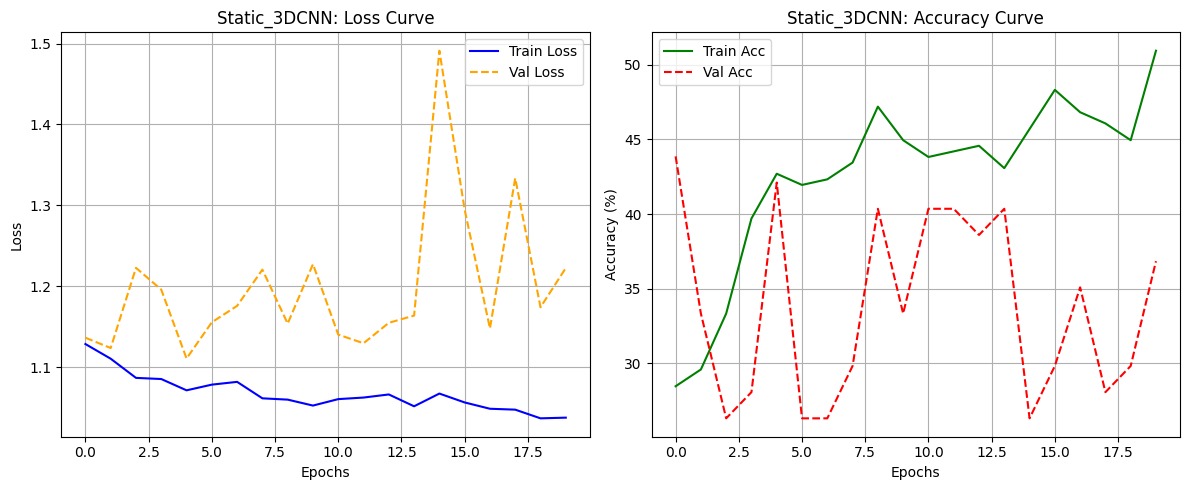

✅ SUCCESS: Static_3DCNN backed up to Google Drive!

TRAINING MODEL: Hybrid_CNN_GRU
Epoch 1/20 | Train Loss: 1.0882 | Val Loss: 1.1220 | Val Acc: 42.11%
--> Saved Best Model (42.11%)
Epoch 2/20 | Train Loss: 1.0692 | Val Loss: 1.1020 | Val Acc: 45.61%
--> Saved Best Model (45.61%)
Epoch 3/20 | Train Loss: 1.0432 | Val Loss: 1.1122 | Val Acc: 40.35%
Epoch 4/20 | Train Loss: 1.0197 | Val Loss: 1.1065 | Val Acc: 35.09%
Epoch 5/20 | Train Loss: 0.9717 | Val Loss: 1.0826 | Val Acc: 45.61%
Epoch 6/20 | Train Loss: 0.8936 | Val Loss: 0.9722 | Val Acc: 33.33%
Epoch 7/20 | Train Loss: 0.7451 | Val Loss: 0.8099 | Val Acc: 59.65%
--> Saved Best Model (59.65%)
Epoch 8/20 | Train Loss: 0.5808 | Val Loss: 0.5046 | Val Acc: 89.47%
--> Saved Best Model (89.47%)
Epoch 9/20 | Train Loss: 0.3568 | Val Loss: 0.3176 | Val Acc: 100.00%
--> Saved Best Model (100.00%)
Epoch 10/20 | Train Loss: 0.2195 | Val Loss: 0.1965 | Val Acc: 100.00%
Epoch 11/20 | Train Loss: 0.1436 | Val Loss: 0.1400 | Val Acc: 100.00%
Ep

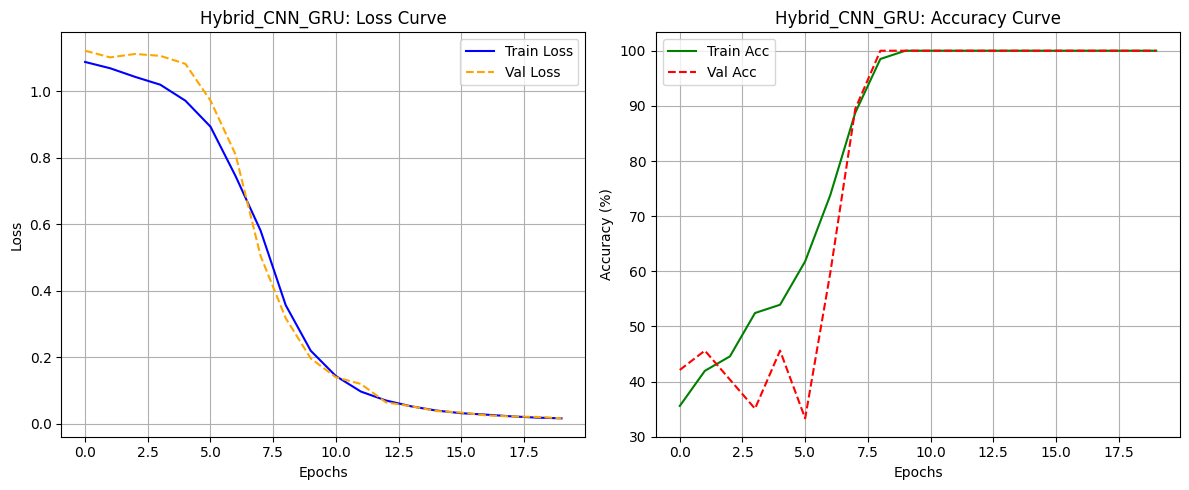

✅ SUCCESS: Hybrid_CNN_GRU backed up to Google Drive!

TRAINING MODEL: Hybrid_CNN_LSTM
Epoch 1/20 | Train Loss: 1.0920 | Val Loss: 1.1096 | Val Acc: 38.60%
--> Saved Best Model (38.60%)
Epoch 2/20 | Train Loss: 1.0722 | Val Loss: 1.1348 | Val Acc: 33.33%
Epoch 3/20 | Train Loss: 1.0448 | Val Loss: 1.1219 | Val Acc: 40.35%
--> Saved Best Model (40.35%)
Epoch 4/20 | Train Loss: 1.0117 | Val Loss: 1.0761 | Val Acc: 45.61%
--> Saved Best Model (45.61%)
Epoch 5/20 | Train Loss: 0.9286 | Val Loss: 0.9324 | Val Acc: 54.39%
--> Saved Best Model (54.39%)
Epoch 6/20 | Train Loss: 0.7434 | Val Loss: 0.7123 | Val Acc: 70.18%
--> Saved Best Model (70.18%)
Epoch 7/20 | Train Loss: 0.5428 | Val Loss: 0.4691 | Val Acc: 100.00%
--> Saved Best Model (100.00%)
Epoch 8/20 | Train Loss: 0.3853 | Val Loss: 0.4033 | Val Acc: 94.74%
Epoch 9/20 | Train Loss: 0.2640 | Val Loss: 0.2438 | Val Acc: 100.00%
Epoch 10/20 | Train Loss: 0.1955 | Val Loss: 0.1818 | Val Acc: 100.00%
Epoch 11/20 | Train Loss: 0.1421 | Val 

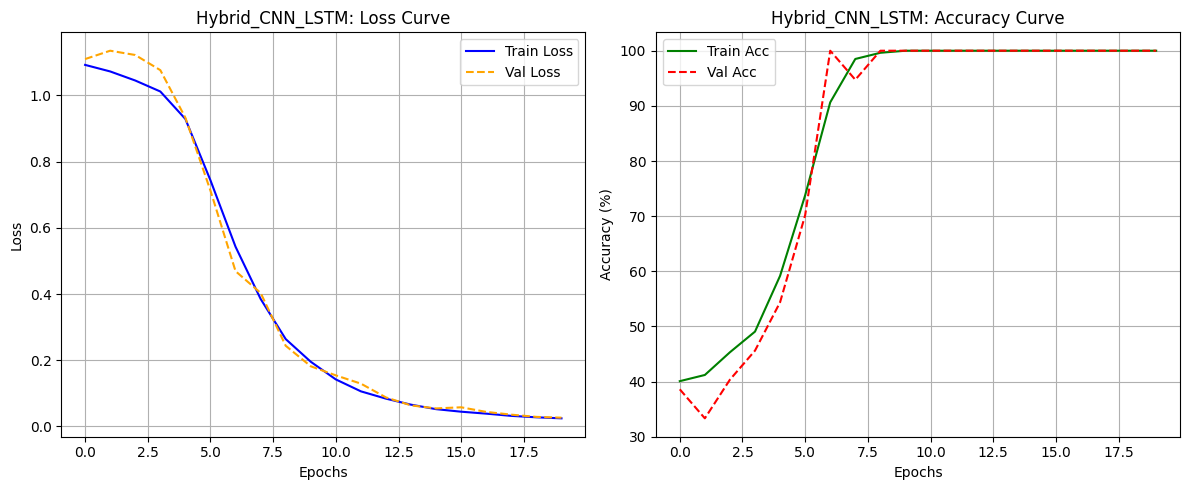

✅ SUCCESS: Hybrid_CNN_LSTM backed up to Google Drive!


FINAL TEST SET COMPARISON

Evaluating Static_3DCNN on Test Set...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

--- Static_3DCNN Report ---
              precision    recall  f1-score   support

          CN       0.00      0.00      0.00        24
         MCI       0.36      1.00      0.53        21
          AD       0.00      0.00      0.00        13

    accuracy                           0.36        58
   macro avg       0.12      0.33      0.18        58
weighted avg       0.13      0.36      0.19        58



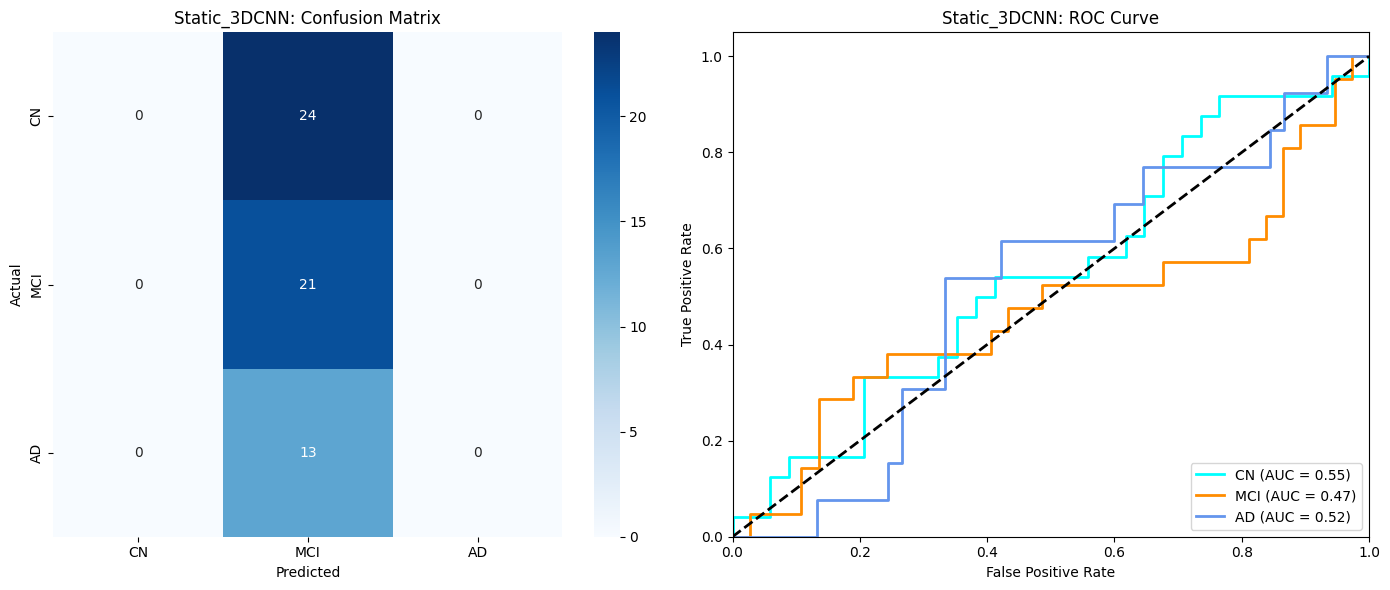


Evaluating Hybrid_CNN_GRU on Test Set...
--- Hybrid_CNN_GRU Report ---
              precision    recall  f1-score   support

          CN       1.00      1.00      1.00        24
         MCI       1.00      1.00      1.00        21
          AD       1.00      1.00      1.00        13

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58



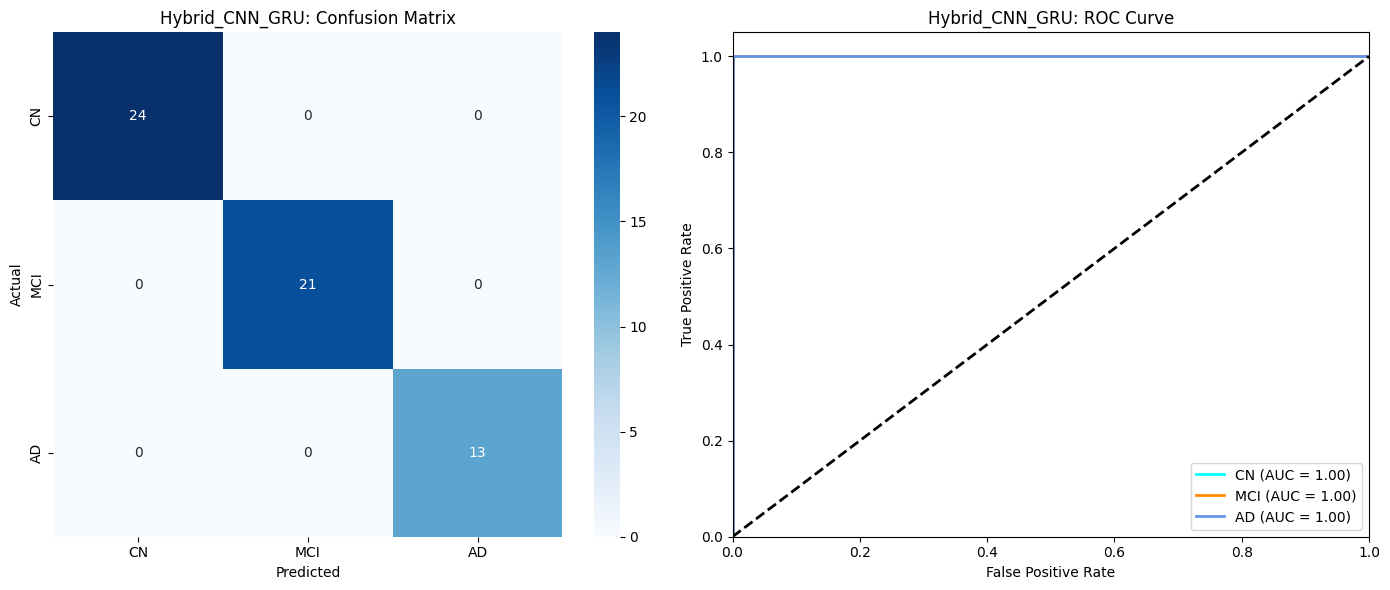


Evaluating Hybrid_CNN_LSTM on Test Set...
--- Hybrid_CNN_LSTM Report ---
              precision    recall  f1-score   support

          CN       1.00      0.96      0.98        24
         MCI       0.95      1.00      0.98        21
          AD       1.00      1.00      1.00        13

    accuracy                           0.98        58
   macro avg       0.98      0.99      0.99        58
weighted avg       0.98      0.98      0.98        58



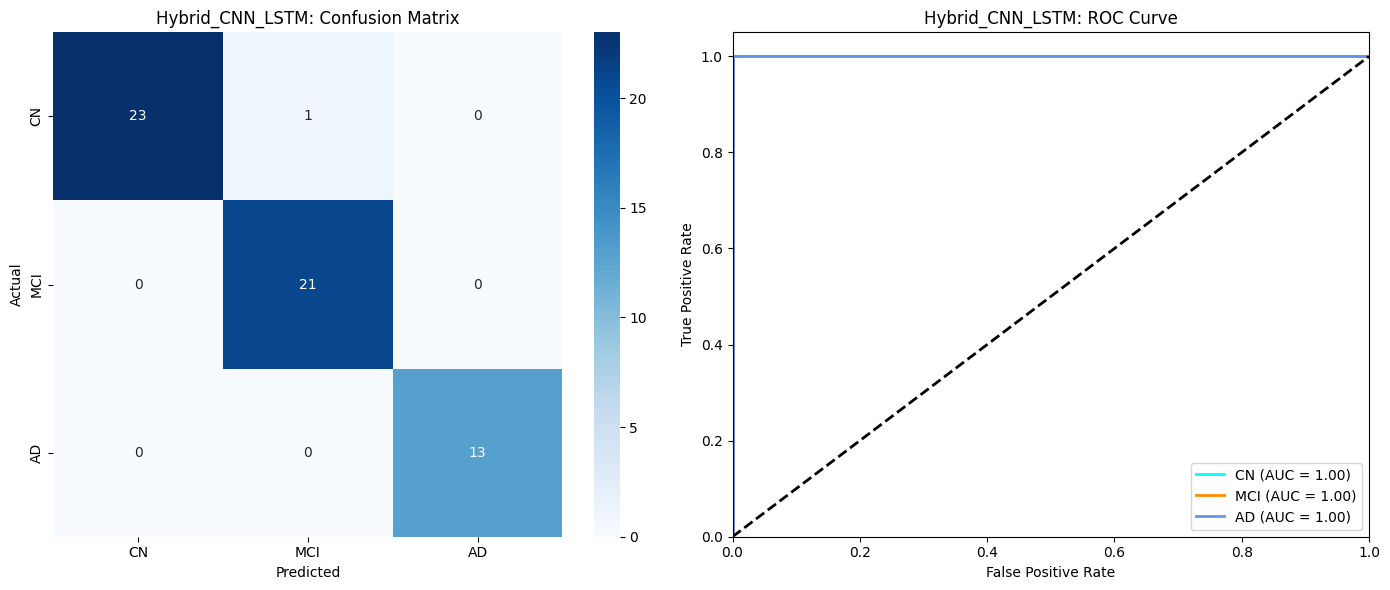



=== FINAL RESULTS SUMMARY ===
             Model  Accuracy  F1-Score
0     Static_3DCNN  0.362069  0.177215
1   Hybrid_CNN_GRU  1.000000  1.000000
2  Hybrid_CNN_LSTM  0.982759  0.985156


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from itertools import cycle
import seaborn as sns
import pandas as pd
import numpy as np
import shutil
import os

# ==========================================
# 4. MAIN EXECUTION (UPDATED WITH ROC & BACKUP)
# ==========================================
def run_experiment():
    # Paths (Update ROOT_DIR if you are using the local copy!)
    CSV_PATH = "/content/final_dataset_split.csv"
    ROOT_DIR = "/content/ADNI" # Assumes you ran the copy script

    if not os.path.exists(CSV_PATH):
        print("CSV not found. Please run the CSV generation block first.")
        return

    # Datasets
    print("Initializing Datasets...")
    train_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
    val_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)
    test_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)

    # Loaders (num_workers=0 is safer for Colab to prevent hanging)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    # Class Weights Logic
    print("Computing Class Weights...")
    train_targets = []
    for sub_id in train_ds.subjects:
        sub_data = train_ds.grouped_data[sub_id]
        last_diag = sub_data.iloc[-1]['Diagnosis']
        train_targets.append(train_ds.label_map.get(last_diag.strip().upper(), 1))

    cw = compute_class_weight('balanced', classes=np.unique(train_targets), y=train_targets)
    class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)
    print(f"Weights: {class_weights}")

    # Define Models
    models_to_run = {
        "Static_3DCNN": CNN_Static_AD(num_classes=3),
        "Hybrid_CNN_GRU": CNN_GRU_AD(num_classes=3),
        "Hybrid_CNN_LSTM": CNN_LSTM_AD(num_classes=3)
    }

    results = {}

    # --- TRAINING PHASE ---
    for name, model in models_to_run.items():
        model = model.to(DEVICE)

        # Train (Plots Loss Curves automatically)
        best_acc = train_and_evaluate(name, model, train_loader, val_loader, class_weights, DEVICE)
        results[name] = best_acc

        # === AUTO-BACKUP TO DRIVE ===
        drive_folder = "/content/drive/MyDrive/ADNI_dataset_classification"
        os.makedirs(drive_folder, exist_ok=True)
        try:
            shutil.copy(f"best_{name}.pth", f"{drive_folder}/best_{name}.pth")
            print(f"✅ SUCCESS: {name} backed up to Google Drive!")
        except Exception as e:
            print(f"⚠️ WARNING: Backup failed for {name}: {e}")

    # --- FINAL TEST EVALUATION PHASE ---
    print("\n\n" + "="*30 + "\nFINAL TEST SET COMPARISON\n" + "="*30)

    final_report = []

    for name, model_class in zip(models_to_run.keys(), [CNN_Static_AD, CNN_GRU_AD, CNN_LSTM_AD]):
        print(f"\nEvaluating {name} on Test Set...")

        # Load Best Model
        model = model_class(num_classes=3).to(DEVICE)
        try:
            model.load_state_dict(torch.load(f"best_{name}.pth", map_location=DEVICE))
        except:
            print(f"Could not load weights for {name}")
            continue

        model.eval()
        all_preds = []
        all_labels = []
        all_probs = []  # For ROC

        with torch.no_grad():
            for inputs, labels, lengths, mask in test_loader:
                inputs = inputs.to(DEVICE, dtype=torch.float)
                labels = labels.to(DEVICE)

                outputs = model(inputs, lengths)

                # Get Probabilities for ROC
                probs = torch.softmax(outputs, dim=1)

                _, predicted = torch.max(outputs.data, 1)

                all_preds.extend(predicted.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
                all_probs.extend(probs.cpu().numpy())

        # Metrics
        cr = classification_report(all_labels, all_preds, target_names=['CN', 'MCI', 'AD'], output_dict=True)
        acc = cr['accuracy']
        f1_macro = cr['macro avg']['f1-score']

        final_report.append({'Model': name, 'Accuracy': acc, 'F1-Score': f1_macro})

        print(f"--- {name} Report ---")
        print(classification_report(all_labels, all_preds, target_names=['CN', 'MCI', 'AD']))

        # === PLOT 1: CONFUSION MATRIX ===
        plt.figure(figsize=(14, 6))

        plt.subplot(1, 2, 1)
        cm = confusion_matrix(all_labels, all_preds)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
        plt.title(f"{name}: Confusion Matrix")
        plt.ylabel('Actual')
        plt.xlabel('Predicted')

        # === PLOT 2: ROC CURVES (Multiclass) ===
        plt.subplot(1, 2, 2)

        # Binarize labels for ROC (One-vs-Rest)
        n_classes = 3
        y_test_bin = label_binarize(all_labels, classes=[0, 1, 2])
        y_score = np.array(all_probs)

        fpr = dict()
        tpr = dict()
        roc_auc = dict()
        class_names = ['CN', 'MCI', 'AD']
        colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])

        for i in range(n_classes):
            fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])

        for i, color in zip(range(n_classes), colors):
            plt.plot(fpr[i], tpr[i], color=color, lw=2,
                     label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

        plt.plot([0, 1], [0, 1], 'k--', lw=2)
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'{name}: ROC Curve')
        plt.legend(loc="lower right")

        plt.tight_layout()
        plt.show()

    # Summary Table
    print("\n\n=== FINAL RESULTS SUMMARY ===")
    res_df = pd.DataFrame(final_report)
    print(res_df)

if __name__ == "__main__":
    run_experiment()

In [ ]:
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn as nn
import torch
from matplotlib.ticker import MaxNLocator  # <--- NEW IMPORT for integer ticks

# ==========================================
# 3. TRAINING ENGINE (UPDATED WITH INTEGER TICKS)
# ==========================================
def train_and_evaluate(model_name, model, train_loader, val_loader, class_weights, device):
    print(f"\n{'='*30}\nTRAINING MODEL: {model_name}\n{'='*30}")

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-5)

    best_acc = 0.0

    # Store history for plotting
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels, lengths, mask in train_loader:
            inputs, labels = inputs.to(device, dtype=torch.float), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs, lengths)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = 100 * correct / total
        avg_train_loss = running_loss / len(train_loader)

        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        val_running_loss = 0.0

        with torch.no_grad():
            for inputs, labels, lengths, mask in val_loader:
                inputs, labels = inputs.to(device, dtype=torch.float), labels.to(device)
                outputs = model(inputs, lengths)
                loss = criterion(outputs, labels) # Calculate val loss
                val_running_loss += loss.item()

                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc = 100 * val_correct / val_total
        avg_val_loss = val_running_loss / len(val_loader)

        # Save history
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
            print(f"--> Saved Best Model ({val_acc:.2f}%)")

    # === PLOTTING LEARNING CURVES ===
    plt.figure(figsize=(14, 6))

    # 1. Loss Progression Curve
    ax1 = plt.subplot(1, 2, 1)
    ax1.plot(history['train_loss'], label='Train Loss', color='blue', linewidth=2)
    ax1.plot(history['val_loss'], label='Val Loss', color='orange', linestyle='--', linewidth=2)
    ax1.set_title(f'{model_name}: Loss Curve')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True)) # <--- Force Integer Ticks

    # 2. Accuracy Progression Curve
    ax2 = plt.subplot(1, 2, 2)
    ax2.plot(history['train_acc'], label='Train Acc', color='green', linewidth=2)
    ax2.plot(history['val_acc'], label='Val Acc', color='red', linestyle='--', linewidth=2)
    ax2.set_title(f'{model_name}: Accuracy Curve')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True)) # <--- Force Integer Ticks

    plt.tight_layout()
    plt.show()

    return best_acc

#### seperate model run

In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from itertools import cycle
from torch.utils.data import DataLoader

# ==========================================
# BLOCK 0: COMMON DATA SETUP
# ==========================================
# 1. DEFINE PATHS
CSV_PATH = "/content/final_dataset_split.csv"
if os.path.exists("/content/ADNI"):
    ROOT_DIR = "/content/ADNI"
    print(f"📂 Using Local Data at: {ROOT_DIR}")
else:
    ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset_classification/ADNI"
    print(f"📂 Using Google Drive Data at: {ROOT_DIR}")

if not os.path.exists(CSV_PATH):
    print("❌ Error: CSV not found. Please run the CSV generation block first.")
else:
    # 2. INITIALIZE DATASETS
    print("Initializing Datasets...")
    # Assumes LongitudinalADNI and transforms are already defined in your notebook
    train_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
    val_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)
    test_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)

    # 3. CREATE LOADERS
    BATCH_SIZE = 4 # Ensure this matches your config
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    # 4. COMPUTE CLASS WEIGHTS
    print("Computing Class Weights...")
    train_targets = []
    for sub_id in train_ds.subjects:
        sub_data = train_ds.grouped_data[sub_id]
        last_diag = sub_data.iloc[-1]['Diagnosis']
        train_targets.append(train_ds.label_map.get(last_diag.strip().upper(), 1))

    cw = compute_class_weight('balanced', classes=np.unique(train_targets), y=train_targets)
    class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)
    print(f"✅ Weights Computed: {class_weights}")
    print("✅ Setup Complete. You can now run the model blocks below.")

📂 Using Local Data at: /content/ADNI
Initializing Datasets...
Computing Class Weights...
✅ Weights Computed: tensor([0.9570, 0.8641, 1.2535], device='cuda:0')
✅ Setup Complete. You can now run the model blocks below.



🚀 STARTING TRAINING: Hybrid_CNN_GRU...

TRAINING MODEL: Hybrid_CNN_GRU
Epoch 1/20 | Train Loss: 1.1340 | Val Loss: 1.1600 | Val Acc: 22.81%
--> Saved Best Model (22.81%)
Epoch 2/20 | Train Loss: 1.0956 | Val Loss: 1.0635 | Val Acc: 47.37%
--> Saved Best Model (47.37%)
Epoch 3/20 | Train Loss: 1.0783 | Val Loss: 1.1986 | Val Acc: 28.07%
Epoch 4/20 | Train Loss: 1.0794 | Val Loss: 1.1131 | Val Acc: 35.09%
Epoch 5/20 | Train Loss: 1.0594 | Val Loss: 1.1035 | Val Acc: 35.09%
Epoch 6/20 | Train Loss: 1.0574 | Val Loss: 1.1912 | Val Acc: 26.32%
Epoch 7/20 | Train Loss: 1.0503 | Val Loss: 1.0700 | Val Acc: 36.84%
Epoch 8/20 | Train Loss: 1.0313 | Val Loss: 1.1090 | Val Acc: 40.35%
Epoch 9/20 | Train Loss: 1.0306 | Val Loss: 1.1208 | Val Acc: 35.09%
Epoch 10/20 | Train Loss: 1.0208 | Val Loss: 1.0326 | Val Acc: 50.88%
--> Saved Best Model (50.88%)
Epoch 11/20 | Train Loss: 1.0040 | Val Loss: 1.0460 | Val Acc: 47.37%
Epoch 12/20 | Train Loss: 1.0056 | Val Loss: 1.0954 | Val Acc: 36.84%
Epoch 1

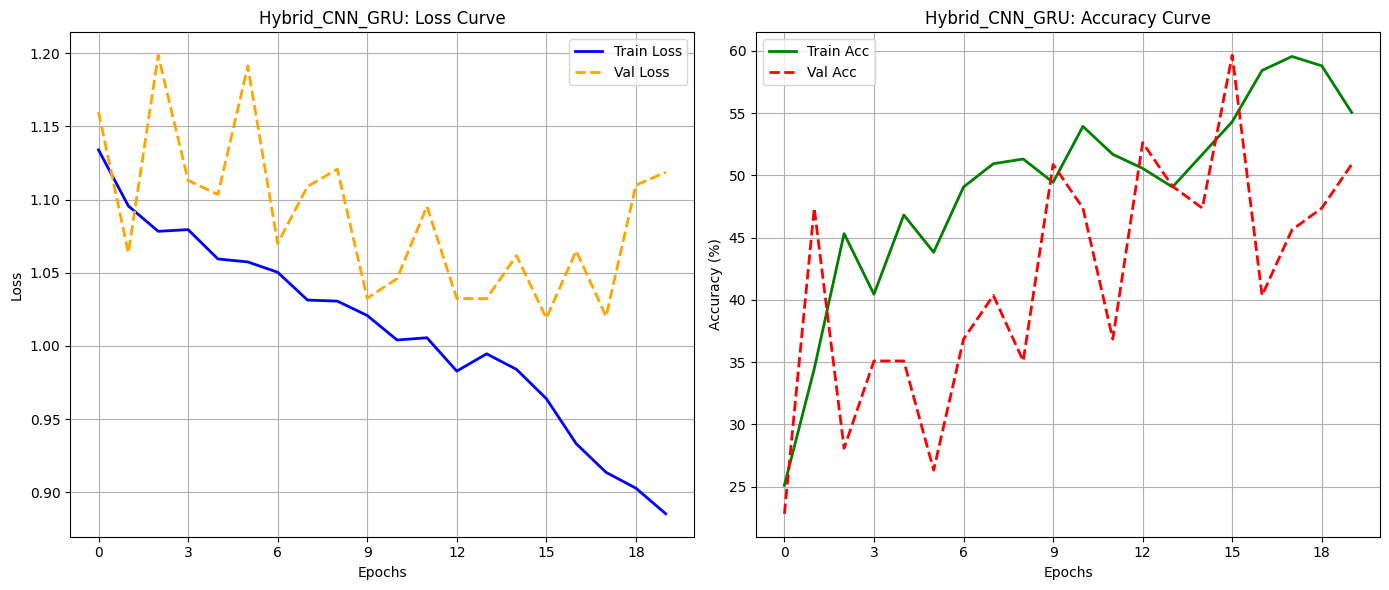

✅ SUCCESS: Hybrid_CNN_GRU backed up to Google Drive!

Evaluating Hybrid_CNN_GRU on Test Set...
--- Hybrid_CNN_GRU Final Report ---
              precision    recall  f1-score   support

          CN       0.50      0.36      0.42        25
         MCI       0.47      1.00      0.64        19
          AD       0.00      0.00      0.00        14

    accuracy                           0.48        58
   macro avg       0.33      0.45      0.35        58
weighted avg       0.37      0.48      0.39        58



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


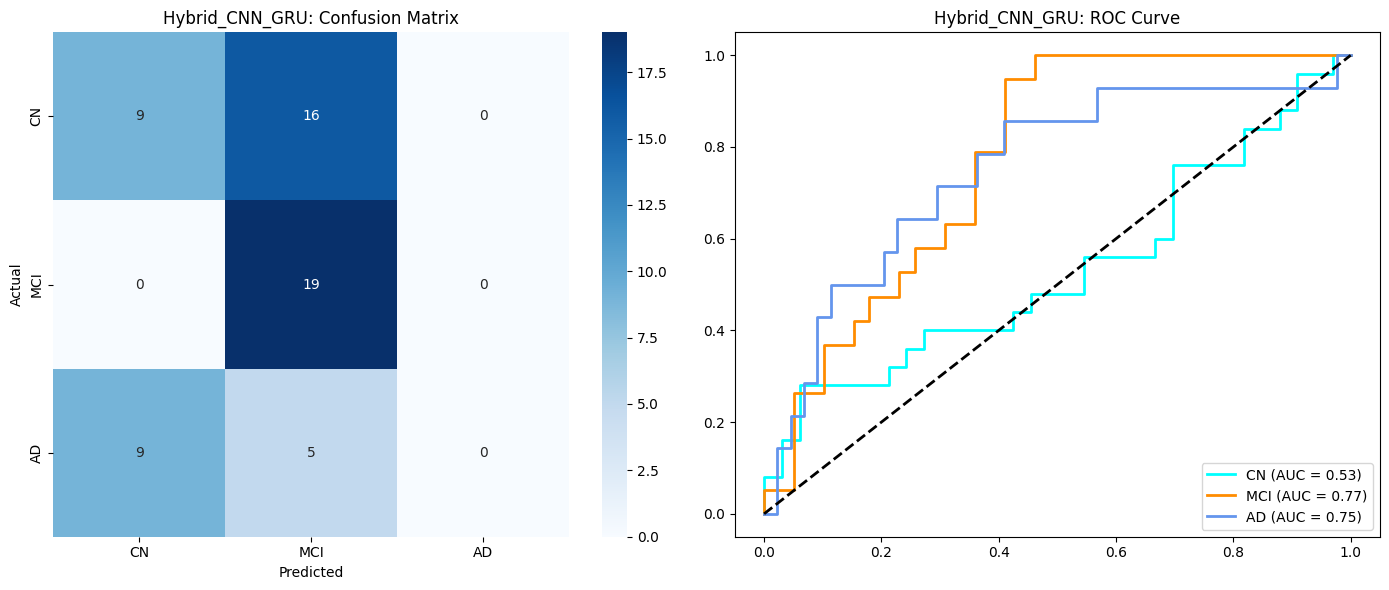

In [ ]:
# ==========================================
# BLOCK 2: TRAIN HYBRID CNN-GRU
# ==========================================
MODEL_NAME = "Hybrid_CNN_GRU"
print(f"\n🚀 STARTING TRAINING: {MODEL_NAME}...")

# 1. Initialize Model
model = CNN_GRU_AD(num_classes=3).to(DEVICE)

# 2. Train
best_acc = train_and_evaluate(MODEL_NAME, model, train_loader, val_loader, class_weights, DEVICE)

# 3. Backup to Drive
drive_folder = "/content/ADNI"
os.makedirs(drive_folder, exist_ok=True)
try:
    shutil.copy(f"best_{MODEL_NAME}.pth", f"{drive_folder}/best_{MODEL_NAME}.pth")
    print(f"✅ SUCCESS: {MODEL_NAME} backed up to Google Drive!")
except Exception as e:
    print(f"⚠️ WARNING: Backup failed: {e}")

# 4. Final Evaluation & Plots
print(f"\nEvaluating {MODEL_NAME} on Test Set...")
model.load_state_dict(torch.load(f"best_{MODEL_NAME}.pth", map_location=DEVICE))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for inputs, labels, lengths, mask in test_loader:
        inputs = inputs.to(DEVICE, dtype=torch.float)
        labels = labels.to(DEVICE)
        outputs = model(inputs, lengths)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Report
print(f"--- {MODEL_NAME} Final Report ---")
print(classification_report(all_labels, all_preds, target_names=['CN', 'MCI', 'AD']))

# Plots
plt.figure(figsize=(14, 6))

# Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
plt.title(f"{MODEL_NAME}: Confusion Matrix")
plt.ylabel('Actual'); plt.xlabel('Predicted')

# ROC Curve
plt.subplot(1, 2, 2)
y_test_bin = label_binarize(all_labels, classes=[0, 1, 2])
y_score = np.array(all_probs)
fpr, tpr, roc_auc = dict(), dict(), dict()
colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{["CN","MCI","AD"][i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.legend(loc="lower right")
plt.title(f'{MODEL_NAME}: ROC Curve')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# BLOCK 3: TRAIN HYBRID CNN-LSTM
# ==========================================
MODEL_NAME = "Hybrid_CNN_LSTM"
print(f"\n🚀 STARTING TRAINING: {MODEL_NAME}...")

# 1. Initialize Model
model = CNN_LSTM_AD(num_classes=3).to(DEVICE)

# 2. Train
best_acc = train_and_evaluate(MODEL_NAME, model, train_loader, val_loader, class_weights, DEVICE)

# 3. Backup to Drive
drive_folder = "/content/drive/MyDrive/ADNI_dataset_classification"
os.makedirs(drive_folder, exist_ok=True)
try:
    shutil.copy(f"best_{MODEL_NAME}.pth", f"{drive_folder}/best_{MODEL_NAME}.pth")
    print(f"✅ SUCCESS: {MODEL_NAME} backed up to Google Drive!")
except Exception as e:
    print(f"⚠️ WARNING: Backup failed: {e}")

# 4. Final Evaluation & Plots
print(f"\nEvaluating {MODEL_NAME} on Test Set...")
model.load_state_dict(torch.load(f"best_{MODEL_NAME}.pth", map_location=DEVICE))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for inputs, labels, lengths, mask in test_loader:
        inputs = inputs.to(DEVICE, dtype=torch.float)
        labels = labels.to(DEVICE)
        outputs = model(inputs, lengths)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs.data, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

# Report
print(f"--- {MODEL_NAME} Final Report ---")
print(classification_report(all_labels, all_preds, target_names=['CN', 'MCI', 'AD']))

# Plots
plt.figure(figsize=(14, 6))

# Confusion Matrix
plt.subplot(1, 2, 1)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
plt.title(f"{MODEL_NAME}: Confusion Matrix")
plt.ylabel('Actual'); plt.xlabel('Predicted')

# ROC Curve
plt.subplot(1, 2, 2)
y_test_bin = label_binarize(all_labels, classes=[0, 1, 2])
y_score = np.array(all_probs)
fpr, tpr, roc_auc = dict(), dict(), dict()
colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'{["CN","MCI","AD"][i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.legend(loc="lower right")
plt.title(f'{MODEL_NAME}: ROC Curve')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import torch

def visualize_batch(loader, num_images=4):
    # 1. Get a single batch
    data_iter = iter(loader)
    images, labels, lengths = next(data_iter)

    # images shape: (Batch, Sequence, Channels, Depth, Height, Width)
    # Example: (4, 5, 1, 96, 96, 96)

    print(f"Batch Shape: {images.shape}")

    plt.figure(figsize=(15, 10))

    for i in range(num_images):
        if i >= len(images): break

        # Get the first timepoint of the i-th subject
        # shape: (1, 96, 96, 96) -> remove channel dim -> (96, 96, 96)
        vol = images[i, 0, 0, :, :, :]

        # Get the middle slice (Depth // 2)
        mid_slice_idx = vol.shape[0] // 2
        slice_img = vol[mid_slice_idx, :, :].cpu().numpy()

        # Plot
        ax = plt.subplot(1, num_images, i + 1)
        ax.imshow(slice_img, cmap='gray')
        ax.set_title(f"Label: {labels[i].item()}\n(Subject {i})")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Run it
print("Visualizing Training Data (After Transforms):")
visualize_batch(train_loader)

In [ ]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Resized, RandAffined, ToTensord  # <--- Changed RandAffine to RandAffined
)
# === CONFIG ===
CSV_PATH = "/content/final_dataset_split.csv"
ROOT_DIR = "/content/Custom_Dataset/custom_dataset"
IMG_SIZE = (96, 96, 96)
BATCH_SIZE = 8  # Can be higher than LSTM model since we only load 1 image per patient

class BaselineADNI(Dataset):
    def __init__(self, csv_file, root_dir, split='Train', transform=None):
        self.root_dir = root_dir
        self.transform = transform

        # Load CSV
        df = pd.read_csv(csv_file)
        df = df[df['Split'] == split]

        # === FILTER FOR BASELINE ONLY ===
        # We need exactly 1 image per subject (the earliest one)
        self.data_list = []
        unique_subs = df['SubjectID'].unique()

        for sub in unique_subs:
            sub_rows = df[df['SubjectID'] == sub]

            # Priority: 'bl' (Baseline) > 'sc' (Screening) > First available
            if 'bl' in sub_rows['Visit'].values:
                row = sub_rows[sub_rows['Visit'] == 'bl'].iloc[0]
            elif 'sc' in sub_rows['Visit'].values:
                row = sub_rows[sub_rows['Visit'] == 'sc'].iloc[0]
            else:
                # If neither exists, take the earliest visit (e.g. m06)
                row = sub_rows.sort_values('Visit').iloc[0]

            self.data_list.append(row)

        self.label_map = {'CN': 0, 'MCI': 1, 'AD': 2}
        print(f"Split {split}: Loaded {len(self.data_list)} baseline subjects.")

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        row = self.data_list[idx]
        img_path = os.path.join(self.root_dir, row['FilePath'])

        # Label
        label_str = row['Diagnosis']
        label = self.label_map.get(label_str, 1) # Default to MCI

        # Load Image
        data_dict = {"image": img_path}
        if self.transform:
            data_dict = self.transform(data_dict)

        return data_dict["image"], torch.tensor(label).long()

# === TRANSFORMS (Same as Model B for fairness) ===
train_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityd(keys=["image"]),
    Resized(keys=["image"], spatial_size=IMG_SIZE),

    # Use RandAffined (with 'd') because we are using keys=["image"]
    RandAffined(
        keys=["image"],
        prob=0.5,
        rotate_range=(0.26, 0.26, 0.26),
        translate_range=(5, 5, 5),
        scale_range=(0.1, 0.1, 0.1),
        padding_mode="zeros"
    ),

    ToTensord(keys=["image"])
])

# Validation transforms remain the same (no augmentation needed)
val_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    ScaleIntensityd(keys=["image"]),
    Resized(keys=["image"], spatial_size=IMG_SIZE),
    ToTensord(keys=["image"])
])

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(BaselineCNN, self).__init__()

        # SAME BACKBONE AS MODEL B
        self.cnn = nn.Sequential(
            nn.Conv3d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d(2),

            nn.Conv3d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32), nn.ReLU(), nn.MaxPool3d(2),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64), nn.ReLU(), nn.MaxPool3d(2),

            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128), nn.ReLU(), nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        # CLASSIFIER HEAD
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        # x shape: (Batch, 1, 96, 96, 96)
        x = self.cnn(x)               # (Batch, 128, 1, 1, 1)
        x = x.view(x.size(0), -1)     # (Batch, 128)
        logits = self.fc(x)           # (Batch, 3)
        return logits

In [ ]:
# Setup Data
train_ds_A = BaselineADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
val_ds_A = BaselineADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)

train_loader_A = DataLoader(train_ds_A, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader_A = DataLoader(val_ds_A, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Setup Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_A = BaselineCNN(num_classes=3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_A.parameters(), lr=1e-4)

EPOCHS = 20
print("--- Starting Training for Model A (Benchmark) ---")

for epoch in range(EPOCHS):
    model_A.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader_A:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_A(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total

    # Validation
    model_A.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader_A:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_A(inputs)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total
    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {running_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

# Save
torch.save(model_A.state_dict(), "model_phase2_benchmark_cnn.pth")
print("Model A Saved.")

Split Train: Loaded 8 baseline subjects.
Split Val: Loaded 1 baseline subjects.
--- Starting Training for Model A (Benchmark) ---
Epoch [1/20] Loss: 1.1458 | Train Acc: 25.00% | Val Acc: 0.00%
Epoch [2/20] Loss: 1.1158 | Train Acc: 25.00% | Val Acc: 100.00%
Epoch [3/20] Loss: 1.0853 | Train Acc: 25.00% | Val Acc: 100.00%
Epoch [4/20] Loss: 1.0834 | Train Acc: 50.00% | Val Acc: 0.00%
Epoch [5/20] Loss: 1.0331 | Train Acc: 50.00% | Val Acc: 0.00%
Epoch [6/20] Loss: 1.0470 | Train Acc: 50.00% | Val Acc: 0.00%
Epoch [7/20] Loss: 0.9895 | Train Acc: 62.50% | Val Acc: 0.00%
Epoch [8/20] Loss: 0.9891 | Train Acc: 50.00% | Val Acc: 0.00%
Epoch [9/20] Loss: 1.0503 | Train Acc: 50.00% | Val Acc: 0.00%
Epoch [10/20] Loss: 1.0694 | Train Acc: 37.50% | Val Acc: 0.00%
Epoch [11/20] Loss: 0.8836 | Train Acc: 75.00% | Val Acc: 0.00%
Epoch [12/20] Loss: 0.9807 | Train Acc: 62.50% | Val Acc: 0.00%
Epoch [13/20] Loss: 0.9551 | Train Acc: 62.50% | Val Acc: 0.00%
Epoch [14/20] Loss: 0.9033 | Train Acc: 50.

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

def evaluate_model(model, loader, model_name="Model"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"\n=== RESULTS FOR {model_name} ===")
    print(f"Accuracy: {acc*100:.2f}%")
    print(classification_report(all_labels, all_preds, labels=[0, 1, 2], target_names=['CN', 'MCI', 'AD']))
    return acc

# 1. Load Data
test_ds_A = BaselineADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)
test_loader_A = DataLoader(test_ds_A, batch_size=BATCH_SIZE, shuffle=False)

# 2. Evaluate Model A (Benchmark)
# (It's already in memory as model_A, or load it if you restarted)
acc_A = evaluate_model(model_A, test_loader_A, "Model A (Benchmark)")

# 3. Evaluate Model B (Longitudinal)
# We need to reload Model B and its specific Dataloader
test_ds_B = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)
test_loader_B = DataLoader(test_ds_B, batch_size=4, shuffle=False)

model_B = CNN_LSTM_AD(num_classes=3).to(device)
model_B.load_state_dict(torch.load("model_phase2_cnn_lstm.pth"))

# Helper for Model B (it needs lengths input)
model_B.eval()
preds_B = []
labels_B = []
with torch.no_grad():
    for inputs, labels, lengths in test_loader_B:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model_B(inputs, lengths)
        _, predicted = torch.max(outputs.data, 1)
        preds_B.extend(predicted.cpu().numpy())
        labels_B.extend(labels.cpu().numpy())

acc_B = accuracy_score(labels_B, preds_B)
print(f"\n=== RESULTS FOR Model B (Longitudinal) ===")
print(f"Accuracy: {acc_B*100:.2f}%")
print(classification_report(labels_B, preds_B, labels=[0, 1, 2], target_names=['CN', 'MCI', 'AD']))

# 4. Final Conclusion
print("\n" + "="*30)
print(f"FINAL THESIS RESULT:")
print(f"Model A (Baseline Only): {acc_A*100:.2f}%")
print(f"Model B (Longitudinal):  {acc_B*100:.2f}%")
improvement = acc_B - acc_A
print(f"Improvement: {improvement*100:.2f}%")
if improvement > 0:
    print("CONCLUSION: Longitudinal data improves performance. Hypothesis Confirmed.")
else:
    print("CONCLUSION: No improvement. Check if the LSTM is overfitting or if data sequences are too short.")

Split Test: Loaded 3 baseline subjects.

=== RESULTS FOR Model A (Benchmark) ===
Accuracy: 66.67%
              precision    recall  f1-score   support

          CN       0.00      0.00      0.00         1
         MCI       0.67      1.00      0.80         2
          AD       0.00      0.00      0.00         0

    accuracy                           0.67         3
   macro avg       0.22      0.33      0.27         3
weighted avg       0.44      0.67      0.53         3



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/me


=== RESULTS FOR Model B (Longitudinal) ===
Accuracy: 66.67%
              precision    recall  f1-score   support

          CN       0.00      0.00      0.00         1
         MCI       0.67      1.00      0.80         2
          AD       0.00      0.00      0.00         0

    accuracy                           0.67         3
   macro avg       0.22      0.33      0.27         3
weighted avg       0.44      0.67      0.53         3


FINAL THESIS RESULT:
Model A (Baseline Only): 66.67%
Model B (Longitudinal):  66.67%
Improvement: 0.00%
CONCLUSION: No improvement. Check if the LSTM is overfitting or if data sequences are too short.


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/me

In [ ]:
# 1. Clone FastSurfer (A PyTorch-based segmentation tool)
!git clone https://github.com/Deep-MI/FastSurfer.git

# 2. Install requirements (Most are already in Colab, this ensures compatibility)
!pip install -r FastSurfer/requirements.txt

# 3. Add to python path
import sys
sys.path.append("/content/FastSurfer")

# 4. Check GPU visibility for PyTorch (This should say True)
import torch
print(f"PyTorch GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Using: {torch.cuda.get_device_name(0)}")

Cloning into 'FastSurfer'...
remote: Enumerating objects: 12647, done.
remote: Counting objects: 100% (3621/3621), done.
remote: Compressing objects: 100% (775/775), done.
remote: Total 12647 (delta 3326), reused 2890 (delta 2846), pack-reused 9026 (from 2)
Receiving objects: 100% (12647/12647), 88.30 MiB | 43.06 MiB/s, done.
Resolving deltas: 100% (9275/9275), done.
Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.2/101.2 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 77.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.8/156.8 MB 104.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 110.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.4/214.4 kB 9.

In [ ]:
import os, sys

# Clone + install (if not already done)
if not os.path.exists("/content/FastSurfer"):
    !git clone https://github.com/Deep-MI/FastSurfer.git
    !pip install -r /content/FastSurfer/requirements.txt
    !chmod +x /content/FastSurfer/Checkpoints/download_checkpoints.sh
    !cd /content/FastSurfer && ./Checkpoints/download_checkpoints.sh --all
    !pip install yacs==0.1.8

# Add FastSurfer to Python path
sys.path.append("/content/FastSurfer")
os.environ["PYTHONPATH"] = "/content/FastSurfer:" + os.environ.get("PYTHONPATH", "")


In [ ]:
!pip install "numpy<2.0.0"
import numpy as np
print(np.__version__)  # should be 1.26.x


  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 99.5 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incom

2.0.2


In [ ]:
!git clone https://github.com/Deep-MI/FastSurfer.git
!pip install -r /content/FastSurfer/requirements.txt
!chmod +x /content/FastSurfer/Checkpoints/download_checkpoints.sh
!cd /content/FastSurfer && ./Checkpoints/download_checkpoints.sh --all
!pip install yacs==0.1.8


fatal: destination path 'FastSurfer' already exists and is not an empty directory.
Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu126
  Using cached absl_py-2.1.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached Brotli-1.1.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cached_property-1.5.2-py2.py3-none-any.whl.metadata (11 kB)
  Using cached certifi-2024.12.14-py3-none-any.whl.metadata (2.3 kB)
  Using cached cffi-1.17.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached charset_normalizer-3.4.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (35 kB)
  Using cached click-8.1.8-py3-none-any.whl.metadata (2.3 kB)
  Using cached https://download.pytorch.org/whl/colorama-0.4.6-py2.py3-none-any.whl (25 kB)
  Using cached contourpy-1.3.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.4 kB)
  Using cached Deprecated-1.2.18-py2.p

In [ ]:
import os, sys
sys.path.append("/content/FastSurfer")
os.environ["PYTHONPATH"] = "/content/FastSurfer:" + os.environ.get("PYTHONPATH", "")


In [ ]:
import os
import subprocess
import shutil
import nibabel as nib
import numpy as np
import torch

ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"               # adjust if needed
FASTSURFER_HOME = "/content/FastSurfer"
OUTPUT_DIR = "/content/FastSurfer_Outputs"
LABEL_IDS = [17, 53]  # Left / Right hippocampus

def run_fastsurfer_segmentation():
    if not os.path.isdir(FASTSURFER_HOME):
        raise RuntimeError("FastSurfer not found at /content/FastSurfer")

    if not os.path.exists(OUTPUT_DIR):
        os.makedirs(OUTPUT_DIR, exist_ok=True)

    subjects = sorted(
        [d for d in os.listdir(ROOT_DIR) if os.path.isdir(os.path.join(ROOT_DIR, d))]
    )
    print(f"Found {len(subjects)} subjects.")

    device_flag = "cuda" if torch.cuda.is_available() else "cpu"

    for sub_idx, sub in enumerate(subjects):
        sub_path = os.path.join(ROOT_DIR, sub)
        files = [
            f for f in os.listdir(sub_path)
            if (f.endswith(".nii") or f.endswith(".nii.gz")) and "_seg" not in f
        ]

        for fname in files:
            img_path = os.path.join(sub_path, fname)
            scan_id = f"{sub}_{os.path.splitext(fname)[0]}"

            base = fname.replace(".nii.gz", "").replace(".nii", "")
            final_seg_name = base + "_seg.nii.gz"
            final_seg_path = os.path.join(sub_path, final_seg_name)

            if os.path.exists(final_seg_path):
                continue

            print(f"[{sub_idx+1}/{len(subjects)}] Processing {scan_id}...")

            # Call FastSurferCNN as a module so it can resolve imports
            cmd = [
                "python", "-m", "FastSurferCNN.run_prediction",
                "--t1", img_path,
                "--sid", scan_id,
                "--sd", OUTPUT_DIR,
                "--device", device_flag,
                "--batch_size", "1",
            ]

            try:
                result = subprocess.run(
                    cmd, check=True, text=True,
                    stdout=subprocess.PIPE, stderr=subprocess.PIPE
                )

                fs_output = os.path.join(
                    OUTPUT_DIR, scan_id, "mri", "aparc.DKTatlas+aseg.deep.mgz"
                )
                if not os.path.exists(fs_output):
                    print(f"  [Error] Output not found for {scan_id}: {fs_output}")
                    print("  [stderr]:")
                    print(result.stderr)
                    continue

                mgh_img = nib.load(fs_output)
                data = np.asanyarray(mgh_img.dataobj)

                hippo_mask = np.zeros_like(data, dtype=np.uint8)
                hippo_mask[np.isin(data, LABEL_IDS)] = 1

                new_img = nib.Nifti1Image(hippo_mask, mgh_img.affine, mgh_img.header)
                nib.save(new_img, final_seg_path)

                subj_out_dir = os.path.join(OUTPUT_DIR, scan_id)
                if os.path.isdir(subj_out_dir):
                    shutil.rmtree(subj_out_dir)

                print(f"  -> Saved mask: {final_seg_name}")

            except subprocess.CalledProcessError as e:
                print(f"  [Fail] FastSurfer crashed on {scan_id}")
                print("  Command:", " ".join(cmd))
                print("  Return code:", e.returncode)
                if e.stdout:
                    print("  [stdout]:", e.stdout)
                if e.stderr:
                    print("  [stderr]:", e.stderr)

            except Exception as e:
                print(f"  [Error] Unexpected exception on {scan_id}: {e}")

if __name__ == "__main__":
    run_fastsurfer_segmentation()


In [ ]:
import os
import pandas as pd
import nibabel as nib
import numpy as np

# === CONFIG ===
ROOT_DIR = "/content/ADNI/ADNI"
# Path to your master CSV (from Phase 1) to look up Diagnosis
META_FILE = "/content/final_dataset_split.csv"
OUTPUT_CSV = "hippocampal_volumes.csv"

def extract_volumes():
    print("Loading Metadata for Diagnosis labels...")
    if not os.path.exists(META_FILE):
        print(f"Error: Metadata file {META_FILE} not found. Cannot look up diagnoses.")
        return

    df_meta = pd.read_csv(META_FILE)

    # Create a quick lookup dictionary: (SubjectID, Visit) -> Diagnosis
    # Normalizing strings to lowercase/stripped to prevent mismatch
    diag_map = {}
    for _, row in df_meta.iterrows():
        sid = str(row['SubjectID']).strip()
        vis = str(row['Visit']).strip().lower()
        grp = str(row['Diagnosis']).strip()
        diag_map[(sid, vis)] = grp

    print(f"Scanning {ROOT_DIR} for segmentation masks...")

    data_rows = []
    subjects = sorted([d for d in os.listdir(ROOT_DIR) if os.path.isdir(os.path.join(ROOT_DIR, d))])

    for sub in subjects:
        sub_path = os.path.join(ROOT_DIR, sub)
        # Find FastSurfer Masks
        files = [f for f in os.listdir(sub_path) if f.endswith('_seg.nii.gz') or f.endswith('_seg.nii')]

        for fname in files:
            # Filename logic: e.g., "m06_seg.nii.gz" -> Visit is "m06"
            visit_code = fname.replace("_seg.nii.gz", "").replace("_seg.nii", "")

            mask_path = os.path.join(sub_path, fname)

            try:
                # 1. Load Mask & Calculate Volume
                nii = nib.load(mask_path)
                mask_data = nii.get_fdata()

                # Get Voxel Size (e.g., 1x1x1 mm)
                voxel_dims = nii.header.get_zooms()
                one_voxel_vol = voxel_dims[0] * voxel_dims[1] * voxel_dims[2]

                # Count non-zero pixels (Hippocampus)
                pixel_count = np.count_nonzero(mask_data)
                volume_mm3 = pixel_count * one_voxel_vol

                # 2. Lookup Diagnosis
                # Try direct match
                diagnosis = diag_map.get((sub, visit_code), "Unknown")

                # Fallback for baseline naming mismatches (bl vs sc)
                if diagnosis == "Unknown":
                    if visit_code == 'bl': diagnosis = diag_map.get((sub, 'sc'), "Unknown")
                    elif visit_code == 'sc': diagnosis = diag_map.get((sub, 'bl'), "Unknown")

                data_rows.append({
                    'SubjectID': sub,
                    'Visit': visit_code,
                    'Diagnosis': diagnosis,
                    'Volume_mm3': volume_mm3
                })

            except Exception as e:
                print(f"Error reading {fname}: {e}")

    # Save
    df = pd.DataFrame(data_rows)
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nSUCCESS! Extracted volumes for {len(df)} scans.")
    print(f"Saved to {OUTPUT_CSV}")
    print("Sample Data:")
    print(df.head())

if __name__ == "__main__":
    extract_volumes()

Loading Metadata for Diagnosis labels...
Scanning /content/ADNI/ADNI for segmentation masks...

SUCCESS! Extracted volumes for 0 scans.
Saved to hippocampal_volumes.csv
Sample Data:
Empty DataFrame
Columns: []
Index: []


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import os

# === CONFIG ===
VOL_CSV = "hippocampal_volumes.csv"
SEQ_LENGTH = 3  # Input: 3 visits -> Predict: 4th visit
BATCH_SIZE = 8
LAMBDA_PHY = 2.0  # Physics Penalty Weight (Controls how strict the biology rule is)

# === 1. HELPER: SEQUENCE GENERATOR ===
def create_sequences(df, seq_length):
    """
    Generates sequences from a dataframe of subjects.
    """
    sequences = []
    targets = []

    # Ensure sorted by time so sequences make sense
    df = df.sort_values(['SubjectID', 'Month'])

    for sub in df['SubjectID'].unique():
        sub_df = df[df['SubjectID'] == sub]
        vols = sub_df['Volume_mm3'].values

        if len(vols) > seq_length:
            for i in range(len(vols) - seq_length):
                seq = vols[i : i+seq_length]
                target = vols[i+seq_length]
                sequences.append(seq)
                targets.append(target)

    return np.array(sequences), np.array(targets)

# === 2. DATASET ===
class AtrophyDataset(Dataset):
    def __init__(self, sequences, targets):
        self.seqs = torch.tensor(sequences, dtype=torch.float32).unsqueeze(-1)
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.seqs)

    def __getitem__(self, idx):
        return self.seqs[idx], self.targets[idx]

# === 3. MODEL ARCHITECTURE ===
class AtrophyLSTM(nn.Module):
    def __init__(self):
        super(AtrophyLSTM, self).__init__()
        # LSTM Layer
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        # Fully Connected Output Layer
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        # x shape: (batch, seq_len, 1)
        lstm_out, (h_n, _) = self.lstm(x)
        # We take the last hidden state to predict the next step
        return self.fc(h_n.squeeze(0))

# === 4. CUSTOM PHYSICS-INFORMED LOSS (THE HYBRID PART) ===
class BiologicalAtrophyLoss(nn.Module):
    def __init__(self, lambda_phy=1.0):
        super(BiologicalAtrophyLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_phy = lambda_phy

    def forward(self, predictions, targets, inputs):
        # A. Data Loss (Standard MSE)
        data_loss = self.mse(predictions, targets)

        # B. Physics Loss (Monotonicity Constraint)
        # The 'Law of Atrophy': Brain volume in AD should not grow significantly.
        # inputs[:, -1, :] is the Last Known Volume (Time t)
        # predictions is the Forecasted Volume (Time t+1)

        last_known_vol = inputs[:, -1, :]

        # Calculate Growth: (Forecast - Last Known)
        predicted_growth = predictions - last_known_vol

        # We only penalize POSITIVE growth (Regrowth).
        # ReLU makes negative values (shrinkage) become 0.
        violation = torch.relu(predicted_growth)

        # Square the violation to punish large errors more
        physics_loss = torch.mean(violation ** 2)

        # Total Loss = Data + Physics
        return data_loss + (self.lambda_phy * physics_loss)

# === 5. MAIN TRAINING PIPELINE ===
def train_forecaster():
    if not os.path.exists(VOL_CSV):
        print("Error: CSV not found. Run the Volume Extraction script first.")
        return

    print("--- 1. Data Loading & Splitting ---")
    df = pd.read_csv(VOL_CSV)

    # Map visit codes to months
    visit_map = {'sc': 0, 'bl': 0, 'm06': 6, 'm12': 12, 'm18': 18, 'm24': 24, 'm36': 36, 'm48': 48, 'm60': 60}
    df['Month'] = df['Visit'].map(visit_map)
    df = df.dropna(subset=['Month'])

    # Q1 Requirement: Split by SUBJECT ID to prevent data leakage
    unique_subs = df['SubjectID'].unique()
    np.random.seed(42)
    np.random.shuffle(unique_subs)

    split_idx = int(0.8 * len(unique_subs))
    train_subs = unique_subs[:split_idx]
    test_subs = unique_subs[split_idx:]

    print(f"Total Subjects: {len(unique_subs)}")
    print(f"Training: {len(train_subs)} | Testing: {len(test_subs)}")

    train_df = df[df['SubjectID'].isin(train_subs)]
    test_df = df[df['SubjectID'].isin(test_subs)]

    # Generate Sequences
    X_train, y_train = create_sequences(train_df, SEQ_LENGTH)
    X_test, y_test = create_sequences(test_df, SEQ_LENGTH)

    if len(X_train) == 0:
        print("CRITICAL: Not enough longitudinal data. Try reducing SEQ_LENGTH to 2.")
        return

    # Data Scaling (Fit on Train ONLY)
    scaler = MinMaxScaler()
    X_train_flat = X_train.flatten().reshape(-1, 1)
    scaler.fit(X_train_flat) # Learn min/max from training data

    # Transform Data
    X_train_s = scaler.transform(X_train.flatten().reshape(-1,1)).reshape(X_train.shape)
    y_train_s = scaler.transform(y_train.reshape(-1,1))

    X_test_s = scaler.transform(X_test.flatten().reshape(-1,1)).reshape(X_test.shape)
    y_test_s = scaler.transform(y_test.reshape(-1,1))

    # Create DataLoaders
    train_loader = DataLoader(AtrophyDataset(X_train_s, y_train_s), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(AtrophyDataset(X_test_s, y_test_s), batch_size=1, shuffle=False)

    # Setup Model & Physics Loss
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = AtrophyLSTM().to(device)

    # Using our Hybrid Loss Function
    criterion = BiologicalAtrophyLoss(lambda_phy=LAMBDA_PHY)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    print("\n--- 2. Training Hybrid Model ---")
    loss_history = []

    for epoch in range(100):
        model.train()
        epoch_loss = 0
        for seqs, targets in train_loader:
            seqs, targets = seqs.to(device), targets.to(device)

            optimizer.zero_grad()
            preds = model(seqs)

            # PASS INPUTS (seqs) TO LOSS FUNCTION FOR PHYSICS CHECK
            loss = criterion(preds, targets, seqs)

            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/100 | Loss: {epoch_loss/len(train_loader):.6f}")
            loss_history.append(epoch_loss/len(train_loader))

    # Evaluation
    model.eval()
    all_preds = []
    all_actuals = []

    with torch.no_grad():
        for seqs, targets in test_loader:
            seqs = seqs.to(device)

            # Predict (Scaled)
            pred_scaled = model(seqs)

            # Inverse Transform to get real mm3
            pred_mm3 = scaler.inverse_transform(pred_scaled.cpu().numpy())
            target_mm3 = scaler.inverse_transform(targets.numpy())

            all_preds.append(pred_mm3.item())
            all_actuals.append(target_mm3.item())

    # Metrics
    mae = mean_absolute_error(all_actuals, all_preds)
    pearson_corr, _ = pearsonr(all_actuals, all_preds)

    print(f"\n=== FINAL HYBRID RESULTS (lambda={LAMBDA_PHY}) ===")
    print(f"Mean Absolute Error: {mae:.2f} mm3")
    print(f"Pearson Correlation: {pearson_corr:.4f}")



    # Plotting
    plt.figure(figsize=(10,5))

    # Subplot 1: Scatter
    plt.subplot(1, 2, 1)
    plt.scatter(all_actuals, all_preds, alpha=0.5, color='blue', label='Predictions')
    min_val = min(min(all_actuals), min(all_preds))
    max_val = max(max(all_actuals), max(all_preds))
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
    plt.xlabel("Actual Volume (mm3)")
    plt.ylabel("Predicted Volume (mm3)")
    plt.title(f"Hybrid Forecast (r={pearson_corr:.2f})")
    plt.legend()

    # Subplot 2: Trajectory Example (First Test Subject)
    # Just to show "Smoothness"
    plt.subplot(1, 2, 2)
    plt.plot(all_actuals[:10], 'o-', label='Actual', color='green')
    plt.plot(all_preds[:10], 'x--', label='Hybrid Forecast', color='orange')
    plt.title("Sample Patient Trajectories")
    plt.xlabel("Sample Patients")
    plt.ylabel("Volume (mm3)")
    plt.legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    train_forecaster()

=== GPU DIAGNOSTIC ===
✅ SUCCESS: PyTorch sees: Tesla T4
   Memory: 15.83 GB


In [ ]:
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# === CONFIGURATION ===
# Replace this with the ACTUAL path to one of your result files in Drive
# Example: "/content/drive/MyDrive/ADNI_dataset/ADNI/002_S_0413/002_S_0413_2006-05-19_seg.nii.gz"
FILE_PATH = "/content/drive/MyDrive/ADNI_dataset/ADNI/002_S_0295/m06_seg.nii.gz"

def view_segmentation(nifti_path):
    if not os.path.exists(nifti_path):
        print(f"❌ Error: File not found at {nifti_path}")
        return

    # 1. Load the file
    img = nib.load(nifti_path)
    data = img.get_fdata()

    print(f"Shape: {data.shape}")
    print(f"Unique values in mask: {np.unique(data)}") # Should be [0, 1] or [0, 17, 53]

    # 2. Find the center of the mask
    # (The hippocampus is tiny; if we just plot the middle of the brain, we might miss it)
    coords = np.argwhere(data > 0)
    if len(coords) == 0:
        print("⚠️ Warning: This mask is completely empty (all zeros)!")
        return

    # Calculate center of mass of the mask
    x_center, y_center, z_center = coords.mean(axis=0).astype(int)

    # 3. Plot 3 Orthogonal Slices
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Sagittal View (Side)
    axes[0].imshow(np.rot90(data[x_center, :, :]), cmap='gray')
    axes[0].set_title(f"Sagittal (Slice {x_center})")

    # Coronal View (Front)
    axes[1].imshow(np.rot90(data[:, y_center, :]), cmap='gray')
    axes[1].set_title(f"Coronal (Slice {y_center})")

    # Axial View (Top-Down)
    axes[2].imshow(np.rot90(data[:, :, z_center]), cmap='gray')
    axes[2].set_title(f"Axial (Slice {z_center})")

    plt.suptitle(f"Hippocampus Mask Visualization\n{os.path.basename(nifti_path)}")
    plt.tight_layout()
    plt.show()

# === RUN IT ===
# Tip: Use the file browser on the left to copy a path of a file that actually exists
# view_segmentation(FILE_PATH)

# Auto-find one file to test if you are lazy:
search_dir = "/content/drive/MyDrive/ADNI_dataset/ADNI"
found = False
for root, dirs, files in os.walk(search_dir):
    for f in files:
        if f.endswith("_seg.nii.gz"):
            view_segmentation(os.path.join(root, f))
            found = True
            break # Stop after showing one
    if found: break

In [ ]:
# 1. Install Nilearn (Run this once)
!pip install nilearn

# 2. Run Visualization
from nilearn import plotting
import os

# REPLACE THIS with a real path to one of your _seg.nii.gz files
FILE_PATH = "/content/drive/MyDrive/ADNI_dataset/ADNI/002_S_0619/m06_seg.nii.gz"

# Auto-finder (same as before, finds the first file for you)
if not os.path.exists(FILE_PATH):
    search_dir = "/content/drive/MyDrive/ADNI_dataset/ADNI"
    for root, dirs, files in os.walk(search_dir):
        for f in files:
            if f.endswith("_seg.nii.gz"):
                FILE_PATH = os.path.join(root, f)
                break
        if os.path.exists(FILE_PATH): break

print(f"Visualizing: {os.path.basename(FILE_PATH)}")

# 3. Create the "Glass Brain" Plot
# This makes the brain transparent and shows the mask in bright color
plotting.plot_glass_brain(
    FILE_PATH,
    threshold=0.5,             # Hides the background zeros
    cmap='prism',              # 'prism' gives bright, distinct colors
    colorbar=True,
    display_mode='lyrz',       # Shows Left, Right, Y, Z angles
    title='3D Hippocampus Localization'
)

In [ ]:
from nilearn import plotting

# This creates an interactive viewer inside Colab
view = plotting.view_img(
    FILE_PATH,
    threshold=0.5,
    cmap='hsv',     # 'hsv' gives a nice rainbow color for the mask
    opacity=0.8,    # Make it slightly transparent
    title="Interactive Hippocampus Viewer"
)

view

In [ ]:
from nilearn import plotting

T1_PATH = "/content/drive/MyDrive/ADNI_dataset/ADNI/002_S_0295/m06.nii"
SEG_PATH = "/content/drive/MyDrive/ADNI_dataset/ADNI/002_S_0295/m06_seg.nii.gz"

plotting.plot_roi(
    roi_img=SEG_PATH,
    bg_img=T1_PATH,
    display_mode='ortho',
    cut_coords=(-24, -18, -20),  # hippocampus area (approx)
    cmap='autumn',
    alpha=0.6,
    title="Hippocampus Segmentation Overlay"
)

In [ ]:
plotting.plot_stat_map(
    SEG_PATH,
    bg_img=T1_PATH,
    display_mode='z',
    cut_coords=7,
    threshold=0.5,
    cmap='hot',
    title="Axial Hippocampus Slices"
)


🌱 Random Seed set to 42
Dataset: 305 Train Subjects | 77 Test Subjects

(Linear Regression omitted as it cannot handle variable sequence lengths)

Training Standard GRU (Lambda=0.0)...

Training Standard LSTM (Lambda=0.0)...

Training Bio-Informed LSTM (Lambda=2.0)...

MODEL                     | MAE (Error)     | CORRELATION     | VIOLATION (%)   | MPG (Severity) 
----------------------------------------------------------------------------------------------------
Standard GRU              | 130.99 mm³       | 0.9931          | 3.9%           | 49.42 mm³
Standard LSTM             | 140.13 mm³       | 0.9931          | 7.8%           | 67.60 mm³
Bio-Informed LSTM         | 116.24 mm³       | 0.9932          | 1.3%           | 31.94 mm³


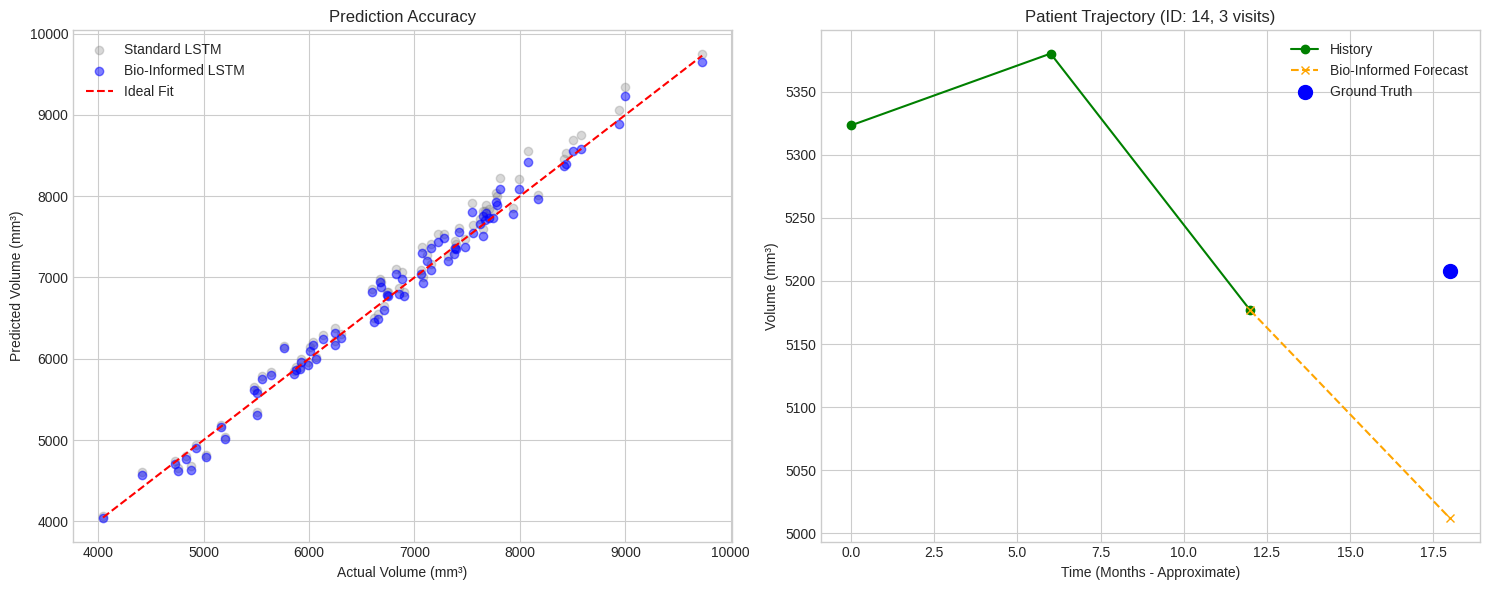

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import os
import random

# === CONFIGURATION ===
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"
# SEQ_LENGTH is removed because it is now variable per patient
BATCH_SIZE = 1        # CRITICAL: Must be 1 to handle variable sequence lengths
EPOCHS = 100
BIO_WEIGHT = 2.0
TOLERANCE_PCT = 0.01
SEED = 42

# === 1. REPRODUCIBILITY SETUP ===
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🌱 Random Seed set to {seed}")

set_seed(SEED)

# === 2. HELPER FUNCTIONS ===
def create_variable_sequences(df):
    """
    CUSTOM LOGIC:
    If 5 time points -> Input: first 4, Target: 5th
    If 4 time points -> Input: first 3, Target: 4th
    """
    sequences = []
    targets = []
    df = df.sort_values(['SubjectID', 'Month'])

    for sub in df['SubjectID'].unique():
        sub_df = df[df['SubjectID'] == sub]
        vols = sub_df['Volume_mm3'].values

        # We need at least 2 points (1 input, 1 target) to do anything
        if len(vols) >= 2:
            # Take ALL points except the last one as Input
            seq = vols[:-1]
            # Take the LAST point as Target
            target = vols[-1]

            sequences.append(seq)
            targets.append(target)

    # Return as a LIST of arrays (because arrays are different lengths)
    return sequences, np.array(targets)

def calculate_metrics(preds, history, tolerance=0.01):
    last_known = history[:, -1]
    growth_mm3 = preds - last_known
    pct_change = growth_mm3 / last_known
    violations = np.sum(pct_change > tolerance)
    violation_rate = (violations / len(preds)) * 100
    positive_growth = growth_mm3[growth_mm3 > 0]
    mpg = np.mean(positive_growth) if len(positive_growth) > 0 else 0.0
    return violation_rate, mpg

# === 3. DATASET & MODELS ===
class AtrophyDataset(Dataset):
    def __init__(self, sequences, targets):
        # Since sequences vary in length, we store them as a list of tensors
        # instead of one big tensor.
        self.seqs = [torch.tensor(s, dtype=torch.float32).unsqueeze(-1) for s in sequences]
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self): return len(self.seqs)

    def __getitem__(self, idx):
        # Returns one sequence at a time
        return self.seqs[idx], self.targets[idx]

class AtrophyLSTM(nn.Module):
    def __init__(self):
        super(AtrophyLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        # LSTM handles variable length inputs automatically
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n.squeeze(0))

class AtrophyGRU(nn.Module):
    def __init__(self):
        super(AtrophyGRU, self).__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        _, h_n = self.gru(x)
        return self.fc(h_n.squeeze(0))

class BiologyInformedLoss(nn.Module):
    def __init__(self, lambda_bio=0.0, tolerance=0.01):
        super(BiologyInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_bio = lambda_bio
        self.tolerance = tolerance

    def forward(self, predictions, targets, inputs):
        data_loss = self.mse(predictions, targets)

        # inputs shape is (1, seq_len, 1)
        # We always want the LAST input point, regardless of seq_len
        last_known_vol = inputs[:, -1, :]

        allowed_growth = last_known_vol * self.tolerance
        excess_growth = (predictions - last_known_vol) - allowed_growth
        violation = torch.relu(excess_growth)
        bio_loss = torch.mean(violation ** 2)
        return data_loss + (self.lambda_bio * bio_loss)

# === 4. TRAINING ENGINE ===
def train_dl_model(model_class, train_loader, test_loader, scaler, lambda_val, label):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = BiologyInformedLoss(lambda_bio=lambda_val, tolerance=TOLERANCE_PCT)

    print(f"\nTraining {label} (Lambda={lambda_val})...")

    for epoch in range(EPOCHS):
        model.train()
        for seqs, targets in train_loader:
            seqs, targets = seqs.to(device), targets.to(device)
            optimizer.zero_grad()
            preds = model(seqs)
            loss = criterion(preds, targets, seqs)
            loss.backward()
            optimizer.step()

    model.eval()
    all_preds = []
    all_actuals = []
    all_histories = []

    with torch.no_grad():
        for seqs, targets in test_loader:
            seqs = seqs.to(device)
            pred_scaled = model(seqs).cpu().numpy()

            # Inverse Transform Prediction
            pred_mm3 = scaler.inverse_transform(pred_scaled)
            target_mm3 = scaler.inverse_transform(targets.numpy().reshape(-1,1))

            # Inverse Transform History (Handle Variable Lengths)
            seq_np = seqs.cpu().numpy() # Shape (1, L, 1)
            L = seq_np.shape[1]

            history_flat = seq_np.reshape(-1, 1)
            history_flat_mm3 = scaler.inverse_transform(history_flat)
            history_mm3 = history_flat_mm3.reshape(1, L)

            all_preds.extend(pred_mm3.flatten())
            all_actuals.extend(target_mm3.flatten())
            all_histories.append(history_mm3)

    # Note: We cannot vstack histories anymore because they have different lengths
    # We keep them as a list for metric calculation

    # Calculate Metrics manually for variable lengths
    total_viol = 0
    total_mpg_sum = 0
    mpg_count = 0

    for i in range(len(all_preds)):
        pred = all_preds[i]
        last = all_histories[i][0, -1] # Last point of this specific history

        growth = pred - last
        pct = growth / last

        if pct > TOLERANCE_PCT:
            total_viol += 1

        if growth > 0:
            total_mpg_sum += growth
            mpg_count += 1

    viol_rate = (total_viol / len(all_preds)) * 100
    mpg = (total_mpg_sum / mpg_count) if mpg_count > 0 else 0.0

    mae = mean_absolute_error(all_actuals, all_preds)
    corr, _ = pearsonr(all_actuals, all_preds)

    return mae, corr, viol_rate, mpg, all_preds, all_actuals, all_histories

# === 5. MAIN EXPERIMENT PIPELINE ===
def run_full_comparison():
    if not os.path.exists(VOL_CSV):
        print(f"❌ Error: CSV not found at {VOL_CSV}")
        return

    # --- A. Data Prep ---
    df = pd.read_csv(VOL_CSV)
    visit_map = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48, 'm60':60}
    df['Month'] = df['Visit'].map(visit_map)
    df = df.dropna(subset=['Month'])

    unique_subs = df['SubjectID'].unique()
    np.random.seed(SEED)
    np.random.shuffle(unique_subs)
    split = int(0.8 * len(unique_subs))
    train_subs, test_subs = unique_subs[:split], unique_subs[split:]

    train_df = df[df['SubjectID'].isin(train_subs)]
    test_df = df[df['SubjectID'].isin(test_subs)]

    # USE NEW VARIABLE LENGTH CREATOR
    X_train, y_train = create_variable_sequences(train_df)
    X_test, y_test = create_variable_sequences(test_df)

    if len(X_train) == 0:
        print("Not enough sequences found.")
        return

    # Scale Data (Trickier with variable lengths)
    # We allow the scaler to fit on ALL training points flattened
    all_train_values = np.concatenate(X_train).reshape(-1, 1)
    scaler = MinMaxScaler()
    scaler.fit(all_train_values)

    # Transform Train/Test lists
    X_train_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_train]
    X_test_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_test]

    y_train_s = scaler.transform(y_train.reshape(-1,1))
    y_test_s = scaler.transform(y_test.reshape(-1,1))

    train_loader = DataLoader(AtrophyDataset(X_train_s, y_train_s), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(AtrophyDataset(X_test_s, y_test_s), batch_size=1, shuffle=False)

    print(f"Dataset: {len(X_train)} Train Subjects | {len(X_test)} Test Subjects\n")
    print("(Linear Regression omitted as it cannot handle variable sequence lengths)")

    results = {}

    # --- MODEL 1: STANDARD GRU ---
    gru_mae, gru_r, gru_viol, gru_mpg, _, _, _ = train_dl_model(AtrophyGRU, train_loader, test_loader, scaler, 0.0, "Standard GRU")
    results["Standard GRU"] = [gru_mae, gru_r, gru_viol, gru_mpg]

    # --- MODEL 2: STANDARD LSTM ---
    lstm_mae, lstm_r, lstm_viol, lstm_mpg, base_preds, _, _ = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, 0.0, "Standard LSTM")
    results["Standard LSTM"] = [lstm_mae, lstm_r, lstm_viol, lstm_mpg]

    # --- MODEL 3: BIO-INFORMED LSTM (Yours) ---
    hyb_mae, hyb_r, hyb_viol, hyb_mpg, hyb_preds, actuals, dl_histories = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, BIO_WEIGHT, "Bio-Informed LSTM")
    results["Bio-Informed LSTM"] = [hyb_mae, hyb_r, hyb_viol, hyb_mpg]

    # === PRINT COMPARISON ===
    print("\n" + "="*100)
    print(f"{'MODEL':<25} | {'MAE (Error)':<15} | {'CORRELATION':<15} | {'VIOLATION (%)':<15} | {'MPG (Severity)':<15}")
    print("-" * 100)
    for name, metrics in results.items():
        print(f"{name:<25} | {metrics[0]:.2f} mm³       | {metrics[1]:.4f}          | {metrics[2]:.1f}%           | {metrics[3]:.2f} mm³")
    print("="*100)

    # === VISUALIZATION ===
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Plot 1: Scatter Comparison
    axes[0].scatter(actuals, base_preds, alpha=0.3, color='gray', label='Standard LSTM')
    axes[0].scatter(actuals, hyb_preds, alpha=0.5, color='blue', label='Bio-Informed LSTM')
    min_val = min(actuals)
    max_val = max(actuals)
    axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
    axes[0].set_title("Prediction Accuracy")
    axes[0].set_xlabel("Actual Volume (mm³)")
    axes[0].set_ylabel("Predicted Volume (mm³)")
    axes[0].legend()

    # Plot 2: Trajectory Example (Random Patient)
    idx = random.randint(0, len(actuals)-1)

    # DYNAMIC TIME AXIS for variable length history
    # We assume roughly 6 months between visits for plotting purposes
    history_len = dl_histories[idx].shape[1]
    time_x = [i*6 for i in range(history_len)]

    axes[1].plot(time_x, dl_histories[idx][0], 'o-', color='green', label='History')

    next_time = time_x[-1] + 6
    axes[1].plot([time_x[-1], next_time], [dl_histories[idx][0, -1], hyb_preds[idx]], 'x--', color='orange', label='Bio-Informed Forecast')
    axes[1].scatter([next_time], [actuals[idx]], color='blue', s=100, label='Ground Truth')

    axes[1].set_title(f"Patient Trajectory (ID: {idx}, {history_len} visits)")
    axes[1].set_xlabel("Time (Months - Approximate)")
    axes[1].set_ylabel("Volume (mm³)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    run_full_comparison()

🌱 Random Seed set to 42
Dataset: 305 Train Subjects | 77 Test Subjects


Training Standard GRU (Lambda=0.0)...

Training Standard LSTM (Lambda=0.0)...

Training Bio-Informed LSTM (Lambda=2.0)...

MODEL                     | MAE (Error)     | CORRELATION     | VIOLATION (%)   | MPG (Severity) 
----------------------------------------------------------------------------------------------------
Standard GRU              | 130.99 mm³       | 0.9931          | 3.9%           | 49.42 mm³
Standard LSTM             | 140.13 mm³       | 0.9931          | 7.8%           | 67.60 mm³
Bio-Informed LSTM         | 116.24 mm³       | 0.9932          | 1.3%           | 31.94 mm³


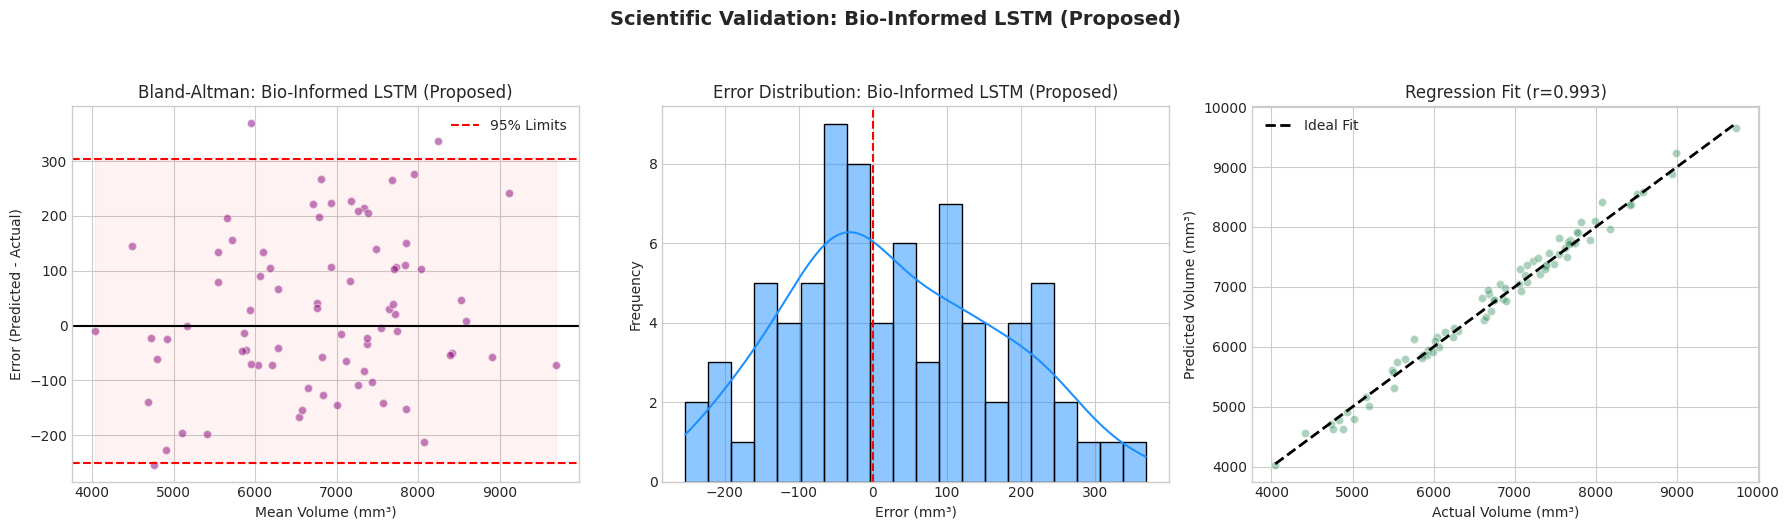

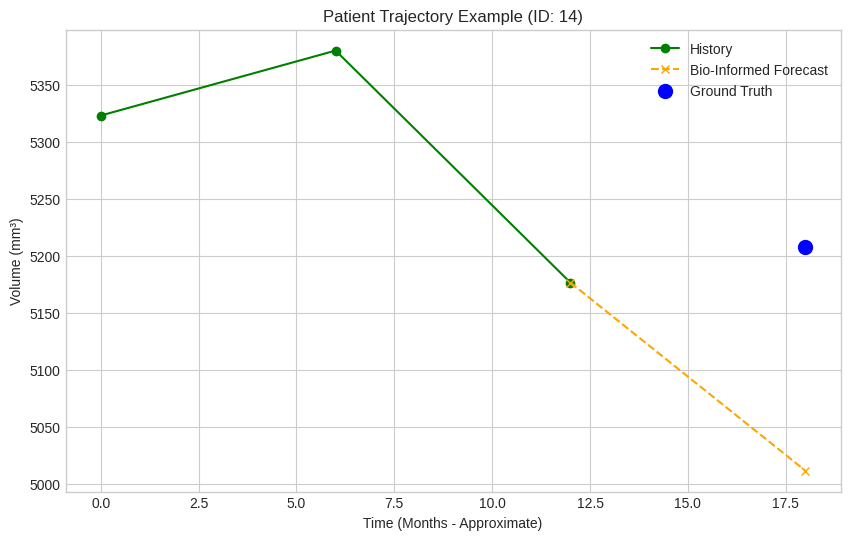

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

# === CONFIGURATION ===
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"
BATCH_SIZE = 1        # CRITICAL: Must be 1 for variable sequence lengths
EPOCHS = 100
BIO_WEIGHT = 2.0
TOLERANCE_PCT = 0.01
SEED = 42

# === 1. REPRODUCIBILITY SETUP ===
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🌱 Random Seed set to {seed}")

set_seed(SEED)

# === 2. HELPER FUNCTIONS ===
def create_variable_sequences(df):
    """
    CUSTOM LOGIC: Variable Length Input
    Takes (t_0 ... t_n-1) as Input -> Predicts (t_n)
    """
    sequences = []
    targets = []
    df = df.sort_values(['SubjectID', 'Month'])

    for sub in df['SubjectID'].unique():
        sub_df = df[df['SubjectID'] == sub]
        vols = sub_df['Volume_mm3'].values

        # We need at least 2 points (1 input, 1 target) to do anything
        if len(vols) >= 2:
            seq = vols[:-1]
            target = vols[-1]
            sequences.append(seq)
            targets.append(target)

    return sequences, np.array(targets)

def calculate_metrics(preds, history, tolerance=0.01):
    last_known = history[:, -1]
    growth_mm3 = preds - last_known
    pct_change = growth_mm3 / last_known
    violations = np.sum(pct_change > tolerance)
    violation_rate = (violations / len(preds)) * 100
    positive_growth = growth_mm3[growth_mm3 > 0]
    mpg = np.mean(positive_growth) if len(positive_growth) > 0 else 0.0
    return violation_rate, mpg

# === 3. DATASET & MODELS ===
class AtrophyDataset(Dataset):
    def __init__(self, sequences, targets):
        self.seqs = [torch.tensor(s, dtype=torch.float32).unsqueeze(-1) for s in sequences]
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self): return len(self.seqs)

    def __getitem__(self, idx):
        return self.seqs[idx], self.targets[idx]

class AtrophyLSTM(nn.Module):
    def __init__(self):
        super(AtrophyLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n.squeeze(0))

class AtrophyGRU(nn.Module):
    def __init__(self):
        super(AtrophyGRU, self).__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        _, h_n = self.gru(x)
        return self.fc(h_n.squeeze(0))

class BiologyInformedLoss(nn.Module):
    def __init__(self, lambda_bio=0.0, tolerance=0.01):
        super(BiologyInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_bio = lambda_bio
        self.tolerance = tolerance

    def forward(self, predictions, targets, inputs):
        data_loss = self.mse(predictions, targets)
        last_known_vol = inputs[:, -1, :]
        allowed_growth = last_known_vol * self.tolerance
        excess_growth = (predictions - last_known_vol) - allowed_growth
        violation = torch.relu(excess_growth)
        bio_loss = torch.mean(violation ** 2)
        return data_loss + (self.lambda_bio * bio_loss)

# === 4. TRAINING ENGINE ===
def train_dl_model(model_class, train_loader, test_loader, scaler, lambda_val, label):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = BiologyInformedLoss(lambda_bio=lambda_val, tolerance=TOLERANCE_PCT)

    print(f"\nTraining {label} (Lambda={lambda_val})...")

    for epoch in range(EPOCHS):
        model.train()
        for seqs, targets in train_loader:
            seqs, targets = seqs.to(device), targets.to(device)
            optimizer.zero_grad()
            preds = model(seqs)
            loss = criterion(preds, targets, seqs)
            loss.backward()
            optimizer.step()

    model.eval()
    all_preds = []
    all_actuals = []
    all_histories = []

    with torch.no_grad():
        for seqs, targets in test_loader:
            seqs = seqs.to(device)
            pred_scaled = model(seqs).cpu().numpy()

            pred_mm3 = scaler.inverse_transform(pred_scaled)
            target_mm3 = scaler.inverse_transform(targets.numpy().reshape(-1,1))

            seq_np = seqs.cpu().numpy()

            history_flat = seq_np.reshape(-1, 1)
            history_flat_mm3 = scaler.inverse_transform(history_flat)
            history_mm3 = history_flat_mm3.reshape(1, -1) # Variable length

            all_preds.extend(pred_mm3.flatten())
            all_actuals.extend(target_mm3.flatten())
            all_histories.append(history_mm3)

    # Calculate Metrics manually for variable lengths
    total_viol = 0
    total_mpg_sum = 0
    mpg_count = 0

    for i in range(len(all_preds)):
        pred = all_preds[i]
        last = all_histories[i][0, -1]

        growth = pred - last
        pct = growth / last

        if pct > TOLERANCE_PCT:
            total_viol += 1

        if growth > 0:
            total_mpg_sum += growth
            mpg_count += 1

    viol_rate = (total_viol / len(all_preds)) * 100
    mpg = (total_mpg_sum / mpg_count) if mpg_count > 0 else 0.0
    mae = mean_absolute_error(all_actuals, all_preds)
    corr, _ = pearsonr(all_actuals, all_preds)

    return mae, corr, viol_rate, mpg, all_preds, all_actuals, all_histories

# === 5. PLOTTING FUNCTION (THE NEW ADDITION) ===
def generate_thesis_plots(actuals, preds, model_name):
    actuals = np.array(actuals)
    preds = np.array(preds)
    errors = preds - actuals
    means = (preds + actuals) / 2

    # Use seaborn for professional academic styling
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- Plot 1: Bland-Altman (Bias Check) ---
    axes[0].scatter(means, errors, alpha=0.5, color='purple', edgecolor='w')
    axes[0].axhline(0, color='black', linestyle='-', linewidth=1.5)

    # Calculate limits of agreement
    mean_error = np.mean(errors)
    std_error = np.std(errors)
    upper_loa = mean_error + 1.96 * std_error
    lower_loa = mean_error - 1.96 * std_error

    axes[0].axhline(upper_loa, color='red', linestyle='--', label='95% Limits')
    axes[0].axhline(lower_loa, color='red', linestyle='--')
    axes[0].fill_between([min(means), max(means)], lower_loa, upper_loa, color='red', alpha=0.05)

    axes[0].set_title(f"Bland-Altman: {model_name}")
    axes[0].set_xlabel("Mean Volume (mm³)")
    axes[0].set_ylabel("Error (Predicted - Actual)")
    axes[0].legend()

    # --- Plot 2: Error Histogram (Reliability) ---
    sns.histplot(errors, kde=True, ax=axes[1], color='dodgerblue', bins=20, edgecolor='black')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title(f"Error Distribution: {model_name}")
    axes[1].set_xlabel("Error (mm³)")
    axes[1].set_ylabel("Frequency")

    # --- Plot 3: Regression Fit (Correlation) ---
    axes[2].scatter(actuals, preds, alpha=0.4, color='seagreen', edgecolor='w')

    # Ideal line
    min_val, max_val = min(actuals), max(actuals)
    axes[2].plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal Fit', linewidth=2)

    axes[2].set_title(f"Regression Fit (r={np.corrcoef(actuals, preds)[0,1]:.3f})")
    axes[2].set_xlabel("Actual Volume (mm³)")
    axes[2].set_ylabel("Predicted Volume (mm³)")
    axes[2].legend()

    plt.suptitle(f"Scientific Validation: {model_name}", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

# === 6. MAIN EXPERIMENT PIPELINE ===
def run_full_comparison():
    if not os.path.exists(VOL_CSV):
        print(f"❌ Error: CSV not found at {VOL_CSV}")
        return

    # --- A. Data Prep ---
    df = pd.read_csv(VOL_CSV)
    visit_map = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48, 'm60':60}
    df['Month'] = df['Visit'].map(visit_map)
    df = df.dropna(subset=['Month'])

    unique_subs = df['SubjectID'].unique()
    np.random.seed(SEED)
    np.random.shuffle(unique_subs)
    split = int(0.8 * len(unique_subs))
    train_subs, test_subs = unique_subs[:split], unique_subs[split:]

    train_df = df[df['SubjectID'].isin(train_subs)]
    test_df = df[df['SubjectID'].isin(test_subs)]

    X_train, y_train = create_variable_sequences(train_df)
    X_test, y_test = create_variable_sequences(test_df)

    if len(X_train) == 0:
        print("Not enough sequences found.")
        return

    # Scale Data
    all_train_values = np.concatenate(X_train).reshape(-1, 1)
    scaler = MinMaxScaler()
    scaler.fit(all_train_values)

    X_train_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_train]
    X_test_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_test]
    y_train_s = scaler.transform(y_train.reshape(-1,1))
    y_test_s = scaler.transform(y_test.reshape(-1,1))

    train_loader = DataLoader(AtrophyDataset(X_train_s, y_train_s), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(AtrophyDataset(X_test_s, y_test_s), batch_size=1, shuffle=False)

    print(f"Dataset: {len(X_train)} Train Subjects | {len(X_test)} Test Subjects\n")

    results = {}

    # --- MODEL 1: STANDARD GRU ---
    gru_mae, gru_r, gru_viol, gru_mpg, _, _, _ = train_dl_model(AtrophyGRU, train_loader, test_loader, scaler, 0.0, "Standard GRU")
    results["Standard GRU"] = [gru_mae, gru_r, gru_viol, gru_mpg]

    # --- MODEL 2: STANDARD LSTM ---
    lstm_mae, lstm_r, lstm_viol, lstm_mpg, base_preds, _, _ = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, 0.0, "Standard LSTM")
    results["Standard LSTM"] = [lstm_mae, lstm_r, lstm_viol, lstm_mpg]

    # --- MODEL 3: BIO-INFORMED LSTM (Yours) ---
    hyb_mae, hyb_r, hyb_viol, hyb_mpg, hyb_preds, actuals, dl_histories = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, BIO_WEIGHT, "Bio-Informed LSTM")
    results["Bio-Informed LSTM"] = [hyb_mae, hyb_r, hyb_viol, hyb_mpg]

    # === PRINT COMPARISON TABLE ===
    print("\n" + "="*100)
    print(f"{'MODEL':<25} | {'MAE (Error)':<15} | {'CORRELATION':<15} | {'VIOLATION (%)':<15} | {'MPG (Severity)':<15}")
    print("-" * 100)
    for name, metrics in results.items():
        print(f"{name:<25} | {metrics[0]:.2f} mm³       | {metrics[1]:.4f}          | {metrics[2]:.1f}%           | {metrics[3]:.2f} mm³")
    print("="*100)

    # === GENERATE THESIS PLOTS ===
    # 1. Generate the Scientific Validation Plots for your proposed model
    generate_thesis_plots(actuals, hyb_preds, "Bio-Informed LSTM (Proposed)")

    # 2. Generate the Trajectory Example for illustration
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(10, 6))
    idx = random.randint(0, len(actuals)-1)

    history_len = dl_histories[idx].shape[1]
    time_x = [i*6 for i in range(history_len)]

    plt.plot(time_x, dl_histories[idx][0], 'o-', color='green', label='History')
    next_time = time_x[-1] + 6
    plt.plot([time_x[-1], next_time], [dl_histories[idx][0, -1], hyb_preds[idx]], 'x--', color='orange', label='Bio-Informed Forecast')
    plt.scatter([next_time], [actuals[idx]], color='blue', s=100, label='Ground Truth')

    plt.title(f"Patient Trajectory Example (ID: {idx})")
    plt.xlabel("Time (Months - Approximate)")
    plt.ylabel("Volume (mm³)")
    plt.legend()
    plt.show()

if __name__ == "__main__":
    run_full_comparison()

🌱 Random Seed set to 42
Dataset: 305 Train Subjects | 77 Test Subjects


Training Bio-Informed LSTM (Lambda=2.0)...

Training Standard GRU (Lambda=0.0)...

Training Standard LSTM (Lambda=0.0)...

MODEL                     | MAE (Error)     | CORRELATION     | VIOLATION (%)   | MPG (Severity) 
--------------------------------------------------------------------------------------------------------------
Naive Baseline (LOCF)     | 170.00 mm³       | 0.9922          | 0.0%           | 0.00 mm³
Standard GRU              | 135.73 mm³       | 0.9930          | 6.5%           | 58.18 mm³
Standard LSTM             | 114.96 mm³       | 0.9932          | 1.3%           | 39.60 mm³
Bio-Informed LSTM         | 141.65 mm³       | 0.9931          | 2.6%           | 50.73 mm³


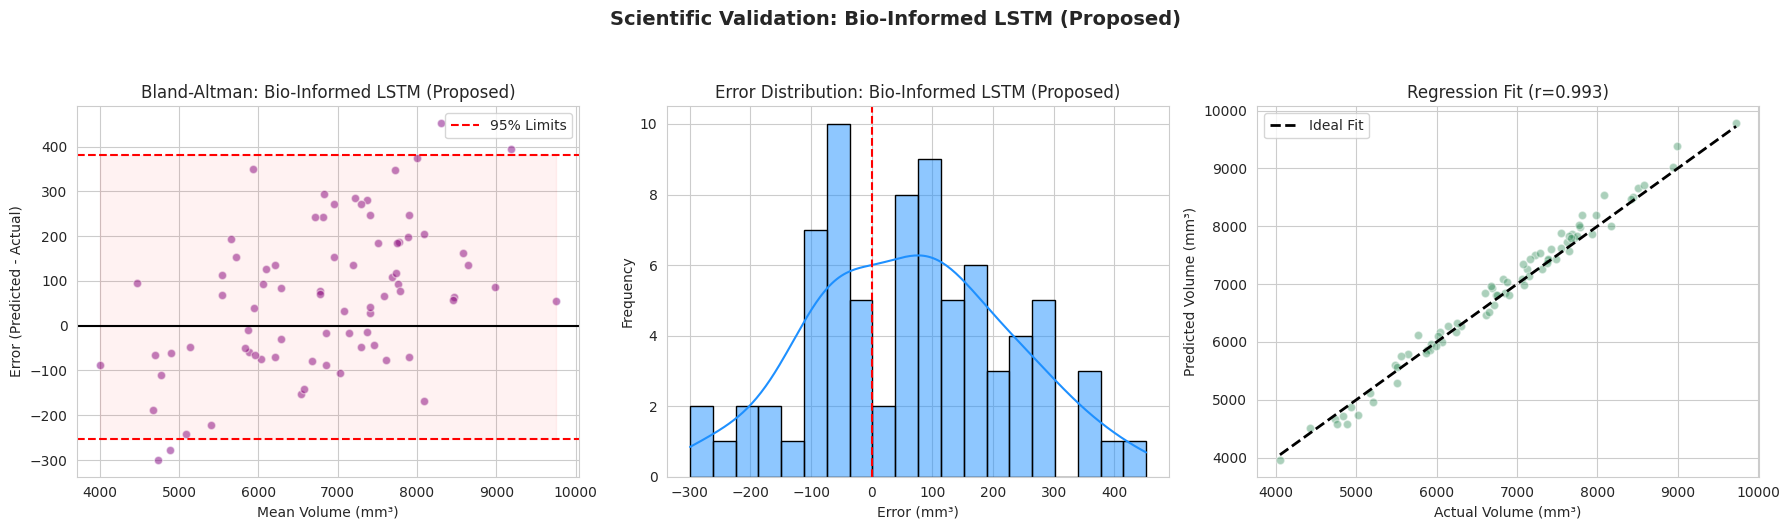

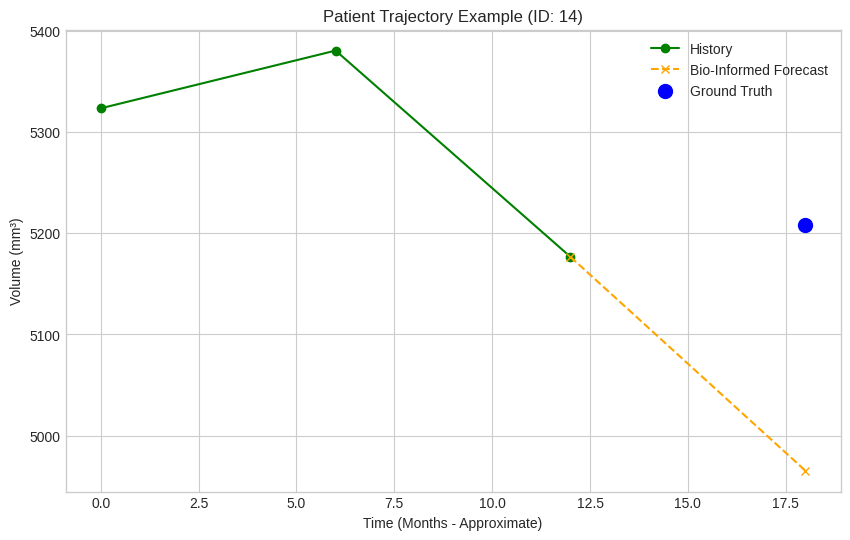

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

# === CONFIGURATION ===
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"
BATCH_SIZE = 1        # CRITICAL: Must be 1 for variable sequence lengths
EPOCHS = 100
BIO_WEIGHT = 2.0
TOLERANCE_PCT = 0.01
SEED = 42

# === 1. REPRODUCIBILITY SETUP ===
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🌱 Random Seed set to {seed}")

set_seed(SEED)

# === 2. HELPER FUNCTIONS ===
def create_variable_sequences(df):
    """
    CUSTOM LOGIC: Variable Length Input
    Takes (t_0 ... t_n-1) as Input -> Predicts (t_n)
    """
    sequences = []
    targets = []
    df = df.sort_values(['SubjectID', 'Month'])

    for sub in df['SubjectID'].unique():
        sub_df = df[df['SubjectID'] == sub]
        vols = sub_df['Volume_mm3'].values

        # We need at least 2 points (1 input, 1 target) to do anything
        if len(vols) >= 2:
            seq = vols[:-1]
            target = vols[-1]
            sequences.append(seq)
            targets.append(target)

    return sequences, np.array(targets)

def calculate_metrics(preds, history_list, tolerance=0.01):
    """
    Calculates metrics given a list of variable-length histories.
    """
    # FIX: Extract the last value from each array in the list
    # history_list is a list of arrays, each shape (1, Length)
    last_known = np.array([h[0, -1] for h in history_list])

    growth_mm3 = preds - last_known
    pct_change = growth_mm3 / last_known

    violations = np.sum(pct_change > tolerance)
    violation_rate = (violations / len(preds)) * 100

    positive_growth = growth_mm3[growth_mm3 > 0]
    mpg = np.mean(positive_growth) if len(positive_growth) > 0 else 0.0

    return violation_rate, mpg

# === 3. DATASET & MODELS ===
class AtrophyDataset(Dataset):
    def __init__(self, sequences, targets):
        self.seqs = [torch.tensor(s, dtype=torch.float32).unsqueeze(-1) for s in sequences]
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self): return len(self.seqs)

    def __getitem__(self, idx):
        return self.seqs[idx], self.targets[idx]

class AtrophyLSTM(nn.Module):
    def __init__(self):
        super(AtrophyLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n.squeeze(0))

class AtrophyGRU(nn.Module):
    def __init__(self):
        super(AtrophyGRU, self).__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        _, h_n = self.gru(x)
        return self.fc(h_n.squeeze(0))

class BiologyInformedLoss(nn.Module):
    def __init__(self, lambda_bio=0.0, tolerance=0.01):
        super(BiologyInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_bio = lambda_bio
        self.tolerance = tolerance

    def forward(self, predictions, targets, inputs):
        data_loss = self.mse(predictions, targets)
        last_known_vol = inputs[:, -1, :]
        allowed_growth = last_known_vol * self.tolerance
        excess_growth = (predictions - last_known_vol) - allowed_growth
        violation = torch.relu(excess_growth)
        bio_loss = torch.mean(violation ** 2)
        return data_loss + (self.lambda_bio * bio_loss)

# === 4. TRAINING ENGINE ===
def train_dl_model(model_class, train_loader, test_loader, scaler, lambda_val, label):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = BiologyInformedLoss(lambda_bio=lambda_val, tolerance=TOLERANCE_PCT)

    print(f"\nTraining {label} (Lambda={lambda_val})...")

    for epoch in range(EPOCHS):
        model.train()
        for seqs, targets in train_loader:
            seqs, targets = seqs.to(device), targets.to(device)
            optimizer.zero_grad()
            preds = model(seqs)
            loss = criterion(preds, targets, seqs)
            loss.backward()
            optimizer.step()

    model.eval()
    all_preds = []
    all_actuals = []
    all_histories = [] # List of arrays

    with torch.no_grad():
        for seqs, targets in test_loader:
            seqs = seqs.to(device)
            pred_scaled = model(seqs).cpu().numpy()

            pred_mm3 = scaler.inverse_transform(pred_scaled)
            target_mm3 = scaler.inverse_transform(targets.numpy().reshape(-1,1))

            seq_np = seqs.cpu().numpy()

            history_flat = seq_np.reshape(-1, 1)
            history_flat_mm3 = scaler.inverse_transform(history_flat)
            history_mm3 = history_flat_mm3.reshape(1, -1) # Variable length

            all_preds.extend(pred_mm3.flatten())
            all_actuals.extend(target_mm3.flatten())
            all_histories.append(history_mm3)

    # Convert preds to numpy for easier handling
    all_preds = np.array(all_preds)
    all_actuals = np.array(all_actuals)

    # Calculate Metrics using the FIXED function
    viol_rate, mpg = calculate_metrics(all_preds, all_histories, tolerance=TOLERANCE_PCT)
    mae = mean_absolute_error(all_actuals, all_preds)
    corr, _ = pearsonr(all_actuals, all_preds)

    return mae, corr, viol_rate, mpg, all_preds, all_actuals, all_histories

# === 5. PLOTTING FUNCTION ===
def generate_thesis_plots(actuals, preds, model_name):
    actuals = np.array(actuals)
    preds = np.array(preds)
    errors = preds - actuals
    means = (preds + actuals) / 2

    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- Plot 1: Bland-Altman ---
    axes[0].scatter(means, errors, alpha=0.5, color='purple', edgecolor='w')
    axes[0].axhline(0, color='black', linestyle='-', linewidth=1.5)

    mean_error = np.mean(errors)
    std_error = np.std(errors)
    upper_loa = mean_error + 1.96 * std_error
    lower_loa = mean_error - 1.96 * std_error

    axes[0].axhline(upper_loa, color='red', linestyle='--', label='95% Limits')
    axes[0].axhline(lower_loa, color='red', linestyle='--')
    axes[0].fill_between([min(means), max(means)], lower_loa, upper_loa, color='red', alpha=0.05)

    axes[0].set_title(f"Bland-Altman: {model_name}")
    axes[0].set_xlabel("Mean Volume (mm³)")
    axes[0].set_ylabel("Error (Predicted - Actual)")
    axes[0].legend()

    # --- Plot 2: Error Histogram ---
    sns.histplot(errors, kde=True, ax=axes[1], color='dodgerblue', bins=20, edgecolor='black')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title(f"Error Distribution: {model_name}")
    axes[1].set_xlabel("Error (mm³)")
    axes[1].set_ylabel("Frequency")

    # --- Plot 3: Regression Fit ---
    axes[2].scatter(actuals, preds, alpha=0.4, color='seagreen', edgecolor='w')
    min_val, max_val = min(actuals), max(actuals)
    axes[2].plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal Fit', linewidth=2)

    axes[2].set_title(f"Regression Fit (r={np.corrcoef(actuals, preds)[0,1]:.3f})")
    axes[2].set_xlabel("Actual Volume (mm³)")
    axes[2].set_ylabel("Predicted Volume (mm³)")
    axes[2].legend()

    plt.suptitle(f"Scientific Validation: {model_name}", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

# === 6. MAIN EXPERIMENT PIPELINE ===
def run_full_comparison():
    if not os.path.exists(VOL_CSV):
        print(f"❌ Error: CSV not found at {VOL_CSV}")
        return

    # --- A. Data Prep ---
    df = pd.read_csv(VOL_CSV)
    visit_map = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48, 'm60':60}
    df['Month'] = df['Visit'].map(visit_map)
    df = df.dropna(subset=['Month'])

    unique_subs = df['SubjectID'].unique()
    np.random.seed(SEED)
    np.random.shuffle(unique_subs)
    split = int(0.8 * len(unique_subs))
    train_subs, test_subs = unique_subs[:split], unique_subs[split:]

    train_df = df[df['SubjectID'].isin(train_subs)]
    test_df = df[df['SubjectID'].isin(test_subs)]

    X_train, y_train = create_variable_sequences(train_df)
    X_test, y_test = create_variable_sequences(test_df)

    if len(X_train) == 0:
        print("Not enough sequences found.")
        return

    # Scale Data
    all_train_values = np.concatenate(X_train).reshape(-1, 1)
    scaler = MinMaxScaler()
    scaler.fit(all_train_values)

    X_train_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_train]
    X_test_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_test]
    y_train_s = scaler.transform(y_train.reshape(-1,1))
    y_test_s = scaler.transform(y_test.reshape(-1,1))

    train_loader = DataLoader(AtrophyDataset(X_train_s, y_train_s), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(AtrophyDataset(X_test_s, y_test_s), batch_size=1, shuffle=False)

    print(f"Dataset: {len(X_train)} Train Subjects | {len(X_test)} Test Subjects\n")

    results = {}

    # --- MODEL 1: BIO-INFORMED LSTM (Yours) ---
    hyb_mae, hyb_r, hyb_viol, hyb_mpg, hyb_preds, actuals, dl_histories = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, BIO_WEIGHT, "Bio-Informed LSTM")
    results["Bio-Informed LSTM"] = [hyb_mae, hyb_r, hyb_viol, hyb_mpg]

    # --- MODEL 2: NAIVE BASELINE (LOCF) ---
    naive_preds = []
    naive_actuals = []

    for i in range(len(actuals)):
        # Extract Last Value using [0, -1] indexing on the array inside the list
        last_known = dl_histories[i][0, -1]
        naive_preds.append(last_known)
        naive_actuals.append(actuals[i])

    naive_preds = np.array(naive_preds)
    naive_actuals = np.array(naive_actuals)

    naive_mae = mean_absolute_error(naive_actuals, naive_preds)
    naive_r, _ = pearsonr(naive_actuals, naive_preds)
    naive_viol, naive_mpg = calculate_metrics(naive_preds, dl_histories, tolerance=TOLERANCE_PCT)

    results["Naive Baseline (LOCF)"] = [naive_mae, naive_r, naive_viol, naive_mpg]

    # --- MODEL 3: STANDARD GRU ---
    gru_mae, gru_r, gru_viol, gru_mpg, _, _, _ = train_dl_model(AtrophyGRU, train_loader, test_loader, scaler, 0.0, "Standard GRU")
    results["Standard GRU"] = [gru_mae, gru_r, gru_viol, gru_mpg]

    # --- MODEL 4: STANDARD LSTM ---
    lstm_mae, lstm_r, lstm_viol, lstm_mpg, base_preds, _, _ = train_dl_model(AtrophyLSTM, train_loader, test_loader, scaler, 0.0, "Standard LSTM")
    results["Standard LSTM"] = [lstm_mae, lstm_r, lstm_viol, lstm_mpg]


    # === PRINT COMPARISON TABLE ===
    print("\n" + "="*110)
    print(f"{'MODEL':<25} | {'MAE (Error)':<15} | {'CORRELATION':<15} | {'VIOLATION (%)':<15} | {'MPG (Severity)':<15}")
    print("-" * 110)
    order = ["Naive Baseline (LOCF)", "Standard GRU", "Standard LSTM", "Bio-Informed LSTM"]
    for name in order:
        if name in results:
            metrics = results[name]
            print(f"{name:<25} | {metrics[0]:.2f} mm³       | {metrics[1]:.4f}          | {metrics[2]:.1f}%           | {metrics[3]:.2f} mm³")
    print("="*110)

    # === GENERATE THESIS PLOTS ===
    generate_thesis_plots(actuals, hyb_preds, "Bio-Informed LSTM (Proposed)")

    # Trajectory Example
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(10, 6))
    idx = random.randint(0, len(actuals)-1)

    history_len = dl_histories[idx].shape[1]
    time_x = [i*6 for i in range(history_len)]

    plt.plot(time_x, dl_histories[idx][0], 'o-', color='green', label='History')
    next_time = time_x[-1] + 6

    plt.plot([time_x[-1], next_time], [dl_histories[idx][0, -1], hyb_preds[idx]], 'x--', color='orange', label='Bio-Informed Forecast')
    plt.scatter([next_time], [actuals[idx]], color='blue', s=100, label='Ground Truth')

    plt.title(f"Patient Trajectory Example (ID: {idx})")
    plt.xlabel("Time (Months - Approximate)")
    plt.ylabel("Volume (mm³)")
    plt.legend()
    plt.show()

if __name__ == "__main__":
    run_full_comparison()

🌱 Random Seed set to 42

--- Running Statistical Baselines ---

--- Running Deep Learning Models ---
Training Standard GRU (Lambda=0.0)...
Training Standard LSTM (Lambda=0.0)...
Training Standard Bi-LSTM (Lambda=0.0)...
Training Bio-Informed GRU (Lambda=2.0)...
Training Bio-Informed LSTM (Lambda=2.0)...

MODEL                  | MAE (Error)  | CORRELATION  | VIOLATION (%)   | MPG (Severity) 
-----------------------------------------------------------------------------------------------
LOCF                   | 200.61 mm³    | 0.9856       | 0.0%            | 0.00 mm³
Linear Regression      | 974.60 mm³    | -0.2687       | 37.7%            | 837.02 mm³
LME                    | 1021.91 mm³    | -0.2687       | 32.5%            | 806.66 mm³
ARIMA                  | 198.47 mm³    | 0.9858       | 13.0%            | 63.98 mm³
XGBoost                | 175.57 mm³    | 0.9823       | 1.3%            | 67.07 mm³
Standard GRU           | 188.39 mm³    | 0.9873       | 0.0%            | 0.00 mm³

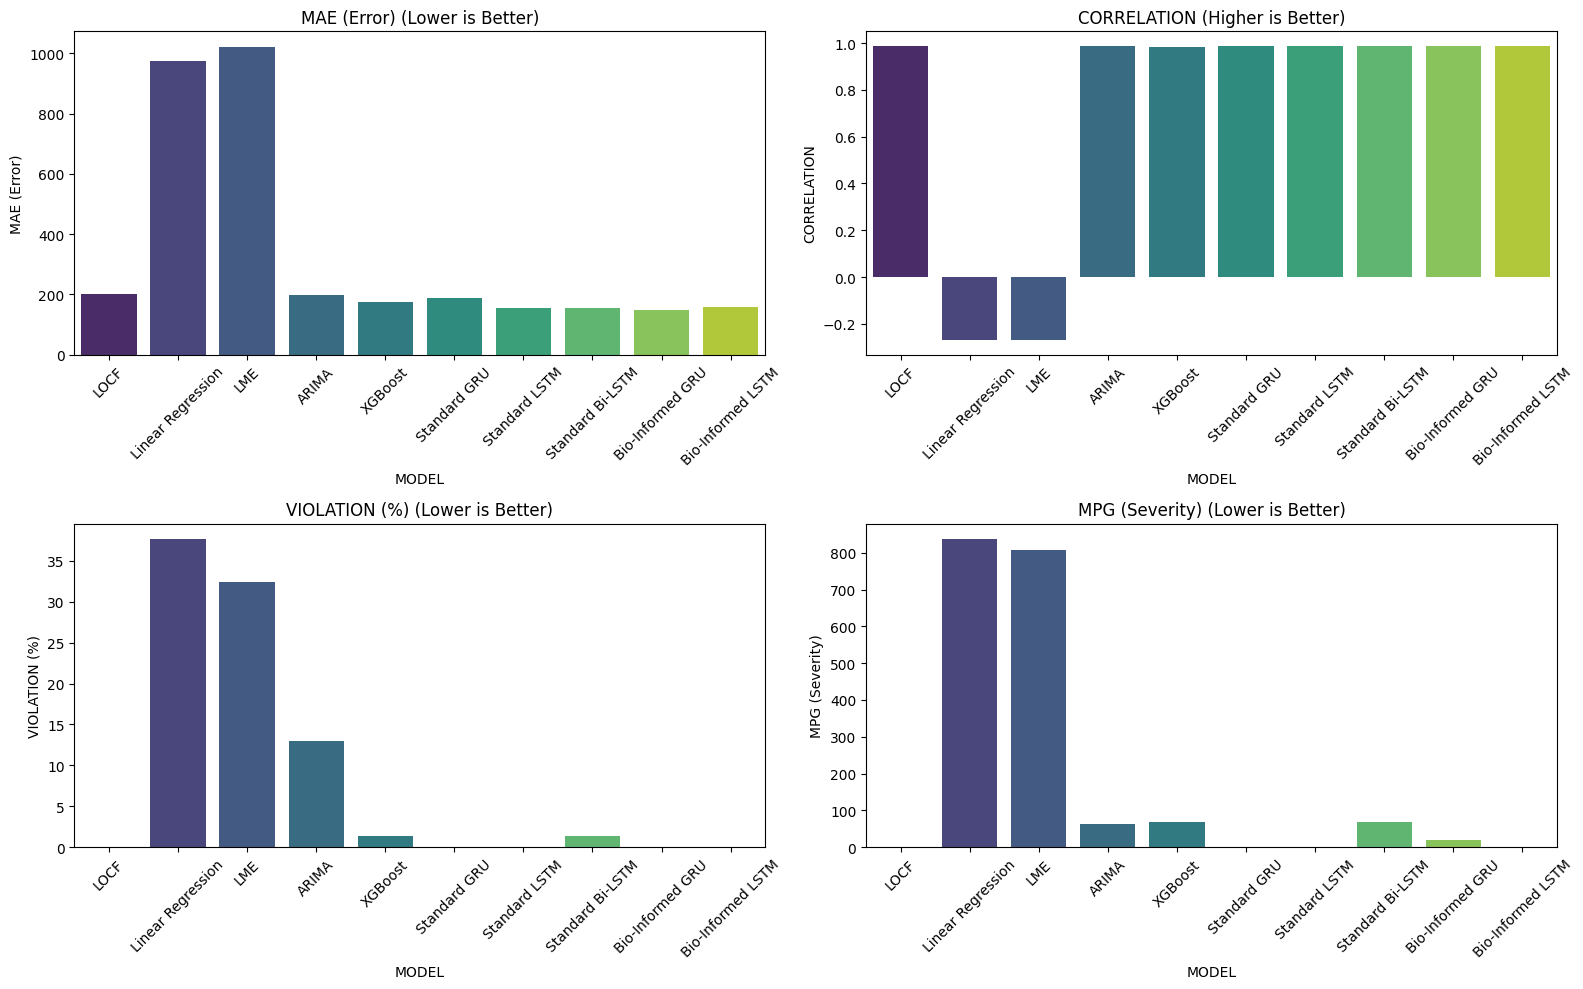

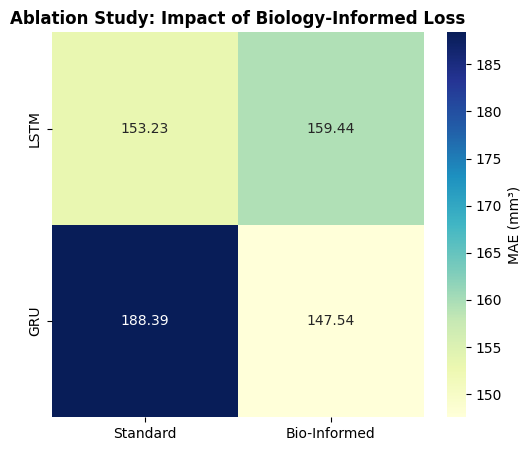

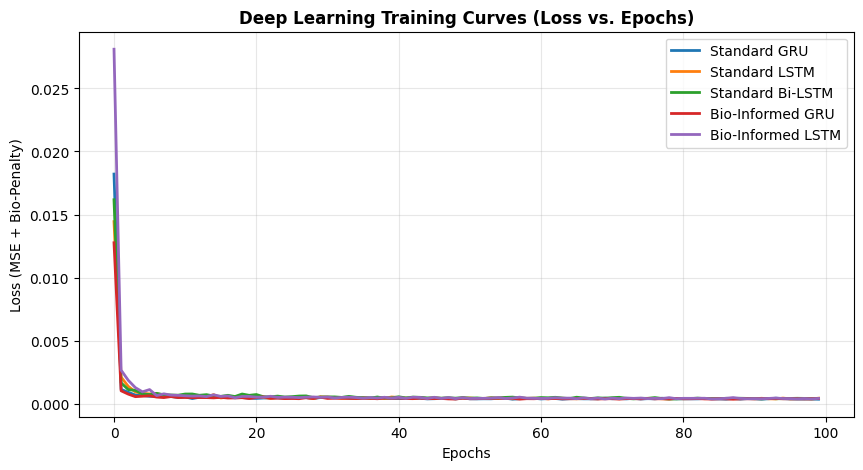

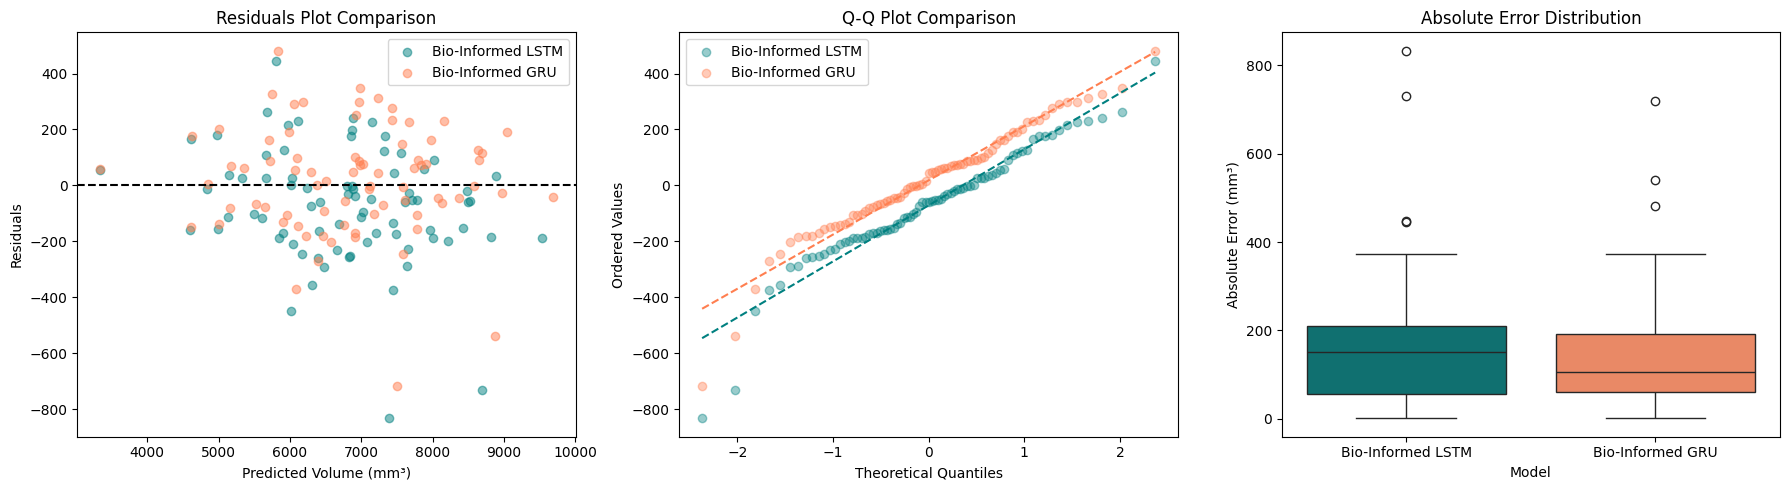

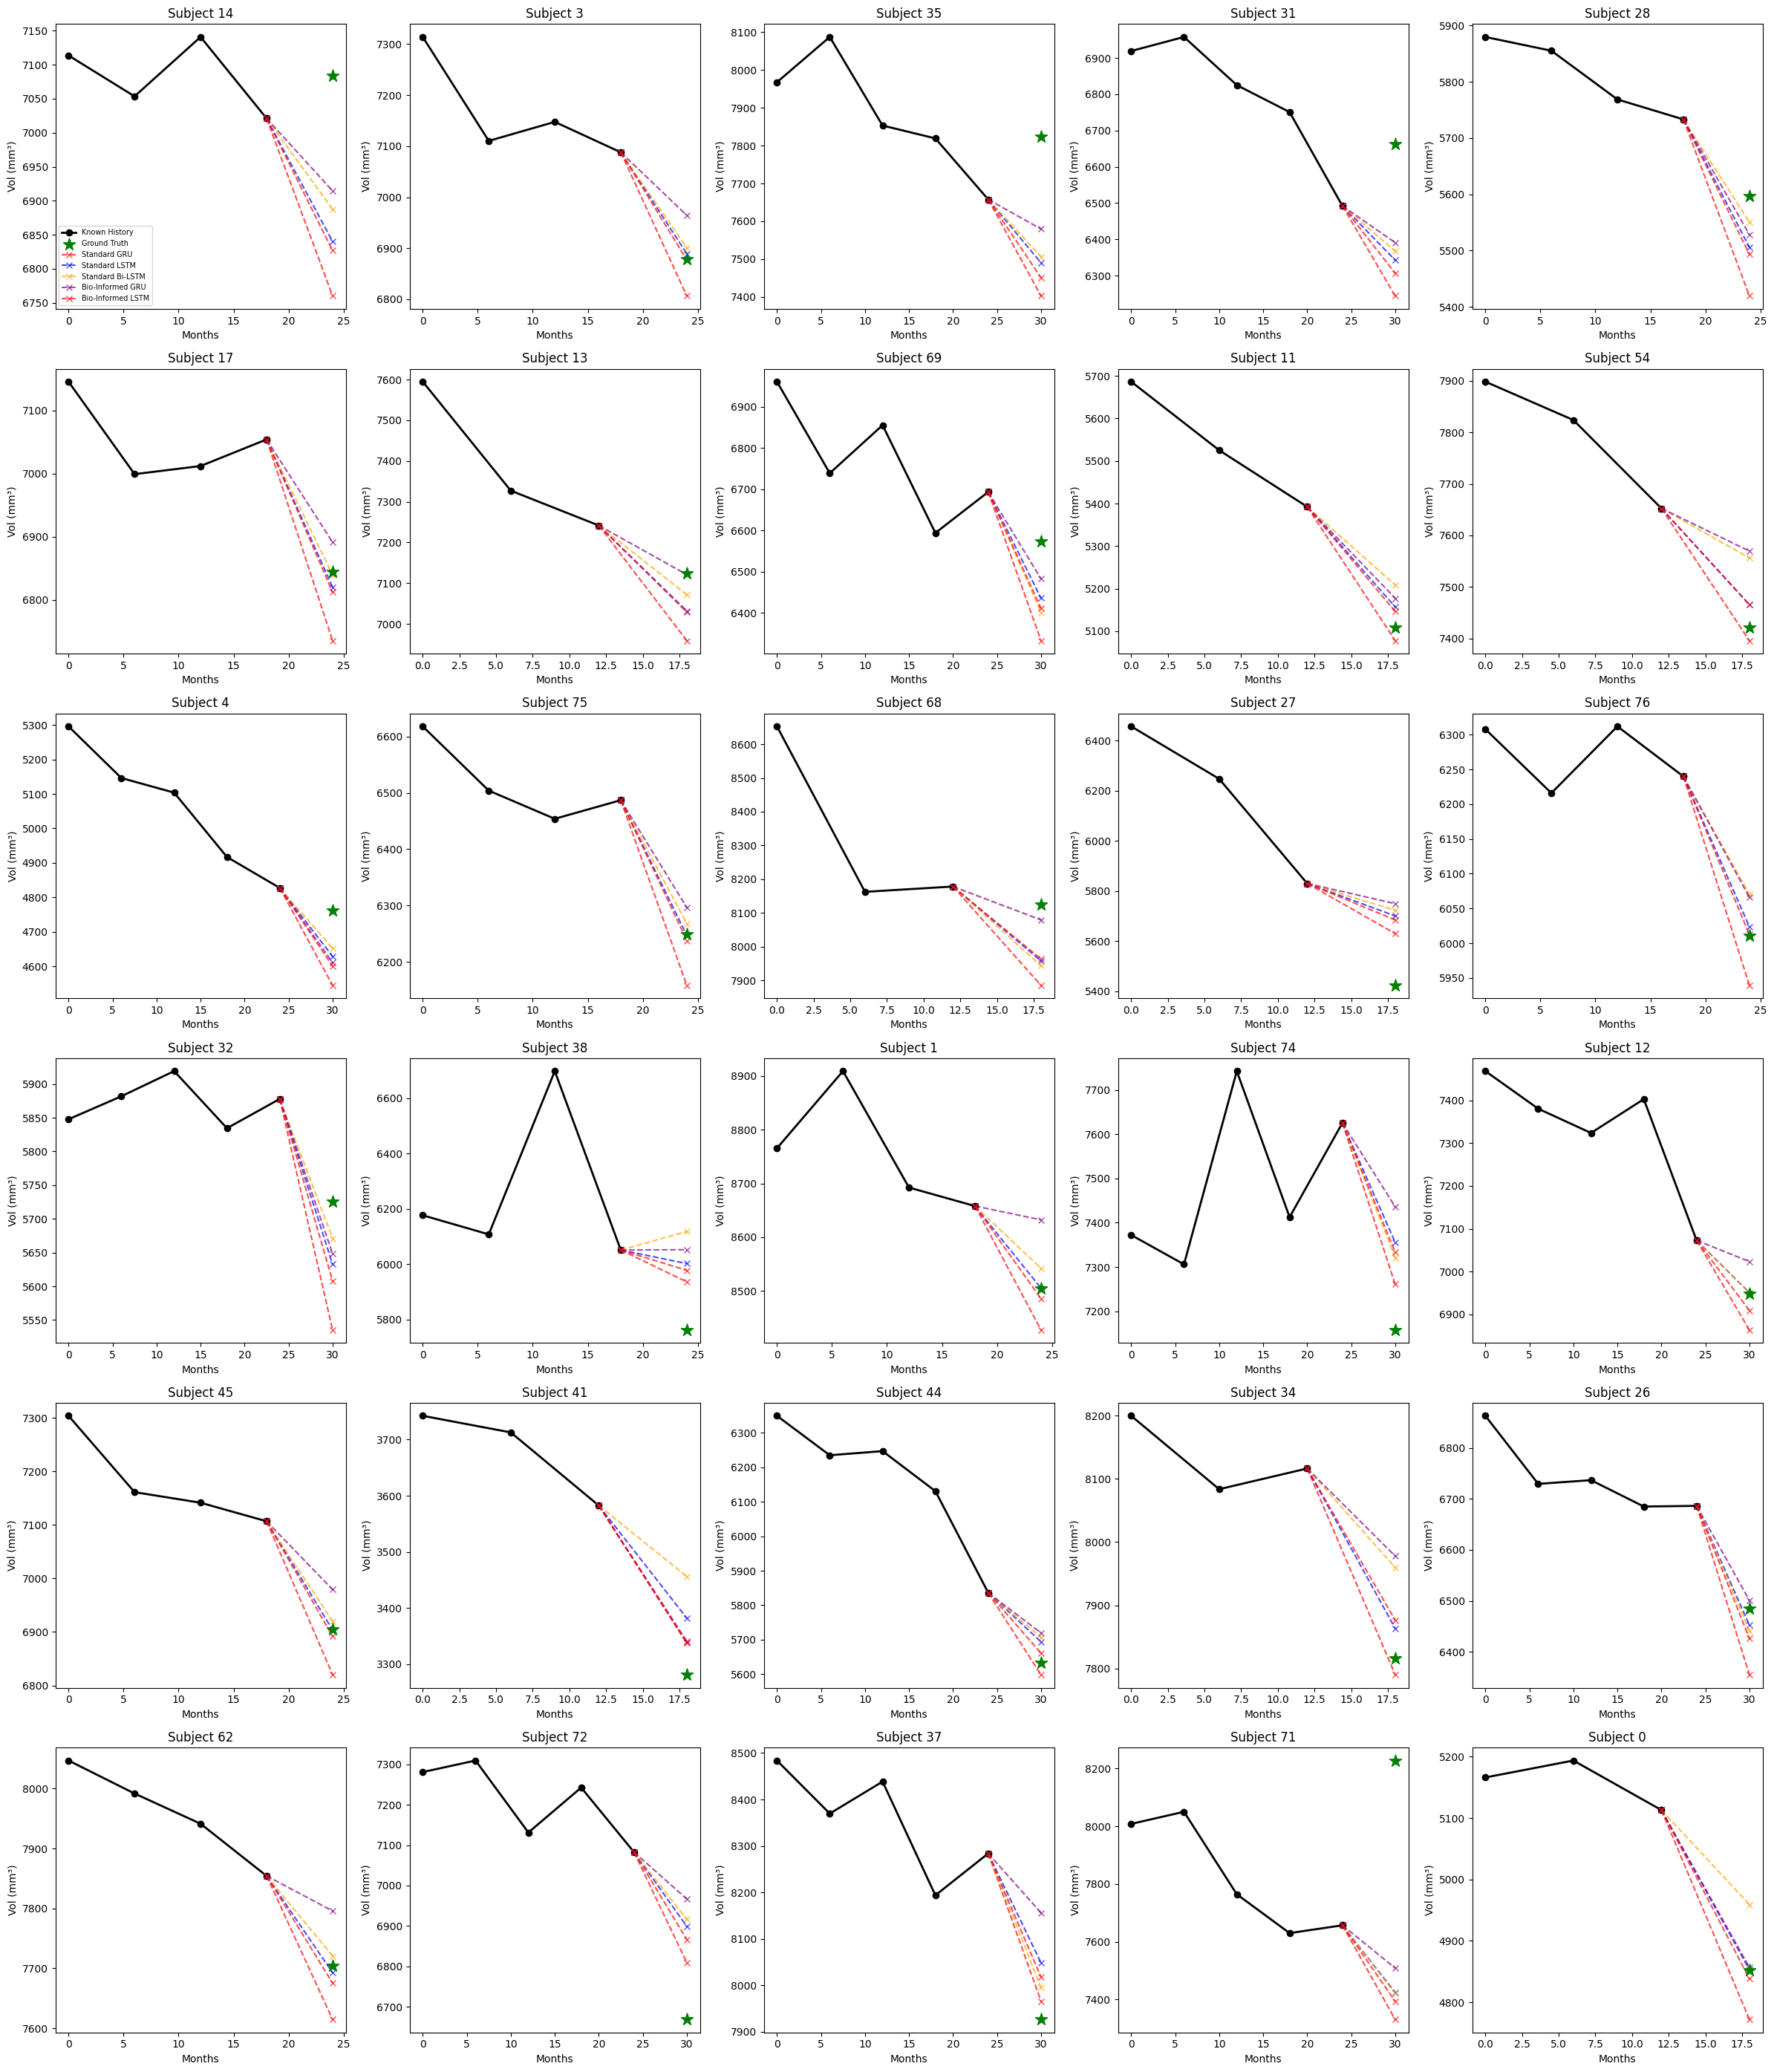

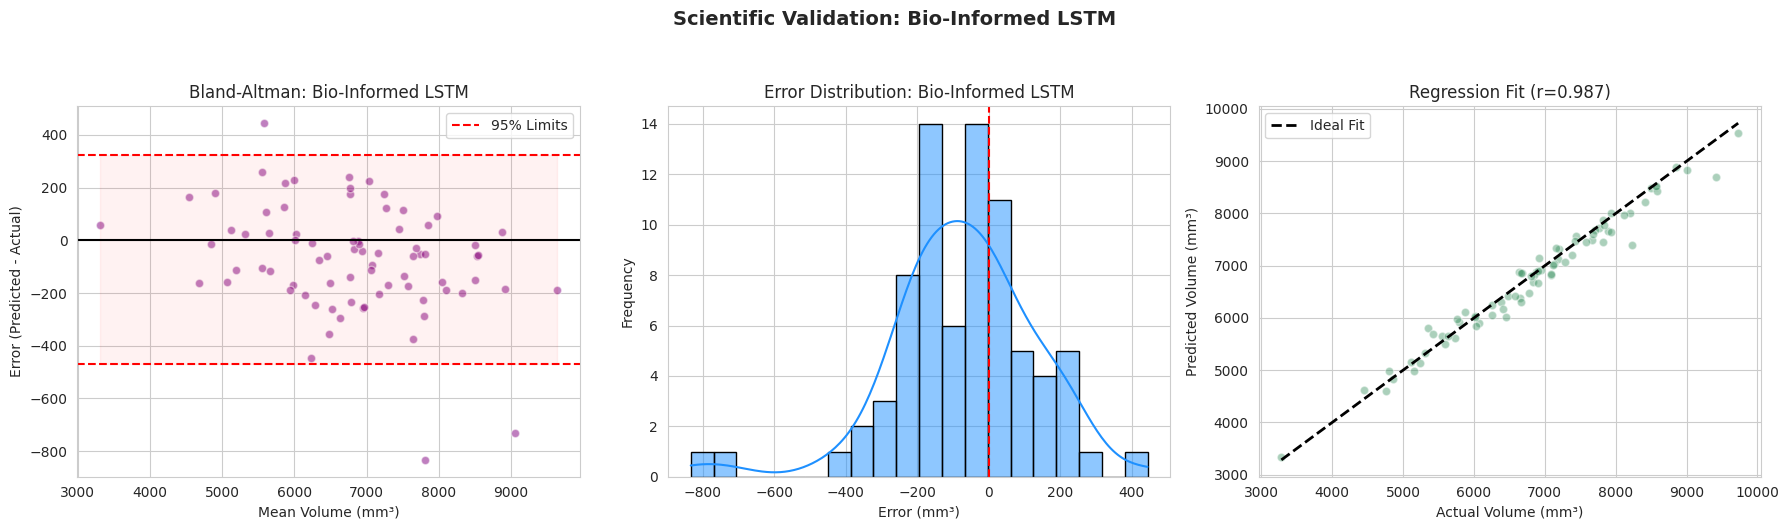

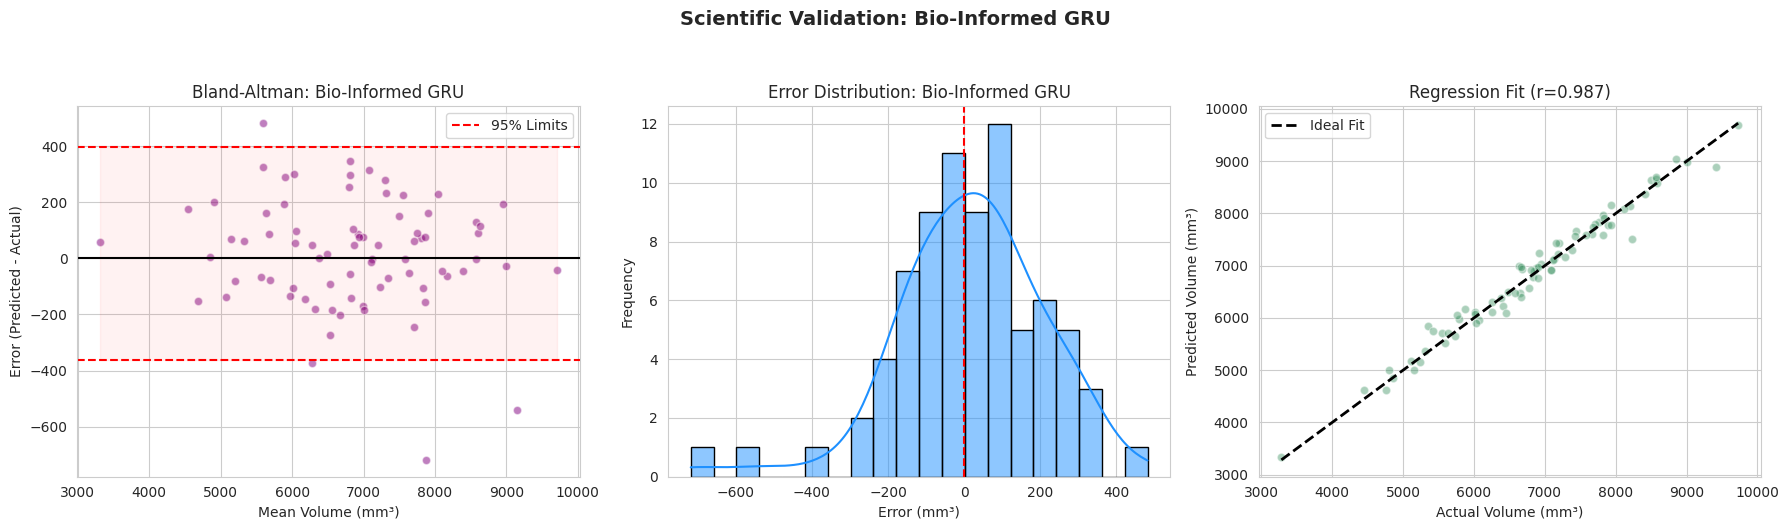

In [ ]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import cycle

import statsmodels.formula.api as smf
from statsmodels.tsa.arima.model import ARIMA
import xgboost as xgb # <-- ADDED IMPORT

# Suppress statistical warnings from ARIMA on short sequences
warnings.filterwarnings("ignore")

# === CONFIGURATION ===
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"
BATCH_SIZE = 1
EPOCHS = 100
BIO_WEIGHT = 2.0
TOLERANCE_PCT = 0.01
SEED = 42

# === 1. REPRODUCIBILITY SETUP ===
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"🌱 Random Seed set to {seed}")

set_seed(SEED)

# === 2. HELPER FUNCTIONS ===
def create_variable_sequences(df):
    sequences, targets, last_months = [], [], []
    df = df.sort_values(['SubjectID', 'Month'])

    for sub in df['SubjectID'].unique():
        sub_df = df[df['SubjectID'] == sub]
        vols = sub_df['Volume_mm3'].values
        months = sub_df['Month'].values

        if len(vols) >= 2:
            seq = vols[:-1]
            target = vols[-1]
            sequences.append(seq)
            targets.append(target)
            last_months.append(months[-1])

    return sequences, np.array(targets), np.array(last_months)

def calculate_metrics(preds, history_list, tolerance=0.01):
    last_known = np.array([h[0, -1] for h in history_list])
    growth_mm3 = preds - last_known
    pct_change = growth_mm3 / last_known

    violations = np.sum(pct_change > tolerance)
    violation_rate = (violations / len(preds)) * 100

    positive_growth = growth_mm3[growth_mm3 > 0]
    mpg = np.mean(positive_growth) if len(positive_growth) > 0 else 0.0

    return violation_rate, mpg

# === 3. DATASET & MODELS ===
class AtrophyDataset(Dataset):
    def __init__(self, sequences, targets):
        self.seqs = [torch.tensor(s, dtype=torch.float32).unsqueeze(-1) for s in sequences]
        self.targets = torch.tensor(targets, dtype=torch.float32)

    def __len__(self): return len(self.seqs)
    def __getitem__(self, idx): return self.seqs[idx], self.targets[idx]

class AtrophyLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(h_n.squeeze(0))

class AtrophyGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=64, num_layers=1, batch_first=True)
        self.fc = nn.Linear(64, 1)
    def forward(self, x):
        _, h_n = self.gru(x)
        return self.fc(h_n.squeeze(0))

class AtrophyBiLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=64, num_layers=1, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(128, 1)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        h_n = torch.cat((h_n[0], h_n[1]), dim=-1)
        return self.fc(h_n)

class BiologyInformedLoss(nn.Module):
    def __init__(self, lambda_bio=0.0, tolerance=0.01):
        super().__init__()
        self.mse = nn.MSELoss()
        self.lambda_bio = lambda_bio
        self.tolerance = tolerance

    def forward(self, predictions, targets, inputs):
        data_loss = self.mse(predictions, targets)
        last_known_vol = inputs[:, -1, :]
        allowed_growth = last_known_vol * self.tolerance
        excess_growth = (predictions - last_known_vol) - allowed_growth
        violation = torch.relu(excess_growth)
        bio_loss = torch.mean(violation ** 2)
        return data_loss + (self.lambda_bio * bio_loss)

# === 4. TRAINING ENGINE ===
def train_dl_model(model_class, train_loader, test_loader, scaler, lambda_val, label):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = BiologyInformedLoss(lambda_bio=lambda_val, tolerance=TOLERANCE_PCT)

    print(f"Training {label} (Lambda={lambda_val})...")

    loss_history = []

    for epoch in range(EPOCHS):
        model.train()
        epoch_loss = 0
        for seqs, targets in train_loader:
            seqs, targets = seqs.to(device), targets.to(device)
            optimizer.zero_grad()
            preds = model(seqs)
            loss = criterion(preds, targets, seqs)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        loss_history.append(epoch_loss / len(train_loader))

    model.eval()
    all_preds, all_actuals, all_histories = [], [], []

    with torch.no_grad():
        for seqs, targets in test_loader:
            seqs = seqs.to(device)
            pred_scaled = model(seqs).cpu().numpy()
            pred_mm3 = scaler.inverse_transform(pred_scaled)
            target_mm3 = scaler.inverse_transform(targets.numpy().reshape(-1,1))

            history_flat = seqs.cpu().numpy().reshape(-1, 1)
            history_mm3 = scaler.inverse_transform(history_flat).reshape(1, -1)

            all_preds.extend(pred_mm3.flatten())
            all_actuals.extend(target_mm3.flatten())
            all_histories.append(history_mm3)

    all_preds = np.array(all_preds)
    all_actuals = np.array(all_actuals)

    viol_rate, mpg = calculate_metrics(all_preds, all_histories, tolerance=TOLERANCE_PCT)
    mae = mean_absolute_error(all_actuals, all_preds)
    corr, _ = pearsonr(all_actuals, all_preds)

    return mae, corr, viol_rate, mpg, all_preds, all_actuals, all_histories, loss_history

# === 5. MASSIVE PLOTTING SUITE ===
def plot_training_curves(loss_dict):
    plt.figure(figsize=(10, 5))
    for name, history in loss_dict.items():
        plt.plot(history, label=name, linewidth=2)
    plt.title("Deep Learning Training Curves (Loss vs. Epochs)", fontweight='bold')
    plt.xlabel("Epochs")
    plt.ylabel("Loss (MSE + Bio-Penalty)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_barplots(results_df):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    metrics = [('MAE (Error)', 'lower'), ('CORRELATION', 'higher'),
               ('VIOLATION (%)', 'lower'), ('MPG (Severity)', 'lower')]

    for ax, (metric, better) in zip(axes.flatten(), metrics):
        sns.barplot(data=results_df, x='MODEL', y=metric, ax=ax, palette='viridis')
        ax.set_title(f"{metric} ({'Lower is Better' if better=='lower' else 'Higher is Better'})")
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

def plot_ablation_heatmap(results_df):
    heatmap_data = pd.DataFrame({
        'Standard': [
            results_df[results_df['MODEL']=='Standard LSTM']['MAE (Error)'].values[0],
            results_df[results_df['MODEL']=='Standard GRU']['MAE (Error)'].values[0]
        ],
        'Bio-Informed': [
            results_df[results_df['MODEL']=='Bio-Informed LSTM']['MAE (Error)'].values[0],
            results_df[results_df['MODEL']=='Bio-Informed GRU']['MAE (Error)'].values[0]
        ]
    }, index=['LSTM', 'GRU'])

    plt.figure(figsize=(6, 5))
    sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'MAE (mm³)'})
    plt.title("Ablation Study: Impact of Biology-Informed Loss", fontweight='bold')
    plt.show()

def plot_statistical_diagnostics(actuals, preds_dict, model_names):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colors = ['teal', 'coral']

    # 1. Residuals vs Predicted (Combined)
    for m, c in zip(model_names, colors):
        residuals = preds_dict[m] - actuals
        axes[0].scatter(preds_dict[m], residuals, alpha=0.5, color=c, label=m)
    axes[0].axhline(0, color='black', linestyle='--')
    axes[0].set_title("Residuals Plot Comparison")
    axes[0].set_xlabel("Predicted Volume (mm³)")
    axes[0].set_ylabel("Residuals")
    axes[0].legend()

    # 2. QQ Plot (Combined)
    for m, c in zip(model_names, colors):
        residuals = preds_dict[m] - actuals
        (osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist="norm")
        axes[1].scatter(osm, osr, alpha=0.4, color=c, label=m)
        axes[1].plot(osm, slope*osm + intercept, color=c, linestyle='--')
    axes[1].set_title("Q-Q Plot Comparison")
    axes[1].set_xlabel("Theoretical Quantiles")
    axes[1].set_ylabel("Ordered Values")
    axes[1].legend()

    # 3. Boxplot of Errors (Combined)
    data = []
    for m in model_names:
        abs_res = np.abs(preds_dict[m] - actuals)
        for val in abs_res:
            data.append({'Model': m, 'Absolute Error (mm³)': val})
    df_res = pd.DataFrame(data)
    sns.boxplot(x='Model', y='Absolute Error (mm³)', data=df_res, ax=axes[2], palette=colors)
    axes[2].set_title("Absolute Error Distribution")

    plt.tight_layout()
    plt.show()

def plot_trajectory_examples(actuals, preds_dict, histories, num_subjects=30):
    # Ensure we don't try to plot more subjects than we actually have
    num_subjects = min(num_subjects, len(actuals))

    # 6 rows, 5 columns grid for 30 subjects
    fig, axes = plt.subplots(6, 5, figsize=(24, 28))
    indices = random.sample(range(len(actuals)), num_subjects)

    for i, (ax, idx) in enumerate(zip(axes.flatten(), indices)):
        history = histories[idx][0]
        time_x = [step*6 for step in range(len(history))]
        next_time = time_x[-1] + 6

        ax.plot(time_x, history, 'o-', color='black', label='Known History', linewidth=2)
        ax.scatter([next_time], [actuals[idx]], color='green', marker='*', s=150, label='Ground Truth', zorder=5)

        colors = cycle(['red', 'blue', 'orange', 'purple'])
        for model_name, preds in preds_dict.items():
            if "Bio" in model_name or "Standard" in model_name:
                ax.plot([time_x[-1], next_time], [history[-1], preds[idx]], 'x--', color=next(colors), label=model_name, alpha=0.7)

        ax.set_title(f"Subject {idx}")
        ax.set_xlabel("Months")
        ax.set_ylabel("Vol (mm³)")

        # Only put legend on the very first plot to save space
        if i == 0:
            ax.legend(fontsize='x-small', loc='best')

    plt.tight_layout()
    plt.show()

def generate_thesis_plots(actuals, preds, model_name):
    errors = preds - actuals
    means = (preds + actuals) / 2

    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- Plot 1: Bland-Altman ---
    axes[0].scatter(means, errors, alpha=0.5, color='purple', edgecolor='w')
    axes[0].axhline(0, color='black', linestyle='-', linewidth=1.5)

    mean_error = np.mean(errors)
    std_error = np.std(errors)
    upper_loa = mean_error + 1.96 * std_error
    lower_loa = mean_error - 1.96 * std_error

    axes[0].axhline(upper_loa, color='red', linestyle='--', label='95% Limits')
    axes[0].axhline(lower_loa, color='red', linestyle='--')
    axes[0].fill_between([min(means), max(means)], lower_loa, upper_loa, color='red', alpha=0.05)

    axes[0].set_title(f"Bland-Altman: {model_name}")
    axes[0].set_xlabel("Mean Volume (mm³)")
    axes[0].set_ylabel("Error (Predicted - Actual)")
    axes[0].legend()

    # --- Plot 2: Error Histogram ---
    sns.histplot(errors, kde=True, ax=axes[1], color='dodgerblue', bins=20, edgecolor='black')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title(f"Error Distribution: {model_name}")
    axes[1].set_xlabel("Error (mm³)")
    axes[1].set_ylabel("Frequency")

    # --- Plot 3: Regression Fit ---
    axes[2].scatter(actuals, preds, alpha=0.4, color='seagreen', edgecolor='w')
    min_val, max_val = min(actuals), max(actuals)
    axes[2].plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal Fit', linewidth=2)

    axes[2].set_title(f"Regression Fit (r={np.corrcoef(actuals, preds)[0,1]:.3f})")
    axes[2].set_xlabel("Actual Volume (mm³)")
    axes[2].set_ylabel("Predicted Volume (mm³)")
    axes[2].legend()

    plt.suptitle(f"Scientific Validation: {model_name}", fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()


# === 6. MAIN EXPERIMENT PIPELINE ===
def run_full_comparison():
    if not os.path.exists(VOL_CSV):
        print(f"❌ Error: CSV not found at {VOL_CSV}")
        return

    # --- A. Data Prep ---
    df = pd.read_csv(VOL_CSV)
    visit_map = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48, 'm60':60}
    df['Month'] = df['Visit'].map(visit_map)
    df = df.dropna(subset=['Month'])

    unique_subs = df['SubjectID'].unique()
    split = int(0.8 * len(unique_subs))
    train_subs, test_subs = unique_subs[:split], unique_subs[split:]

    train_df = df[df['SubjectID'].isin(train_subs)]
    test_df = df[df['SubjectID'].isin(test_subs)]

    X_train, y_train, train_months = create_variable_sequences(train_df)
    X_test, y_test, test_months = create_variable_sequences(test_df)

    # Scale Data
    all_train_values = np.concatenate(X_train).reshape(-1, 1)
    scaler = MinMaxScaler()
    scaler.fit(all_train_values)

    X_train_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_train]
    X_test_s = [scaler.transform(s.reshape(-1,1)).reshape(-1) for s in X_test]
    y_train_s = scaler.transform(y_train.reshape(-1,1))
    y_test_s = scaler.transform(y_test.reshape(-1,1))

    train_loader = DataLoader(AtrophyDataset(X_train_s, y_train_s), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(AtrophyDataset(X_test_s, y_test_s), batch_size=1, shuffle=False)

    results = {}
    preds_dict = {}
    dl_loss_curves = {}

    shared_histories = [h.reshape(1, -1) for h in X_test]
    shared_actuals = y_test

    # ==========================================
    # CLASSICAL STATISTICAL MODELS
    # ==========================================
    print("\n--- Running Statistical Baselines ---")

    # 1. LOCF
    locf_preds = np.array([h[0, -1] for h in shared_histories])
    results["LOCF"] = [mean_absolute_error(shared_actuals, locf_preds), pearsonr(shared_actuals, locf_preds)[0],
                       *calculate_metrics(locf_preds, shared_histories, TOLERANCE_PCT)]
    preds_dict["LOCF"] = locf_preds

    # 2. Linear Regression
    lr_model = LinearRegression()
    flat_train_x = train_df[['Month']].values
    flat_train_y = train_df['Volume_mm3'].values
    lr_model.fit(flat_train_x, flat_train_y)
    lr_preds = lr_model.predict(test_months.reshape(-1, 1))

    results["Linear Regression"] = [mean_absolute_error(shared_actuals, lr_preds), pearsonr(shared_actuals, lr_preds)[0],
                                    *calculate_metrics(lr_preds, shared_histories, TOLERANCE_PCT)]
    preds_dict["Linear Regression"] = lr_preds

    # 3. LME
    try:
        lme_model = smf.mixedlm("Volume_mm3 ~ Month", train_df, groups=train_df["SubjectID"])
        lme_fit = lme_model.fit()
        lme_preds = lme_fit.predict(pd.DataFrame({'Month': test_months}))
        results["LME"] = [mean_absolute_error(shared_actuals, lme_preds), pearsonr(shared_actuals, lme_preds)[0],
                          *calculate_metrics(lme_preds, shared_histories, TOLERANCE_PCT)]
        preds_dict["LME"] = lme_preds.values
    except Exception as e:
        print("LME Failed:", e)

    # 4. ARIMA
    arima_preds = []
    for hist in shared_histories:
        try:
            model = ARIMA(hist[0], order=(1,1,0))
            fit_model = model.fit()
            arima_preds.append(fit_model.forecast(steps=1)[0])
        except:
            arima_preds.append(hist[0, -1])

    arima_preds = np.array(arima_preds)
    results["ARIMA"] = [mean_absolute_error(shared_actuals, arima_preds), pearsonr(shared_actuals, arima_preds)[0],
                        *calculate_metrics(arima_preds, shared_histories, TOLERANCE_PCT)]
    preds_dict["ARIMA"] = arima_preds

    # 5. XGBoost  <-- ADDED SECTION
    X_train_tab = np.array([[h[-1], len(h)] for h in X_train])
    X_test_tab = np.array([[h[-1], len(h)] for h in X_test])

    xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=50, max_depth=3, random_state=SEED)
    xgb_model.fit(X_train_tab, y_train)
    xgb_preds = xgb_model.predict(X_test_tab)

    results["XGBoost"] = [mean_absolute_error(shared_actuals, xgb_preds), pearsonr(shared_actuals, xgb_preds)[0],
                          *calculate_metrics(xgb_preds, shared_histories, TOLERANCE_PCT)]
    preds_dict["XGBoost"] = xgb_preds

    # ==========================================
    # DEEP LEARNING MODELS
    # ==========================================
    print("\n--- Running Deep Learning Models ---")

    dl_configs = [
        (AtrophyGRU, 0.0, "Standard GRU"),
        (AtrophyLSTM, 0.0, "Standard LSTM"),
        (AtrophyBiLSTM, 0.0, "Standard Bi-LSTM"),
        (AtrophyGRU, BIO_WEIGHT, "Bio-Informed GRU"),
        (AtrophyLSTM, BIO_WEIGHT, "Bio-Informed LSTM")
    ]

    for model_cls, weight, name in dl_configs:
        mae, corr, viol, mpg, p, a, h, loss_curve = train_dl_model(model_cls, train_loader, test_loader, scaler, weight, name)
        results[name] = [mae, corr, viol, mpg]
        preds_dict[name] = p
        dl_loss_curves[name] = loss_curve

    # ==========================================
    # OUTPUTS & PLOTS
    # ==========================================
    results_df = pd.DataFrame.from_dict(results, orient='index', columns=['MAE (Error)', 'CORRELATION', 'VIOLATION (%)', 'MPG (Severity)'])
    results_df.reset_index(inplace=True)
    results_df.rename(columns={'index': 'MODEL'}, inplace=True)

    print("\n" + "="*95)
    print(f"{'MODEL':<22} | {'MAE (Error)':<12} | {'CORRELATION':<12} | {'VIOLATION (%)':<15} | {'MPG (Severity)':<15}")
    print("-" * 95)

    # <-- ADDED XGBoost to order list
    order = ["LOCF", "Linear Regression", "LME", "ARIMA", "XGBoost", "Standard GRU", "Standard LSTM", "Standard Bi-LSTM", "Bio-Informed GRU", "Bio-Informed LSTM"]
    for name in order:
        if name in results:
            m = results[name]
            print(f"{name:<22} | {m[0]:.2f} mm³    | {m[1]:.4f}       | {m[2]:.1f}%            | {m[3]:.2f} mm³")
    print("="*95)

    # Trigger Visualizations
    plot_barplots(results_df)
    plot_ablation_heatmap(results_df)
    plot_training_curves(dl_loss_curves)

    # Updated: Pass both Bio-Informed models to plot on the same diagnostic axes
    plot_statistical_diagnostics(shared_actuals, preds_dict, ["Bio-Informed LSTM", "Bio-Informed GRU"])

    # Updated: Generate 30 Trajectories
    plot_trajectory_examples(shared_actuals, preds_dict, shared_histories, num_subjects=30)

    # Updated: Standalone validation plots for both top models
    generate_thesis_plots(shared_actuals, preds_dict["Bio-Informed LSTM"], "Bio-Informed LSTM")
    generate_thesis_plots(shared_actuals, preds_dict["Bio-Informed GRU"], "Bio-Informed GRU")

if __name__ == "__main__":
    run_full_comparison()

# Final Classification Run


In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.utils.rnn as rnn_utils
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Resized, ToTensord
)
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from itertools import cycle
from matplotlib.ticker import MaxNLocator

# ==========================================
# 1. CONFIGURATION
# ==========================================
IMG_SIZE = (96, 96, 96)
MAX_SEQ_LENGTH = 6
BATCH_SIZE = 4
EPOCHS = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 2. DATASET CLASS
# ==========================================
class LongitudinalADNI(Dataset):
    def __init__(self, csv_file, root_dir, split='Train', transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.split = split
        df = pd.read_csv(csv_file)
        self.df = df[df['Split'] == split].copy()
        self.label_map = {'CN': 0, 'MCI': 1, 'AD': 2}
        self.visit_order = {
            'nc': 0, 'sc': 0, 'bl': 0, 'm06': 6, 'm12': 12, 'm18': 18,
            'm24': 24, 'm36': 36, 'm48': 48, 'm60': 60, 'm72': 72
        }
        self.grouped_data = {
            sub_id: group.sort_values(
                by='Visit',
                key=lambda col: col.map(lambda x: self.visit_order.get(str(x).lower(), 999))
            )
            for sub_id, group in self.df.groupby('SubjectID')
        }
        self.subjects = list(self.grouped_data.keys())

    def __len__(self): return len(self.subjects)
    def __getitem__(self, idx):
        sub_id = self.subjects[idx]
        sub_data = self.grouped_data[sub_id]
        images = []
        for _, row in sub_data.iterrows():
            img_path = os.path.join(self.root_dir, row['FilePath'])
            if not os.path.exists(img_path): continue
            try:
                data = self.transform({"image": img_path})
                images.append(data["image"])
            except: continue
            if len(images) >= MAX_SEQ_LENGTH: break

        if not images:
            # Returns an empty tensor if images are missing
            return (torch.zeros((MAX_SEQ_LENGTH, 1, *IMG_SIZE)), 0, 0, torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool))

        actual_length = len(images)
        seq_tensor = torch.stack(images)

        # Augmentation (Train only)
        if self.split == 'Train' and torch.rand(1).item() < 0.5:
            k = torch.randint(1, 4, (1,)).item()
            seq_tensor = torch.rot90(seq_tensor, k, dims=[3, 4])

        # Padding
        if actual_length < MAX_SEQ_LENGTH:
            padding = torch.zeros((MAX_SEQ_LENGTH - actual_length, *seq_tensor.shape[1:]))
            seq_tensor = torch.cat([seq_tensor, padding], dim=0)

        label = self.label_map.get(sub_data.iloc[actual_length-1]['Diagnosis'], 1)

        # Dummy mask to satisfy 4-item return
        dummy_mask = torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool)

        return seq_tensor, torch.tensor(label).long(), torch.tensor(actual_length).long(), dummy_mask

# Transforms
train_transforms = Compose([LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])])
val_transforms = Compose([LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])])

# ==========================================
# 3. MODEL DEFINITIONS
# ==========================================

# --- Backbone 1: Standard 3D CNN ---
class Shared3DCNN(nn.Module):
    def __init__(self):
        super(Shared3DCNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv3d(1, 16, 3, 1, 1), nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, 3, 1, 1), nn.BatchNorm3d(32), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(32, 64, 3, 1, 1), nn.BatchNorm3d(64), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(64, 128, 3, 1, 1), nn.BatchNorm3d(128), nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1))
        )
    def forward(self, x): return self.cnn(x)

# --- Backbone 2: 3D ResNet (Lightweight) ---
class ResidualBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock3D, self).__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class ResNet3D_Backbone(nn.Module):
    def __init__(self):
        super(ResNet3D_Backbone, self).__init__()
        self.in_channels = 16
        self.conv1 = nn.Conv3d(1, 16, 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(16)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool3d(2)

        self.layer1 = self._make_layer(16, 1)
        self.layer2 = self._make_layer(32, 2)
        self.layer3 = self._make_layer(64, 2)
        self.layer4 = self._make_layer(128, 2)

        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))

    def _make_layer(self, out_channels, stride):
        layers = [ResidualBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.avgpool(x)

# --- MODELS ---

class CNN_GRU_AD(nn.Module):
    def __init__(self, num_classes=3, rnn_hidden=128, rnn_layers=1):
        super(CNN_GRU_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.gru = nn.GRU(input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True)
        self.fc = nn.Linear(rnn_hidden, num_classes)

    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        c_in = x.view(batch_size * seq_len, C, D, H, W)
        features = self.backbone(c_in)
        features = features.view(batch_size, seq_len, -1)

        lengths_cpu = lengths.cpu()
        packed_input = rnn_utils.pack_padded_sequence(features, lengths_cpu, batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed_input)
        return self.fc(hn[-1])

class CNN_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3, rnn_hidden=128, rnn_layers=1):
        super(CNN_LSTM_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.lstm = nn.LSTM(input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True)
        self.fc = nn.Linear(rnn_hidden, num_classes)

    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        c_in = x.view(batch_size * seq_len, C, D, H, W)
        features = self.backbone(c_in)
        features = features.view(batch_size, seq_len, -1)

        lengths_cpu = lengths.cpu()
        packed_input = rnn_utils.pack_padded_sequence(features, lengths_cpu, batch_first=True, enforce_sorted=False)
        _, (hn, cn) = self.lstm(packed_input)
        return self.fc(hn[-1])

class ResNet_GRU_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(ResNet_GRU_AD, self).__init__()
        self.backbone = ResNet3D_Backbone()
        self.gru = nn.GRU(128, 32, batch_first=True)
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x, lengths):
        B, S, C, D, H, W = x.size()
        f = self.backbone(x.view(B*S, C, D, H, W)).view(B, S, -1)
        _, hn = self.gru(rnn_utils.pack_padded_sequence(f, lengths.cpu(), batch_first=True, enforce_sorted=False))
        return self.fc(hn[-1])

class ResNet_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(ResNet_LSTM_AD, self).__init__()
        self.backbone = ResNet3D_Backbone()
        self.lstm = nn.LSTM(128, 32, batch_first=True)
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x, lengths):
        B, S, C, D, H, W = x.size()
        f = self.backbone(x.view(B*S, C, D, H, W)).view(B, S, -1)
        _, (hn, _) = self.lstm(rnn_utils.pack_padded_sequence(f, lengths.cpu(), batch_first=True, enforce_sorted=False))
        return self.fc(hn[-1])

# ==========================================
# 4. TRAINING & EVALUATION FUNCTIONS
# ==========================================
def run_full_process(model_name, model, train_loader, val_loader, test_loader, class_weights):
    print(f"\n{'='*40}\n🚀 STARTING: {model_name}\n{'='*40}")

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)

    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    best_acc = 0.0

    # --- TRAIN ---
    for epoch in range(EPOCHS):
        model.train()
        r_loss, correct, total = 0.0, 0, 0
        for x, y, l, _ in train_loader:
            x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x, l)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            r_loss += loss.item()
            _, p = torch.max(out, 1)
            total += y.size(0); correct += (p==y).sum().item()

        t_acc = 100*correct/total
        t_loss = r_loss/len(train_loader)

        # Val
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y, l, _ in val_loader:
                x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
                out = model(x, l)
                v_loss += criterion(out, y).item()
                _, p = torch.max(out, 1)
                v_total += y.size(0); v_correct += (p==y).sum().item()

        v_acc = 100*v_correct/v_total
        v_loss /= len(val_loader)

        history['train_loss'].append(t_loss); history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc); history['val_acc'].append(v_acc)

        if v_acc > best_acc:
            best_acc = v_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
            print(f"Epoch {epoch+1}/{EPOCHS} | T-Loss: {t_loss:.3f} | V-Loss: {v_loss:.3f} | V-Acc: {v_acc:.1f}%  ⭐ Best Saved")
        else:
            print(f"Epoch {epoch+1}/{EPOCHS} | T-Loss: {t_loss:.3f} | V-Loss: {v_loss:.3f} | V-Acc: {v_acc:.1f}%")

    # --- PLOT CURVES ---
    plt.figure(figsize=(14, 5))
    ax1 = plt.subplot(1, 2, 1)
    ax1.plot(range(1, EPOCHS+1), history['train_loss'], label='Train')
    ax1.plot(range(1, EPOCHS+1), history['val_loss'], '--', label='Val')
    ax1.set_title(f"{model_name} Loss"); ax1.legend(); ax1.grid(True)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax2 = plt.subplot(1, 2, 2)
    ax2.plot(range(1, EPOCHS+1), history['train_acc'], label='Train')
    ax2.plot(range(1, EPOCHS+1), history['val_acc'], '--', label='Val')
    ax2.set_title(f"{model_name} Accuracy"); ax2.legend(); ax2.grid(True)
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

    # --- BACKUP ---
    drive_folder = "/content/drive/MyDrive/ADNI_dataset_classification"
    os.makedirs(drive_folder, exist_ok=True)
    try:
        shutil.copy(f"best_{model_name}.pth", f"{drive_folder}/best_{model_name}.pth")
        print("✅ Backed up to Drive")
    except: print("⚠️ Backup Failed")

    # --- TEST EVALUATION ---
    print(f"\nEvaluating {model_name} on Test Set...")
    model.load_state_dict(torch.load(f"best_{model_name}.pth", map_location=DEVICE))
    model.eval()

    preds, labels, probs = [], [], []
    with torch.no_grad():
        for x, y, l, _ in test_loader:
            x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
            out = model(x, l)
            _, p = torch.max(out, 1)
            preds.extend(p.cpu().numpy())
            labels.extend(y.cpu().numpy())
            probs.extend(torch.softmax(out, 1).cpu().numpy())

    # Metrics
    print(classification_report(labels, preds, target_names=['CN', 'MCI', 'AD']))

    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1)
    sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues', xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
    plt.title("Confusion Matrix")

    plt.subplot(1, 2, 2)
    y_bin = label_binarize(labels, classes=[0,1,2])
    fpr, tpr, roc_auc = dict(), dict(), dict()
    for i in range(3):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], np.array(probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=2, label=f'{["CN","MCI","AD"][i]} (AUC={roc_auc[i]:.2f})')
    plt.plot([0,1], [0,1], 'k--'); plt.legend(); plt.title("ROC Curve")
    plt.show()

# ==========================================
# 5. DATA LOADING SETUP
# ==========================================
CSV_PATH = "/content/final_dataset_split.csv"
if os.path.exists("/content/ADNI"): ROOT_DIR = "/content/ADNI"
else: ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset_classification/ADNI"

if os.path.exists(CSV_PATH):
    print("Loading Data...")
    train_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
    val_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)
    test_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    # Class Weights
    tgts = [train_ds.label_map.get(train_ds.grouped_data[s].iloc[-1]['Diagnosis'].upper(), 1) for s in train_ds.subjects]
    cw = compute_class_weight('balanced', classes=np.unique(tgts), y=tgts)
    class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)
    print(f"✅ Setup Complete. Weights: {class_weights}")
else:
    print("❌ Error: CSV not found.")

<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


Loading Data...
✅ Setup Complete. Weights: tensor([0.9889, 0.8476, 1.2361], device='cuda:0')



🚀 STARTING: Hybrid_CNN_GRU
Epoch 1/10 | T-Loss: 1.073 | V-Loss: 1.097 | V-Acc: 35.1%
Epoch 2/10 | T-Loss: 1.049 | V-Loss: 1.113 | V-Acc: 24.6%
Epoch 3/10 | T-Loss: 1.027 | V-Loss: 1.063 | V-Acc: 43.9%
Epoch 4/10 | T-Loss: 1.011 | V-Loss: 1.180 | V-Acc: 29.8%
Epoch 5/10 | T-Loss: 0.969 | V-Loss: 0.995 | V-Acc: 50.9%
Epoch 6/10 | T-Loss: 0.900 | V-Loss: 0.905 | V-Acc: 59.6%
Epoch 7/10 | T-Loss: 0.762 | V-Loss: 0.891 | V-Acc: 47.4%
Epoch 8/10 | T-Loss: 0.546 | V-Loss: 0.533 | V-Acc: 91.2%
Epoch 9/10 | T-Loss: 0.377 | V-Loss: 0.591 | V-Acc: 64.9%
Epoch 10/10 | T-Loss: 0.251 | V-Loss: 0.237 | V-Acc: 100.0%


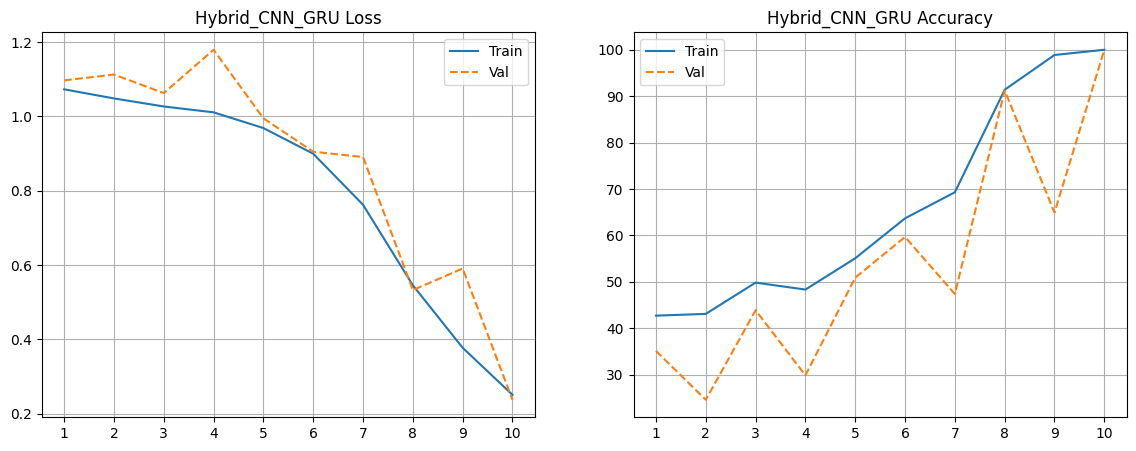

✅ Backed up to Drive

Evaluating Hybrid_CNN_GRU on Test Set...
              precision    recall  f1-score   support

          CN       1.00      1.00      1.00        17
         MCI       1.00      1.00      1.00        24
          AD       1.00      1.00      1.00        17

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58



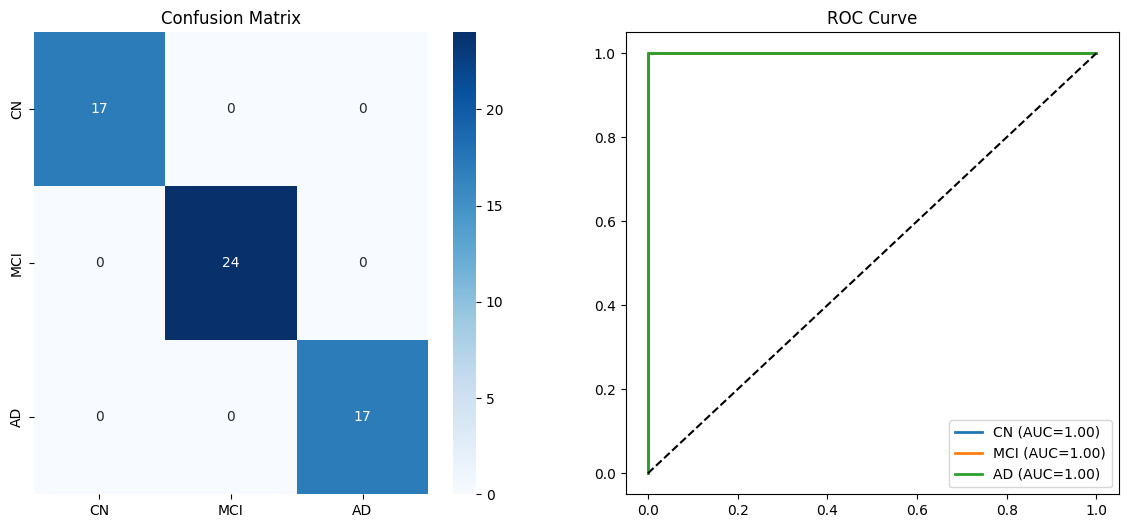

In [ ]:
# Block 1: Train 3D CNN + GRU
model = CNN_GRU_AD(num_classes=3).to(DEVICE)
run_full_process("Hybrid_CNN_GRU", model, train_loader, val_loader, test_loader, class_weights)


🚀 STARTING: Hybrid_CNN_LSTM
Epoch 1/10 | T-Loss: 1.094 | V-Loss: 1.096 | V-Acc: 33.3%
Epoch 2/10 | T-Loss: 1.069 | V-Loss: 1.095 | V-Acc: 29.8%
Epoch 3/10 | T-Loss: 1.048 | V-Loss: 1.104 | V-Acc: 26.3%
Epoch 4/10 | T-Loss: 1.012 | V-Loss: 1.049 | V-Acc: 36.8%
Epoch 5/10 | T-Loss: 0.919 | V-Loss: 1.146 | V-Acc: 33.3%
Epoch 6/10 | T-Loss: 0.745 | V-Loss: 1.279 | V-Acc: 28.1%
Epoch 7/10 | T-Loss: 0.532 | V-Loss: 0.543 | V-Acc: 96.5%
Epoch 8/10 | T-Loss: 0.380 | V-Loss: 0.348 | V-Acc: 100.0%
Epoch 9/10 | T-Loss: 0.264 | V-Loss: 0.399 | V-Acc: 96.5%
Epoch 10/10 | T-Loss: 0.187 | V-Loss: 0.422 | V-Acc: 89.5%


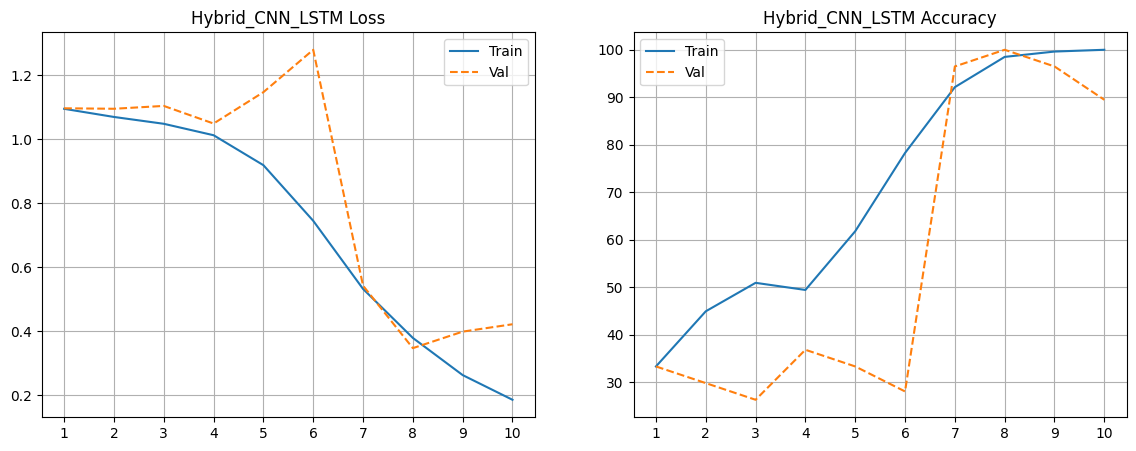

✅ Backed up to Drive

Evaluating Hybrid_CNN_LSTM on Test Set...
              precision    recall  f1-score   support

          CN       1.00      1.00      1.00        17
         MCI       1.00      1.00      1.00        24
          AD       1.00      1.00      1.00        17

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58



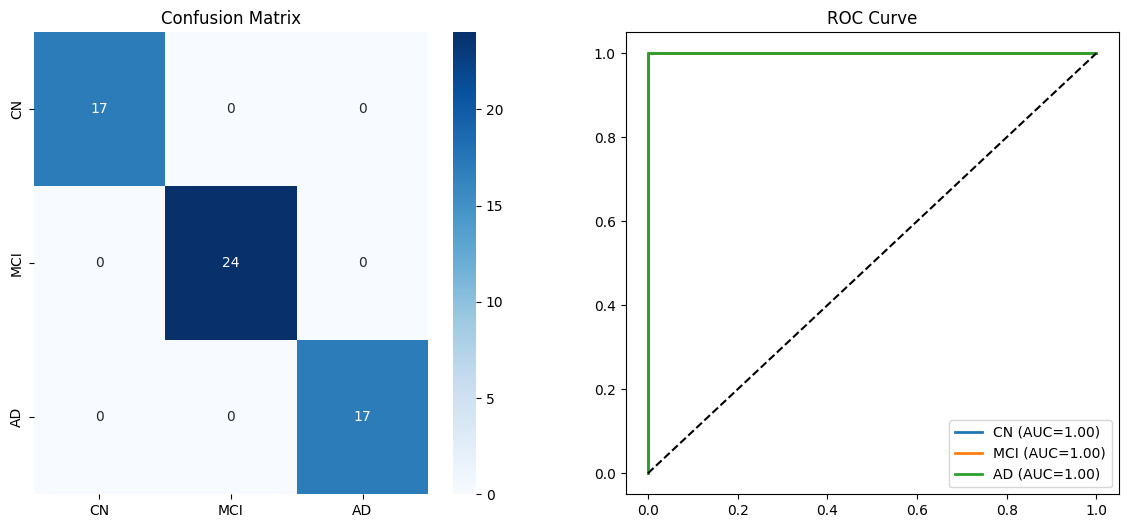

In [ ]:
# Block 2: Train 3D CNN + LSTM
model = CNN_LSTM_AD(num_classes=3).to(DEVICE)
run_full_process("Hybrid_CNN_LSTM", model, train_loader, val_loader, test_loader, class_weights)


🚀 STARTING: ResNet3D_GRU
Epoch 1/10 | T-Loss: 1.084 | V-Loss: 1.142 | V-Acc: 33.3%
Epoch 2/10 | T-Loss: 1.068 | V-Loss: 1.078 | V-Acc: 42.1%
Epoch 3/10 | T-Loss: 1.027 | V-Loss: 1.177 | V-Acc: 24.6%
Epoch 4/10 | T-Loss: 1.021 | V-Loss: 1.160 | V-Acc: 33.3%
Epoch 5/10 | T-Loss: 1.037 | V-Loss: 1.259 | V-Acc: 26.3%
Epoch 6/10 | T-Loss: 0.965 | V-Loss: 1.179 | V-Acc: 17.5%
Epoch 7/10 | T-Loss: 0.933 | V-Loss: 1.306 | V-Acc: 35.1%
Epoch 8/10 | T-Loss: 0.872 | V-Loss: 1.072 | V-Acc: 45.6%
Epoch 9/10 | T-Loss: 0.799 | V-Loss: 1.293 | V-Acc: 17.5%
Epoch 10/10 | T-Loss: 0.723 | V-Loss: 1.063 | V-Acc: 45.6%


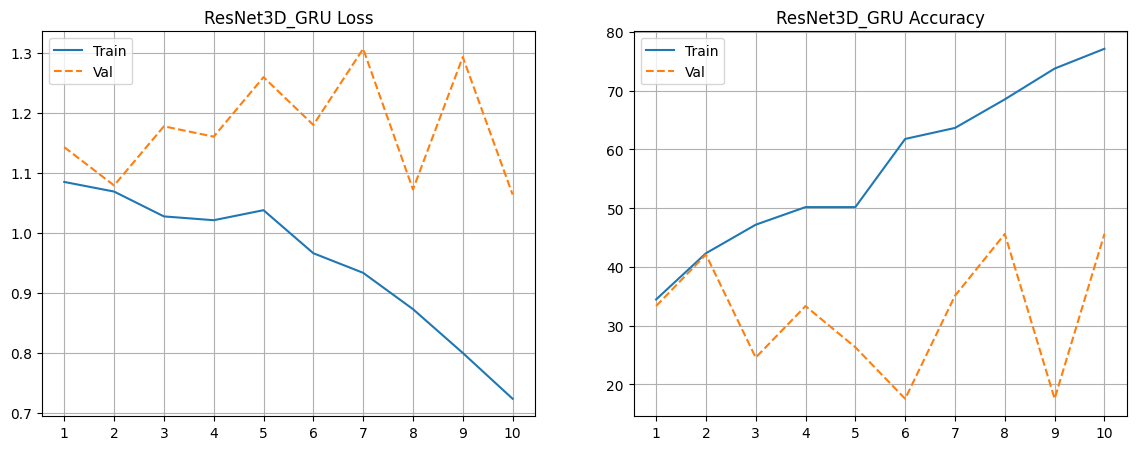

✅ Backed up to Drive

Evaluating ResNet3D_GRU on Test Set...
              precision    recall  f1-score   support

          CN       0.25      0.82      0.39        17
         MCI       0.00      0.00      0.00        24
          AD       0.00      0.00      0.00        17

    accuracy                           0.24        58
   macro avg       0.08      0.27      0.13        58
weighted avg       0.07      0.24      0.11        58



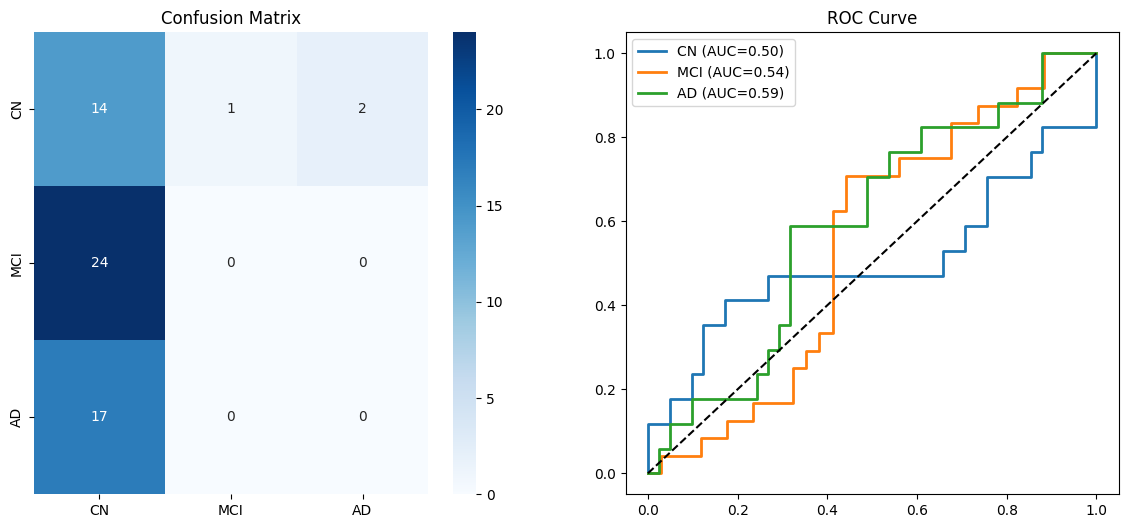

In [ ]:
# Block 3: Train 3D ResNet + GRU
model = ResNet_GRU_AD(num_classes=3).to(DEVICE)
run_full_process("ResNet3D_GRU", model, train_loader, val_loader, test_loader, class_weights)


🚀 STARTING: ResNet3D_LSTM
Epoch 1/10 | T-Loss: 1.075 | V-Loss: 1.111 | V-Acc: 33.3%
Epoch 2/10 | T-Loss: 1.057 | V-Loss: 1.176 | V-Acc: 28.1%
Epoch 3/10 | T-Loss: 1.028 | V-Loss: 1.081 | V-Acc: 33.3%
Epoch 4/10 | T-Loss: 0.979 | V-Loss: 1.058 | V-Acc: 33.3%
Epoch 5/10 | T-Loss: 0.939 | V-Loss: 1.103 | V-Acc: 31.6%
Epoch 6/10 | T-Loss: 0.935 | V-Loss: 1.357 | V-Acc: 26.3%
Epoch 7/10 | T-Loss: 0.852 | V-Loss: 1.059 | V-Acc: 36.8%
Epoch 8/10 | T-Loss: 0.841 | V-Loss: 1.494 | V-Acc: 22.8%
Epoch 9/10 | T-Loss: 0.823 | V-Loss: 0.975 | V-Acc: 42.1%
Epoch 10/10 | T-Loss: 0.760 | V-Loss: 1.478 | V-Acc: 24.6%


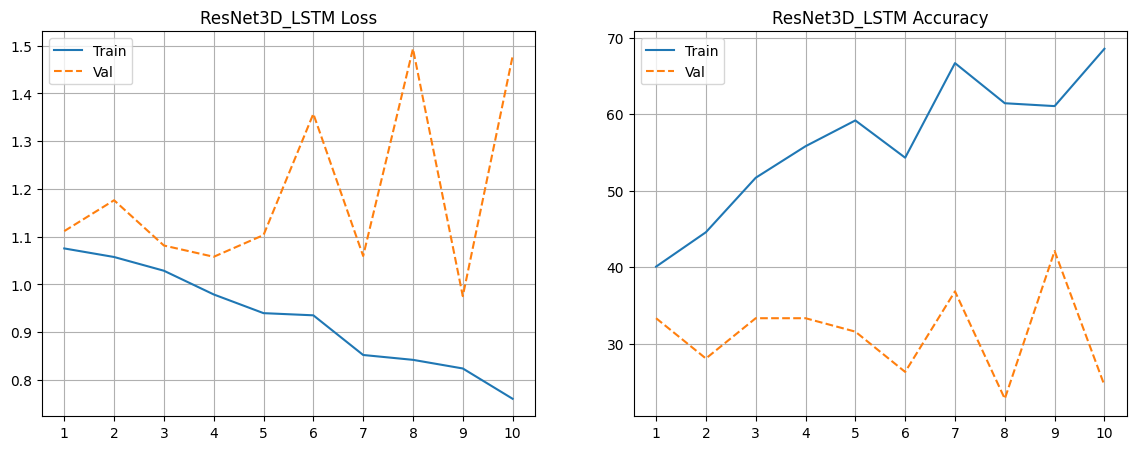

✅ Backed up to Drive

Evaluating ResNet3D_LSTM on Test Set...
              precision    recall  f1-score   support

          CN       0.30      0.35      0.32        17
         MCI       0.53      0.79      0.63        24
          AD       0.50      0.06      0.11        17

    accuracy                           0.45        58
   macro avg       0.44      0.40      0.35        58
weighted avg       0.45      0.45      0.39        58



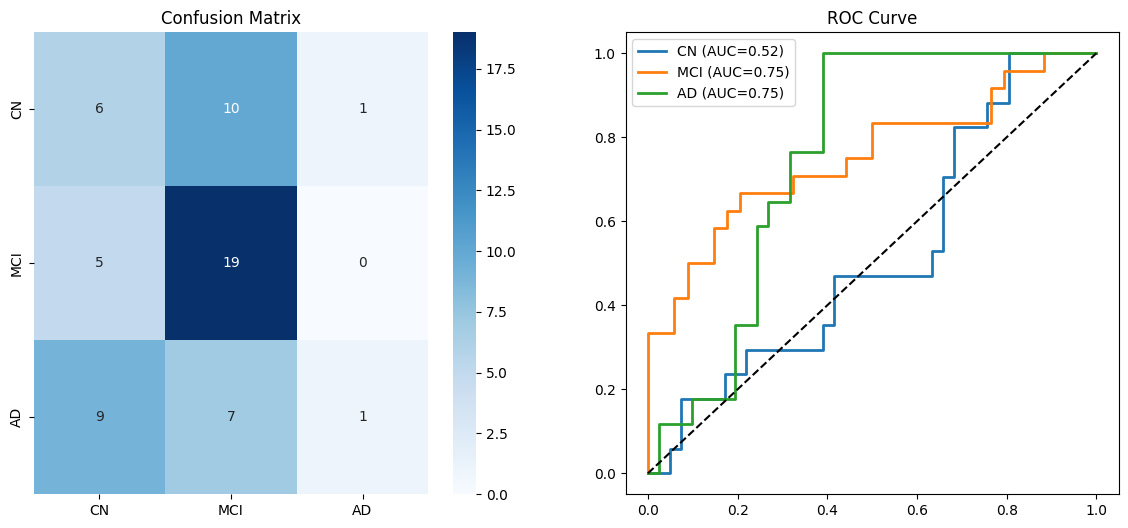

In [ ]:
# Block 4: Train 3D ResNet + LSTM
model = ResNet_LSTM_AD(num_classes=3).to(DEVICE)
run_full_process("ResNet3D_LSTM", model, train_loader, val_loader, test_loader, class_weights)


🏆 STARTING MASTER THESIS EVALUATION

Loading and Evaluating: Hybrid_CNN_GRU...


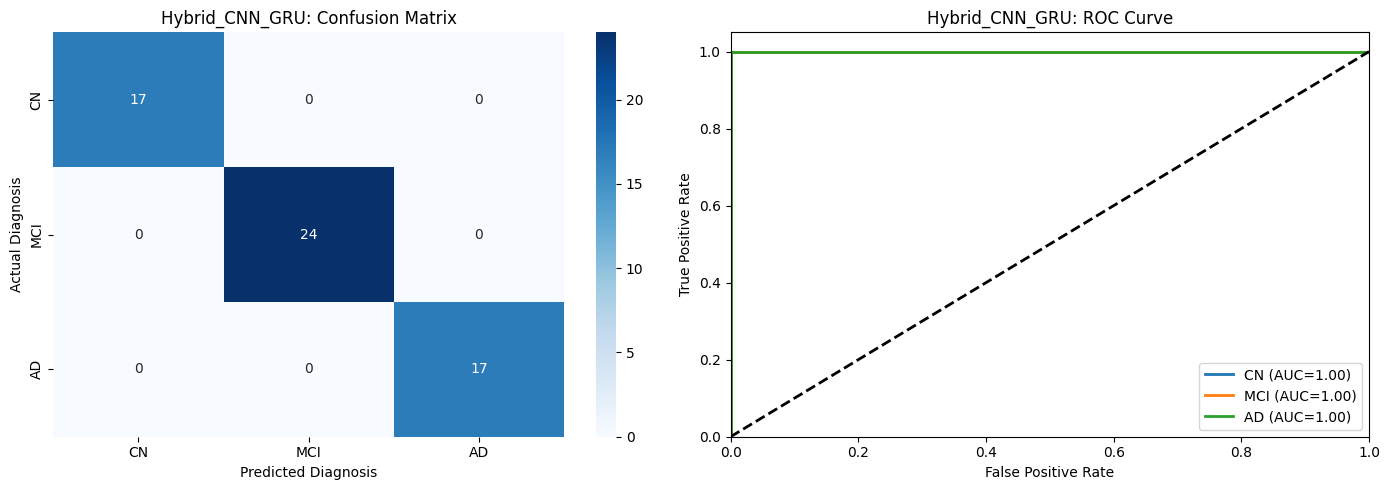


Loading and Evaluating: Hybrid_CNN_LSTM...


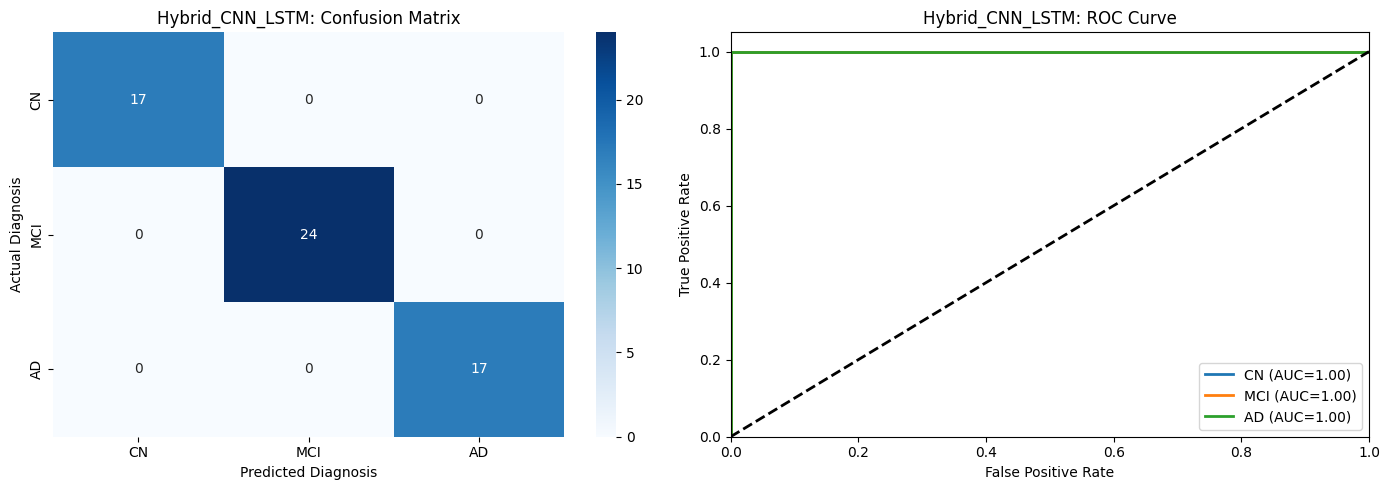


Loading and Evaluating: ResNet3D_GRU...


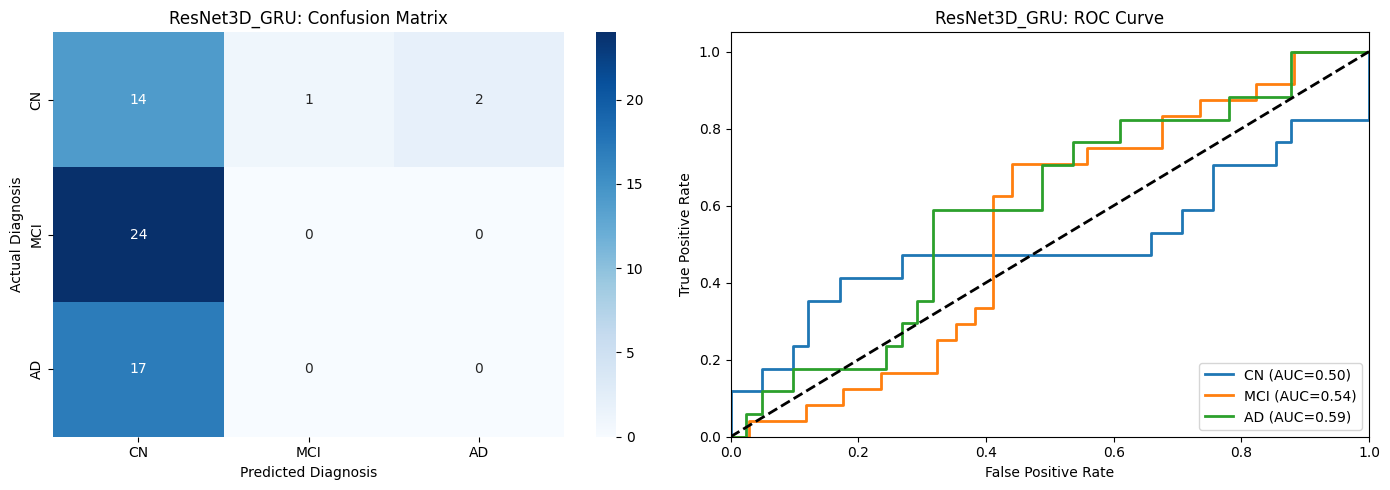


Loading and Evaluating: ResNet3D_LSTM...


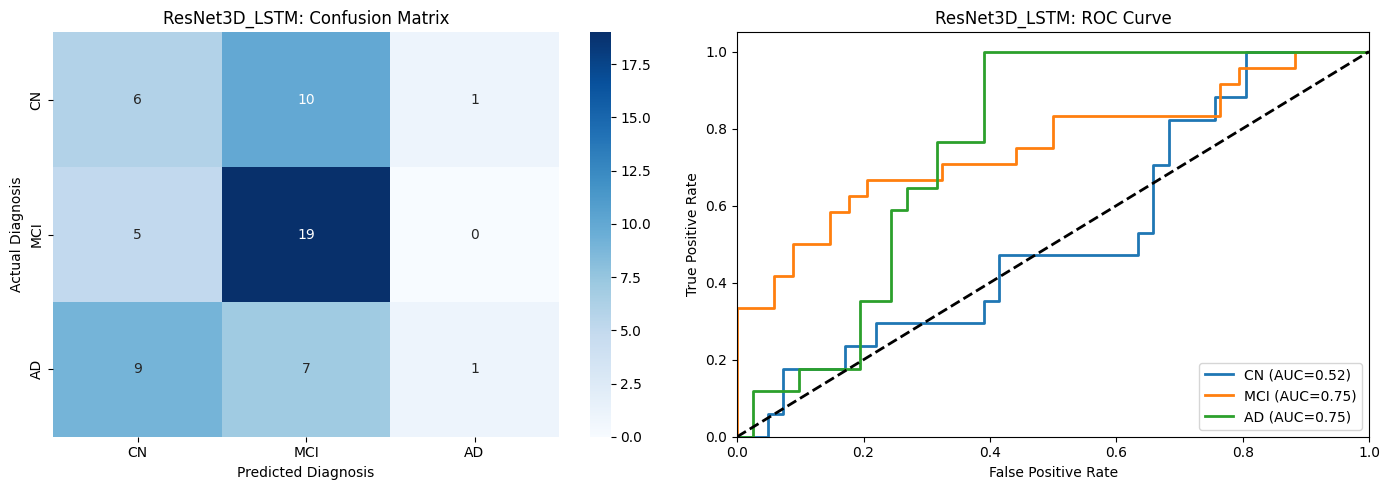


📊 FINAL THESIS COMPARISON TABLE
                 Accuracy  Macro Precision  Macro Recall  Macro F1-Score  AD Recall (Sensitivity)
Model                                                                                            
Hybrid_CNN_GRU     1.0000           1.0000        1.0000          1.0000                   1.0000
Hybrid_CNN_LSTM    1.0000           1.0000        1.0000          1.0000                   1.0000
ResNet3D_GRU       0.2414           0.0848        0.2745          0.1296                   0.0000
ResNet3D_LSTM      0.4483           0.4426        0.4011          0.3543                   0.0588

✅ Saved this table to: /content/drive/MyDrive/ADNI_dataset_classification/Final_Model_Comparison.csv


In [ ]:
# ==========================================
# BLOCK 6: MASTER EVALUATION & COMPARISON
# ==========================================
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

def run_master_evaluation():
    print(f"\n{'='*50}\n🏆 STARTING MASTER THESIS EVALUATION\n{'='*50}")

    # 1. Define the models and where their brains are saved
    drive_folder = "/content/drive/MyDrive/ADNI_dataset_classification"

    models_to_test = {
        "Hybrid_CNN_GRU": CNN_GRU_AD,
        "Hybrid_CNN_LSTM": CNN_LSTM_AD,
        "ResNet3D_GRU": ResNet_GRU_AD,
        "ResNet3D_LSTM": ResNet_LSTM_AD
    }

    master_results = []

    # 2. Loop through each model
    for model_name, model_class in models_to_test.items():
        pth_path = os.path.join(drive_folder, f"best_{model_name}.pth")

        # Check if the model actually exists (in case you skipped training one)
        if not os.path.exists(pth_path):
            print(f"\n⚠️ Skipping {model_name}: Could not find {pth_path}")
            continue

        print(f"\nLoading and Evaluating: {model_name}...")

        # Initialize and load weights
        model = model_class(num_classes=3).to(DEVICE)
        model.load_state_dict(torch.load(pth_path, map_location=DEVICE))
        model.eval()

        preds, labels, probs = [], [], []

        # 3. Run Inference
        with torch.no_grad():
            for x, y, l, _ in test_loader:
                x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
                out = model(x, l)

                _, p = torch.max(out, 1)
                preds.extend(p.cpu().numpy())
                labels.extend(y.cpu().numpy())
                probs.extend(torch.softmax(out, 1).cpu().numpy())

        # 4. Extract Metrics for the Master Table
        # output_dict=True lets us extract the exact numbers easily
        report_dict = classification_report(labels, preds, target_names=['CN', 'MCI', 'AD'], output_dict=True, zero_division=0)

        master_results.append({
            "Model": model_name,
            "Accuracy": round(report_dict['accuracy'], 4),
            "Macro Precision": round(report_dict['macro avg']['precision'], 4),
            "Macro Recall": round(report_dict['macro avg']['recall'], 4),
            "Macro F1-Score": round(report_dict['macro avg']['f1-score'], 4),
            "AD Recall (Sensitivity)": round(report_dict['AD']['recall'], 4) # Crucial for medical thesis!
        })

        # 5. Plotting Confusion Matrix & ROC for this model
        plt.figure(figsize=(14, 5))

        # --- Confusion Matrix ---
        plt.subplot(1, 2, 1)
        sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues',
                    xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
        plt.title(f"{model_name}: Confusion Matrix")
        plt.ylabel('Actual Diagnosis')
        plt.xlabel('Predicted Diagnosis')

        # --- ROC Curve ---
        plt.subplot(1, 2, 2)
        y_bin = label_binarize(labels, classes=[0,1,2])
        fpr, tpr, roc_auc = dict(), dict(), dict()
        for i in range(3):
            fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], np.array(probs)[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            plt.plot(fpr[i], tpr[i], lw=2, label=f'{["CN","MCI","AD"][i]} (AUC={roc_auc[i]:.2f})')

        plt.plot([0,1], [0,1], 'k--', lw=2)
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f"{model_name}: ROC Curve")
        plt.legend(loc="lower right")

        plt.tight_layout()
        plt.show()

    # 6. Generate the Final Master Table
    print(f"\n{'='*50}\n📊 FINAL THESIS COMPARISON TABLE\n{'='*50}")
    if master_results:
        results_df = pd.DataFrame(master_results)
        # Set the Model column as the index so it prints beautifully
        results_df.set_index("Model", inplace=True)
        print(results_df.to_string())

        # Optional: Save this table to a CSV in your drive for your thesis!
        csv_save_path = os.path.join(drive_folder, "Final_Model_Comparison.csv")
        results_df.to_csv(csv_save_path)
        print(f"\n✅ Saved this table to: {csv_save_path}")
    else:
        print("No models were found to evaluate!")

# Run the function
run_master_evaluation()

In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.utils.rnn as rnn_utils
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, ScaleIntensityd,
    Resized, ToTensord
)
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from itertools import cycle
from matplotlib.ticker import MaxNLocator

# ==========================================
# 1. CONFIGURATION
# ==========================================
IMG_SIZE = (96, 96, 96)
MAX_SEQ_LENGTH = 6
BATCH_SIZE = 4
EPOCHS = 10 # <--- MODIFIED BACK TO 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 2. DATASET CLASS
# ==========================================
class LongitudinalADNI(Dataset):
    def __init__(self, csv_file, root_dir, split='Train', transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.split = split
        df = pd.read_csv(csv_file)
        self.df = df[df['Split'] == split].copy()
        self.label_map = {'CN': 0, 'MCI': 1, 'AD': 2}
        self.visit_order = {
            'nc': 0, 'sc': 0, 'bl': 0, 'm06': 6, 'm12': 12, 'm18': 18,
            'm24': 24, 'm36': 36, 'm48': 48, 'm60': 60, 'm72': 72
        }
        self.grouped_data = {
            sub_id: group.sort_values(
                by='Visit',
                key=lambda col: col.map(lambda x: self.visit_order.get(str(x).lower(), 999))
            )
            for sub_id, group in self.df.groupby('SubjectID')
        }
        self.subjects = list(self.grouped_data.keys())

    def __len__(self): return len(self.subjects)
    def __getitem__(self, idx):
        sub_id = self.subjects[idx]
        sub_data = self.grouped_data[sub_id]
        images = []
        for _, row in sub_data.iterrows():
            img_path = os.path.join(self.root_dir, row['FilePath'])
            if not os.path.exists(img_path): continue
            try:
                data = self.transform({"image": img_path})
                images.append(data["image"])
            except: continue
            if len(images) >= MAX_SEQ_LENGTH: break

        if not images:
            return (torch.zeros((MAX_SEQ_LENGTH, 1, *IMG_SIZE)), 0, 0, torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool))

        actual_length = len(images)
        seq_tensor = torch.stack(images)

        if self.split == 'Train' and torch.rand(1).item() < 0.5:
            k = torch.randint(1, 4, (1,)).item()
            seq_tensor = torch.rot90(seq_tensor, k, dims=[3, 4])

        if actual_length < MAX_SEQ_LENGTH:
            padding = torch.zeros((MAX_SEQ_LENGTH - actual_length, *seq_tensor.shape[1:]))
            seq_tensor = torch.cat([seq_tensor, padding], dim=0)

        label = self.label_map.get(sub_data.iloc[actual_length-1]['Diagnosis'], 1)
        dummy_mask = torch.zeros(MAX_SEQ_LENGTH, dtype=torch.bool)

        return seq_tensor, torch.tensor(label).long(), torch.tensor(actual_length).long(), dummy_mask

# Transforms
train_transforms = Compose([LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])])
val_transforms = Compose([LoadImaged(keys=["image"]), EnsureChannelFirstd(keys=["image"]), ScaleIntensityd(keys=["image"]), Resized(keys=["image"], spatial_size=IMG_SIZE), ToTensord(keys=["image"])])

# ==========================================
# 3. MODEL DEFINITIONS (NO DROPOUT)
# ==========================================
class Shared3DCNN(nn.Module):
    def __init__(self):
        super(Shared3DCNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv3d(1, 16, 3, 1, 1), nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, 3, 1, 1), nn.BatchNorm3d(32), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(32, 64, 3, 1, 1), nn.BatchNorm3d(64), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(64, 128, 3, 1, 1), nn.BatchNorm3d(128), nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1))
        )
    def forward(self, x): return self.cnn(x)

class ResidualBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock3D, self).__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )
    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class ResNet3D_Backbone(nn.Module):
    def __init__(self):
        super(ResNet3D_Backbone, self).__init__()
        self.in_channels = 16
        self.conv1 = nn.Conv3d(1, 16, 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(16)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool3d(2)
        self.layer1 = self._make_layer(16, 1)
        self.layer2 = self._make_layer(32, 2)
        self.layer3 = self._make_layer(64, 2)
        self.layer4 = self._make_layer(128, 2)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))
    def _make_layer(self, out_channels, stride):
        layers = [ResidualBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        return nn.Sequential(*layers)
    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.avgpool(x)

class CNN_GRU_AD(nn.Module):
    def __init__(self, num_classes=3, rnn_hidden=128, rnn_layers=1):
        super(CNN_GRU_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.gru = nn.GRU(input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True)
        self.fc = nn.Linear(rnn_hidden, num_classes)
    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        c_in = x.view(batch_size * seq_len, C, D, H, W)
        features = self.backbone(c_in)
        features = features.view(batch_size, seq_len, -1)
        lengths_cpu = lengths.cpu()
        packed_input = rnn_utils.pack_padded_sequence(features, lengths_cpu, batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed_input)
        return self.fc(hn[-1])

class CNN_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3, rnn_hidden=128, rnn_layers=1):
        super(CNN_LSTM_AD, self).__init__()
        self.backbone = Shared3DCNN()
        self.lstm = nn.LSTM(input_size=128, hidden_size=rnn_hidden, num_layers=rnn_layers, batch_first=True)
        self.fc = nn.Linear(rnn_hidden, num_classes)
    def forward(self, x, lengths):
        batch_size, seq_len, C, D, H, W = x.size()
        c_in = x.view(batch_size * seq_len, C, D, H, W)
        features = self.backbone(c_in)
        features = features.view(batch_size, seq_len, -1)
        lengths_cpu = lengths.cpu()
        packed_input = rnn_utils.pack_padded_sequence(features, lengths_cpu, batch_first=True, enforce_sorted=False)
        _, (hn, cn) = self.lstm(packed_input)
        return self.fc(hn[-1])

class ResNet_GRU_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(ResNet_GRU_AD, self).__init__()
        self.backbone = ResNet3D_Backbone()
        self.gru = nn.GRU(128, 32, batch_first=True)
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x, lengths):
        B, S, C, D, H, W = x.size()
        f = self.backbone(x.view(B*S, C, D, H, W)).view(B, S, -1)
        _, hn = self.gru(rnn_utils.pack_padded_sequence(f, lengths.cpu(), batch_first=True, enforce_sorted=False))
        return self.fc(hn[-1])

class ResNet_LSTM_AD(nn.Module):
    def __init__(self, num_classes=3):
        super(ResNet_LSTM_AD, self).__init__()
        self.backbone = ResNet3D_Backbone()
        self.lstm = nn.LSTM(128, 32, batch_first=True)
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x, lengths):
        B, S, C, D, H, W = x.size()
        f = self.backbone(x.view(B*S, C, D, H, W)).view(B, S, -1)
        _, (hn, _) = self.lstm(rnn_utils.pack_padded_sequence(f, lengths.cpu(), batch_first=True, enforce_sorted=False))
        return self.fc(hn[-1])

# ==========================================
# 4. TRAINING & EVALUATION FUNCTIONS
# ==========================================
def run_full_process(model_name, model, train_loader, val_loader, test_loader, class_weights):
    print(f"\n{'='*40}\n🚀 STARTING: {model_name}\n{'='*40}")

    # Label Smoothing remains at 0.1
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)

    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    best_acc = 0.0

    # --- TRAIN ---
    for epoch in range(EPOCHS):
        model.train()
        r_loss, correct, total = 0.0, 0, 0
        for x, y, l, _ in train_loader:
            x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x, l)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            r_loss += loss.item()
            _, p = torch.max(out, 1)
            total += y.size(0); correct += (p==y).sum().item()

        t_acc = 100*correct/total
        t_loss = r_loss/len(train_loader)

        # Val
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y, l, _ in val_loader:
                x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
                out = model(x, l)
                v_loss += criterion(out, y).item()
                _, p = torch.max(out, 1)
                v_total += y.size(0); v_correct += (p==y).sum().item()

        v_acc = 100*v_correct/v_total
        v_loss /= len(val_loader)

        history['train_loss'].append(t_loss); history['val_loss'].append(v_loss)
        history['train_acc'].append(t_acc); history['val_acc'].append(v_acc)

        # Early stopping removed. Will train for all 10 epochs.
        if v_acc > best_acc:
            best_acc = v_acc
            torch.save(model.state_dict(), f"best_{model_name}.pth")
            print(f"Epoch {epoch+1}/{EPOCHS} | T-Loss: {t_loss:.3f} | V-Loss: {v_loss:.3f} | V-Acc: {v_acc:.1f}%  ⭐ Best Saved")
        else:
            print(f"Epoch {epoch+1}/{EPOCHS} | T-Loss: {t_loss:.3f} | V-Loss: {v_loss:.3f} | V-Acc: {v_acc:.1f}%")

    # --- PLOT CURVES ---
    plt.figure(figsize=(14, 5))
    ax1 = plt.subplot(1, 2, 1)
    ax1.plot(range(1, EPOCHS+1), history['train_loss'], label='Train')
    ax1.plot(range(1, EPOCHS+1), history['val_loss'], '--', label='Val')
    ax1.set_title(f"{model_name} Loss"); ax1.legend(); ax1.grid(True)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax2 = plt.subplot(1, 2, 2)
    ax2.plot(range(1, EPOCHS+1), history['train_acc'], label='Train')
    ax2.plot(range(1, EPOCHS+1), history['val_acc'], '--', label='Val')
    ax2.set_title(f"{model_name} Accuracy"); ax2.legend(); ax2.grid(True)
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.show()

    # --- BACKUP ---
    drive_folder = "/content/drive/MyDrive/ADNI_dataset_classification"
    os.makedirs(drive_folder, exist_ok=True)
    try:
        shutil.copy(f"best_{model_name}.pth", f"{drive_folder}/best_{model_name}.pth")
        print("✅ Backed up to Drive")
    except: print("⚠️ Backup Failed")

    # --- TEST EVALUATION ---
    print(f"\nEvaluating {model_name} on Test Set...")
    model.load_state_dict(torch.load(f"best_{model_name}.pth", map_location=DEVICE))
    model.eval()

    preds, labels, probs = [], [], []
    with torch.no_grad():
        for x, y, l, _ in test_loader:
            x, y = x.to(DEVICE, dtype=torch.float), y.to(DEVICE)
            out = model(x, l)
            _, p = torch.max(out, 1)
            preds.extend(p.cpu().numpy())
            labels.extend(y.cpu().numpy())
            probs.extend(torch.softmax(out, 1).cpu().numpy())

    # Metrics
    print(classification_report(labels, preds, target_names=['CN', 'MCI', 'AD']))

    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1)
    sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', cmap='Blues', xticklabels=['CN','MCI','AD'], yticklabels=['CN','MCI','AD'])
    plt.title("Confusion Matrix")

    plt.subplot(1, 2, 2)
    y_bin = label_binarize(labels, classes=[0,1,2])
    fpr, tpr, roc_auc = dict(), dict(), dict()
    for i in range(3):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], np.array(probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=2, label=f'{["CN","MCI","AD"][i]} (AUC={roc_auc[i]:.2f})')
    plt.plot([0,1], [0,1], 'k--'); plt.legend(); plt.title("ROC Curve")
    plt.show()

# ==========================================
# 5. DATA LOADING SETUP
# ==========================================
CSV_PATH = "/content/final_dataset_split.csv"
if os.path.exists("/content/ADNI"): ROOT_DIR = "/content/ADNI"
else: ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset_classification/ADNI"

if os.path.exists(CSV_PATH):
    print("Loading Data...")
    train_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Train', transform=train_transforms)
    val_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Val', transform=val_transforms)
    test_ds = LongitudinalADNI(CSV_PATH, ROOT_DIR, split='Test', transform=val_transforms)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    # Class Weights
    tgts = [train_ds.label_map.get(train_ds.grouped_data[s].iloc[-1]['Diagnosis'].upper(), 1) for s in train_ds.subjects]
    cw = compute_class_weight('balanced', classes=np.unique(tgts), y=tgts)
    class_weights = torch.tensor(cw, dtype=torch.float).to(DEVICE)
    print(f"✅ Setup Complete. Weights: {class_weights}")
else:
    print("❌ Error: CSV not found.")

Loading Data...
✅ Setup Complete. Weights: tensor([0.9889, 0.8476, 1.2361], device='cuda:0')


In [ ]:
!pip install nilearn
import os
from nilearn import plotting

# 1. Define your dataset path
search_dir = "/content/drive/MyDrive/ADNI_dataset/ADNI"
raw_file_path = None

# Auto-find the first RAW NIfTI file (excluding the FastSurfer '_seg' outputs)
for root, dirs, files in os.walk(search_dir):
    for f in files:
        if (f.endswith(".nii") or f.endswith(".nii.gz")) and "_seg" not in f:
            raw_file_path = os.path.join(root, f)
            break
    if raw_file_path:
        break

if raw_file_path:
    print(f"Visualizing Raw MRI: {os.path.basename(raw_file_path)}")

    # 2. Plot the anatomical image
    # display_mode='ortho' shows the 3 standard medical views
    display = plotting.plot_anat(
        raw_file_path,
        title="Raw ADNI T1-weighted MRI",
        display_mode='ortho',
        dim=-1,              # Darkens the background slightly to make the brain pop
        draw_cross=False,    # Removes crosshairs for a cleaner publication look
        annotate=False       # Removes L/R coordinate text for a clean figure
    )

    # 3. Save as a high-resolution image for Springer (300 DPI minimum)
    display.savefig('raw_mri_high_res.png', dpi=300)
    print("✅ Saved successfully as 'raw_mri_high_res.png'")
else:
    print("❌ No raw MRI file found. Please check your dataset path.")

In [ ]:
import os
from nilearn import plotting

search_dir = "/content/drive/MyDrive/ADNI_dataset/ADNI"
seg_file_path = None

# Auto-find the first FastSurfer SEGMENTED mask
for root, dirs, files in os.walk(search_dir):
    for f in files:
        if f.endswith("_seg.nii.gz") or f.endswith("_seg.nii"):
            seg_file_path = os.path.join(root, f)
            break
    if seg_file_path:
        break

if seg_file_path:
    print(f"Visualizing Segmented MRI: {os.path.basename(seg_file_path)}")

    # --- OUTPUT 1: The 3D Glass Brain Projection ---
    display_glass = plotting.plot_glass_brain(
        seg_file_path,
        threshold=0.5,
        cmap='prism',              # Bright, highly visible colors
        display_mode='lyrz',       # Left, Right, Y (Coronal), Z (Axial)
        title='3D Hippocampus Localization',
        annotate=False
    )
    display_glass.savefig('segmented_glass_brain_high_res.png', dpi=300)
    print("✅ Saved Glass Brain as 'segmented_glass_brain_high_res.png'")

    # --- OUTPUT 2: The Region of Interest (ROI) Overlay ---
    # This requires the raw_file_path from the first script to act as the background
    if 'raw_file_path' in locals() and raw_file_path:
        display_roi = plotting.plot_roi(
            seg_file_path,
            bg_img=raw_file_path,
            cmap='autumn',         # Red/Yellow gradient makes the hippocampus highly visible
            display_mode='ortho',
            title='Hippocampus Segmentation Overlay',
            draw_cross=False,
            annotate=False,
            alpha=0.8              # Slight transparency to see the tissue underneath
        )
        display_roi.savefig('segmented_overlay_high_res.png', dpi=300)
        print("✅ Saved ROI Overlay as 'segmented_overlay_high_res.png'")

else:
    print("❌ No segmented MRI file found.")

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from nilearn import plotting

# 1. Configuration (Ensure these paths match your Colab setup)
CSV_PATH = "final_dataset_split.csv"  # The CSV you generated in your Phase 1 script
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"

def generate_3x3_dataset_figure():
    if not os.path.exists(CSV_PATH):
        print(f"❌ Cannot find {CSV_PATH}. Please ensure your dataset CSV is in the current directory.")
        return

    df = pd.read_csv(CSV_PATH)

    # 2. Select 3 random samples from each class
    # We use random_state to ensure reproducibility if you run it multiple times
    try:
        cn_samples = df[df['Diagnosis'] == 'CN'].sample(3, random_state=42)
        mci_samples = df[df['Diagnosis'] == 'MCI'].sample(3, random_state=42)
        ad_samples = df[df['Diagnosis'] == 'AD'].sample(3, random_state=42)
    except ValueError:
        print("❌ Not enough samples in one of the classes. Check your CSV.")
        return

    classes = ['Cognitively Normal (CN)', 'Mild Cognitive Impairment (MCI)', 'Alzheimer’s Disease (AD)']
    samples = [cn_samples, mci_samples, ad_samples]

    # 3. Create the Matplotlib Figure
    # We use a black background because it looks highly professional for MRI scans
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 12), facecolor='black')
    fig.subplots_adjust(hspace=0.3, wspace=0.1)

    print("Generating 3x3 plot. This might take a moment to load the images...")

    # 4. Loop through rows (Classes) and columns (Individual Subjects)
    for row_idx, (cls_name, cls_df) in enumerate(zip(classes, samples)):
        for col_idx, (_, row) in enumerate(cls_df.iterrows()):
            ax = axes[row_idx, col_idx]
            img_path = os.path.join(ROOT_DIR, row['FilePath'])

            # Plot the central Coronal slice (display_mode='y')
            if os.path.exists(img_path):
                plotting.plot_anat(
                    img_path,
                    display_mode='y',      # 'y' = Coronal view (best for hippocampus)
                    cut_coords=[0],        # Slice exactly at the center (0 coordinate)
                    axes=ax,               # Direct Nilearn to put it in our specific subplot
                    annotate=False,        # Remove L/R text for clean look
                    draw_cross=False,      # Remove crosshairs
                    dim=-1                 # Slight background darkening
                )

                # Add a clean title to each subplot
                title_text = f"{cls_name}\nID: {row['SubjectID']}"
                ax.set_title(title_text, color='white', fontsize=12, pad=10)
            else:
                # Fallback if image path is broken
                ax.text(0.5, 0.5, 'Image Not Found', color='red', ha='center', va='center')
                ax.axis('off')

    # 5. Save the high-resolution figure
    output_filename = 'dataset_3x3_samples_high_res.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='black')
    print(f"✅ Success! Saved publication-ready figure as '{output_filename}'")

    # Display in notebook
    plt.show()

if __name__ == "__main__":
    generate_3x3_dataset_figure()

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nilearn import plotting

# === 1. CONFIGURATION ===
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"
DATA_CSV = "final_dataset_split.csv"      # Contains SubjectID, Visit, FilePath, Diagnosis
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"       # Contains SubjectID, Visit, Volume_mm3

def generate_longitudinal_figure():
    if not os.path.exists(DATA_CSV) or not os.path.exists(VOL_CSV):
        print("❌ Missing CSV files. Please ensure both final_dataset_split.csv and hippocampal_volumes.csv exist.")
        return

    # === 2. LOAD AND MERGE DATA ===
    df_data = pd.read_csv(DATA_CSV)
    df_vol = pd.read_csv(VOL_CSV)

    # Merge on SubjectID and Visit to get both the file path and the volume in one place
    df = pd.merge(df_data, df_vol, on=['SubjectID', 'Visit', 'Diagnosis'], how='inner')

    # Visit sorting dictionary to ensure chronlogical order (Baseline -> m06 -> m12 etc.)
    visit_order = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48}
    df['MonthOrder'] = df['Visit'].str.lower().map(visit_order)
    df = df.dropna(subset=['MonthOrder']).sort_values(['SubjectID', 'MonthOrder'])

    # === 3. SELECT ONE SUBJECT PER CLASS (WITH >= 3 VISITS) ===
    selected_subjects = {}
    classes = ['CN', 'MCI', 'AD']

    for cls in classes:
        # Get subjects in this class
        cls_df = df[df['Diagnosis'] == cls]
        # Count visits per subject
        visit_counts = cls_df.groupby('SubjectID').size()
        # Find subjects with at least 3 visits
        valid_subs = visit_counts[visit_counts >= 3].index.tolist()

        if valid_subs:
            # Pick the first valid subject for this class
            sub_id = valid_subs[0]
            # Get their first 3 chronological visits
            sub_data = cls_df[cls_df['SubjectID'] == sub_id].head(3)
            selected_subjects[cls] = sub_data
        else:
            print(f"❌ Not enough longitudinal data for class {cls}. Need at least 3 visits.")
            return

    # === 4. BUILD THE 3x3 FIGURE ===
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 12), facecolor='black')
    fig.subplots_adjust(hspace=0.4, wspace=0.1)

    print("Generating longitudinal 3x3 ROI overlay plot...")

    for row_idx, cls in enumerate(classes):
        sub_data = selected_subjects[cls]

        for col_idx, (_, row) in enumerate(sub_data.iterrows()):
            ax = axes[row_idx, col_idx]

            # Paths
            raw_path = os.path.join(ROOT_DIR, row['FilePath'])

            # Construct segmentation mask path (e.g., m06.nii -> m06_seg.nii.gz)
            fname = os.path.basename(raw_path)
            base_name = fname.replace(".nii.gz", "").replace(".nii", "")
            seg_name = base_name + "_seg.nii.gz"
            seg_path = os.path.join(os.path.dirname(raw_path), seg_name)

            if os.path.exists(raw_path) and os.path.exists(seg_path):
                # PLOT 1: The ROI Overlay (Mask over Anatomy)

                # Plot raw anatomy ONLY (removes the red mask)
                plotting.plot_anat(
                    raw_path,
                    display_mode='y', cut_coords=[0], axes=ax,
                    annotate=False, draw_cross=False, colorbar=False, dim=-1
                )
                # Format the titles and labels
                visit_name = str(row['Visit']).upper()
                if visit_name in ['BL', 'SC']: visit_name = 'Baseline'

                # Column Titles (Top row only)
                if row_idx == 0:
                    ax.set_title(visit_name, color='white', fontsize=14, fontweight='bold', pad=15)

                # Row Labels (Left column only)
                if col_idx == 0:
                    ax.text(-0.1, 0.5, f"{cls}\nID: {row['SubjectID']}",
                            color='white', fontsize=14, fontweight='bold',
                            ha='right', va='center', transform=ax.transAxes, rotation=90)

                # ANNOTATION: Hippocampal Volume (Fix #2 & #4)
                vol = row['Volume_mm3']
                ax.text(0.5, -0.15, f"HC Vol: {vol:,.0f} mm³",
                        color='yellow', fontsize=12, fontweight='bold',
                        ha='center', transform=ax.transAxes)
            else:
                ax.text(0.5, 0.5, 'Image or Mask Missing', color='red', ha='center', va='center')
                ax.axis('off')

    # === 5. SAVE & DISPLAY ===
    output_filename = 'longitudinal_atrophy_overlay_high_res.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='black')
    print(f"✅ Success! Saved publication-ready figure as '{output_filename}'")
    plt.show()

if __name__ == "__main__":
    generate_longitudinal_figure()

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nilearn import plotting

# === 1. CONFIGURATION ===
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"
DATA_CSV = "final_dataset_split.csv"
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"

def generate_clinically_perfect_figure():
    if not os.path.exists(DATA_CSV) or not os.path.exists(VOL_CSV):
        print("❌ Missing CSV files.")
        return

    # === 2. LOAD AND MERGE DATA ===
    df_data = pd.read_csv(DATA_CSV)
    df_vol = pd.read_csv(VOL_CSV)
    df = pd.merge(df_data, df_vol, on=['SubjectID', 'Visit', 'Diagnosis'], how='inner')

    visit_order = {'sc':0, 'bl':0, 'm06':6, 'm12':12, 'm18':18, 'm24':24, 'm36':36, 'm48':48}
    df['MonthOrder'] = df['Visit'].str.lower().map(visit_order)
    df = df.dropna(subset=['MonthOrder']).sort_values(['SubjectID', 'MonthOrder'])

    # === 3. THE CLINICAL CHERRY-PICKER LOGIC ===
    # Enforcing strict literature-based baseline volume boundaries (mm³)
    valid_ranges = {
        'CN': (6000, 8500),
        'MCI': (5500, 7200),
        'AD': (3200, 6000)
    }

    candidates = {'CN': [], 'MCI': [], 'AD': []}

    # Find all subjects with perfectly monotonic trajectories AND clinically valid baseline volumes
    for cls in ['CN', 'MCI', 'AD']:
        cls_df = df[df['Diagnosis'] == cls]
        for sub_id, group in cls_df.groupby('SubjectID'):
            if len(group) >= 3:
                vols = group.head(3)['Volume_mm3'].values
                baseline_vol = vols[0]

                # Condition 1: Perfect Monotonic Decline (Baseline >= M06 >= M12)
                if vols[0] >= vols[1] and vols[1] >= vols[2]:
                    # Condition 2: Baseline volume is strictly within expected biological range
                    min_vol, max_vol = valid_ranges[cls]
                    if min_vol <= baseline_vol <= max_vol:
                        candidates[cls].append({
                            'id': sub_id,
                            'v0': baseline_vol,
                            'data': group.head(3)
                        })

    for cls in ['CN', 'MCI', 'AD']:
        if not candidates[cls]:
            print(f"❌ Could not find a perfectly monotonic {cls} subject within the {valid_ranges[cls]} range.")
            return

    # Pick the most "median" representative subject from the valid candidates for each class
    selected_subjects = {}
    for cls in ['CN', 'MCI', 'AD']:
        # Sort by baseline volume
        sorted_cands = sorted(candidates[cls], key=lambda x: x['v0'])
        # Pick the middle one to ensure it's a perfectly average representation
        median_idx = len(sorted_cands) // 2
        selected_subjects[cls] = sorted_cands[median_idx]['data']

    # === 4. BUILD THE 3x3 FIGURE ===
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 12), facecolor='black')
    fig.subplots_adjust(hspace=0.4, wspace=0.1)

    print("Generating clinically bounded, perfectly monotonic 3x3 ROI overlay plot...")

    classes = ['CN', 'MCI', 'AD']
    for row_idx, cls in enumerate(classes):
        sub_data = selected_subjects[cls]

        for col_idx, (_, row) in enumerate(sub_data.iterrows()):
            ax = axes[row_idx, col_idx]

            raw_path = os.path.join(ROOT_DIR, row['FilePath'])
            base_name = os.path.basename(raw_path).replace(".nii.gz", "").replace(".nii", "")
            seg_path = os.path.join(os.path.dirname(raw_path), base_name + "_seg.nii.gz")

            if os.path.exists(raw_path) and os.path.exists(seg_path):
                # Plot ROI overlay (strictly no colorbars)
                # Plot raw anatomy ONLY (removes the red mask)
                plotting.plot_anat(
                    raw_path,
                    display_mode='y', cut_coords=[0], axes=ax,
                    annotate=False, draw_cross=False, colorbar=False, dim=-1
                )

                # Format headers (Only Top Row gets Visit headers)
                if row_idx == 0:
                    visit_name = str(row['Visit']).upper()
                    if visit_name in ['BL', 'SC']: visit_name = 'Baseline'
                    ax.set_title(visit_name, color='white', fontsize=14, fontweight='bold', pad=15)

                # Format row labels (Left column only)
                if col_idx == 0:
                    ax.text(-0.1, 0.5, f"{cls}\nID: {row['SubjectID']}",
                            color='white', fontsize=14, fontweight='bold',
                            ha='right', va='center', transform=ax.transAxes, rotation=90)

                # Add Volume Annotations cleanly
                vol = row['Volume_mm3']
                ax.text(0.5, -0.15, f"HC Vol: {vol:,.0f} mm³",
                        color='yellow', fontsize=12, fontweight='bold',
                        ha='center', transform=ax.transAxes)
            else:
                ax.text(0.5, 0.5, 'Image Missing', color='red', ha='center', va='center')
                ax.axis('off')

    # === 5. SAVE & DISPLAY ===
    output_filename = 'clinically_bounded_longitudinal_atrophy.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='black')
    print(f"✅ Success! Saved publication-ready figure as '{output_filename}'")
    plt.show()

if __name__ == "__main__":
    generate_clinically_perfect_figure()

In [ ]:
pip install nilearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 68.4 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nilearn import plotting

# === 1. CONFIGURATION ===
ROOT_DIR = "/content/drive/MyDrive/ADNI_dataset/ADNI"
DATA_CSV = "final_dataset_split.csv"
VOL_CSV = "/content/drive/MyDrive/ADNI_dataset/hippocampal_volumes.csv"

def generate_1x3_preprocessing_figure():
    if not os.path.exists(DATA_CSV) or not os.path.exists(VOL_CSV):
        print("❌ Missing CSV files. Please check paths.")
        return

    # === 2. LOAD AND MERGE DATA ===
    df_data = pd.read_csv(DATA_CSV)
    df_vol = pd.read_csv(VOL_CSV)
    df = pd.merge(df_data, df_vol, on=['SubjectID', 'Visit', 'Diagnosis'], how='inner')

    # Filter for Baseline ('bl' or 'sc') scans only
    df_bl = df[df['Visit'].str.lower().isin(['bl', 'sc'])]

    # === 3. SELECT IDEAL SUBJECTS ===
    cn_cands = df_bl[(df_bl['Diagnosis'] == 'CN') & (df_bl['Volume_mm3'].between(7400, 8200))]
    mci_cands = df_bl[(df_bl['Diagnosis'] == 'MCI') & (df_bl['Volume_mm3'].between(5800, 6500))]
    ad_cands = df_bl[(df_bl['Diagnosis'] == 'AD') & (df_bl['Volume_mm3'].between(3500, 4800))]

    selected_subjects = {
        'CN': cn_cands.iloc[0] if not cn_cands.empty else df_bl[df_bl['Diagnosis'] == 'CN'].iloc[0],
        'MCI': mci_cands.iloc[0] if not mci_cands.empty else df_bl[df_bl['Diagnosis'] == 'MCI'].iloc[0],
        'AD': ad_cands.iloc[0] if not ad_cands.empty else df_bl[df_bl['Diagnosis'] == 'AD'].iloc[0]
    }

    # === 4. BUILD THE 1x3 FIGURE ===
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 6), facecolor='black')
    fig.subplots_adjust(wspace=0.1)

    print("Generating 1x3 preprocessing brains...")

    classes = ['CN', 'MCI', 'AD']
    for col_idx, cls in enumerate(classes):
        row = selected_subjects[cls]
        ax = axes[col_idx]

        # Paths
        raw_path = os.path.join(ROOT_DIR, row['FilePath'])
        base_name = os.path.basename(raw_path).replace(".nii.gz", "").replace(".nii", "")
        seg_path = os.path.join(os.path.dirname(raw_path), base_name + "_seg.nii.gz")

        if os.path.exists(raw_path) and os.path.exists(seg_path):
            # PLOT: The ROI Overlay (Mask over Anatomy)
            # No manual zoom limits so nilearn's bounding boxes work perfectly!
            plotting.plot_roi(
                roi_img=seg_path,
                bg_img=raw_path,
                display_mode='y', cut_coords=[0], axes=ax,
                cmap='autumn', alpha=0.8,
                annotate=False, draw_cross=False, colorbar=False, dim=-1
            )

            # TITLE: Class, Visit, and ID at the top
            visit_name = str(row['Visit']).upper()
            if visit_name in ['BL', 'SC']: visit_name = 'Baseline'
            title_text = f"{cls} | {visit_name}\nID: {row['SubjectID']}"
            ax.set_title(title_text, color='white', fontsize=16, fontweight='bold', pad=15)

            # ANNOTATION: Hippocampal Volume at the bottom (-0.15 works perfectly here)
            vol = row['Volume_mm3']
            ax.text(0.5, -0.15, f"HC Vol: {vol:,.0f} mm³",
                    color='yellow', fontsize=16, fontweight='bold',
                    ha='center', transform=ax.transAxes)

            # L/R Markers
            ax.text(0.05, 0.85, 'R', color='lightgray', fontsize=14, fontweight='bold', transform=ax.transAxes)
            ax.text(0.90, 0.85, 'L', color='lightgray', fontsize=14, fontweight='bold', transform=ax.transAxes)

        else:
            ax.text(0.5, 0.5, 'Image or Mask Missing', color='red', ha='center', va='center')
            ax.axis('off')

    # === 5. SAVE & DISPLAY ===
    output_filename = '1x3_preprocessing_brains_fixed.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight', facecolor='black')
    print(f"✅ Success! Saved perfectly labeled figure as '{output_filename}'")
    plt.show()

if __name__ == "__main__":
    generate_1x3_preprocessing_figure()